# **FAS - Video PAD**

### Dataset: SiW-Mv2

## **Imports and Set Environment**

In [4]:
import warnings
warnings.filterwarnings('ignore')

In [5]:
%load_ext autoreload
%autoreload 3

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
# Import all python library packages
from lib_imports import *

In [7]:
os.environ["OMP_NUM_THREADS"] = "4"                 # Sets the maximum number of threads used by OpenMP-based operations to 4
os.environ["ORT_DISABLE_THREAD_AFFINITY"] = "1"     # Attempts to stop ONNX Runtime from binding its worker threads to specific CPU cores.

# Suppress ONNX C++ stderr warnings
os.environ["ORT_LOG_SEVERITY_LEVEL"] = "3"          # Asks ONNX Runtime to show only Error and Fatal level internal logs. 0=verbose, 4=fatal-only

# Python-level warning suppression (backup)
# hides Python-level DEBUG, INFO, and WARNING messages, leaving only ERROR and CRITICAL
logging.getLogger("onnxruntime").setLevel(logging.ERROR)

In [8]:
print("=" * 50)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    print("CUDA device count:", torch.cuda.device_count())
    print("Current GPU:", torch.cuda.get_device_name(0))
    print("cuDNN version:", torch.backends.cudnn.version())
print()
print("ONNXRuntime version:", ort.__version__)
print("ONNX providers:", ort.get_available_providers())
print("=" * 50)

# Automatic device detection
RUNTIME_MODE = "auto"        # Options: "auto", "cpu", "gpu", "mps"

# auto — pick the best available device
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")                 # NVIDIA GPU
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")                  # Apple Silicon GPU
else:
    DEVICE = torch.device("cpu")                  # Fallback to CPU

# Print device name
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print("Device name:", torch.cuda.get_device_name(0))
elif DEVICE.type == "mps":
    print("Device name: Apple Silicon GPU (MPS)")
else:
    print("Device name: CPU")

PyTorch version: 2.5.1+cu121
CUDA available: True
CUDA version: 12.1
CUDA device count: 1
Current GPU: NVIDIA H100 NVL
cuDNN version: 90100

ONNXRuntime version: 1.26.0
ONNX providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Using device: cuda
Device name: NVIDIA H100 NVL


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Data specific configuration**

In [7]:
# Paths (where data and outputs are stored)
DATA_ROOT_SiW   = Path('./DATA/SiW-Mv2')                                                           # Main dataset folder
REAL_DIR_SiW    = DATA_ROOT_SiW / 'Live'                                                           # Folder for real videos
ATTACK_DIRS_SiW = {                                                                                # Attack folders collected in a set
    'makeup_cosmetic'         :   DATA_ROOT_SiW / 'Spoof' / 'Makeup_Cosmetic',
    'makeup_impersonation'    :   DATA_ROOT_SiW / 'Spoof' / 'Makeup_Impersonation',
    'makeup_obfuscation'      :   DATA_ROOT_SiW / 'Spoof' / 'Makeup_Obfuscation',
    'mannequin'               :   DATA_ROOT_SiW / 'Spoof' / 'Mannequin',
    'mask_halfmask'           :   DATA_ROOT_SiW / 'Spoof' / 'Mask_HalfMask',
    'mask_papermask'          :   DATA_ROOT_SiW / 'Spoof' / 'Mask_PaperMask',
    'mask_transparentmask'    :   DATA_ROOT_SiW / 'Spoof' / 'Mask_TransparentMask',
    'paper'                   :   DATA_ROOT_SiW / 'Spoof' / 'Paper',
    'partial_eye'             :   DATA_ROOT_SiW / 'Spoof' / 'Partial_Eye',
    'partial_funnyeyeglasses' :   DATA_ROOT_SiW / 'Spoof' / 'Partial_FunnyeyeGlasses',
    'partial_mouth'           :   DATA_ROOT_SiW / 'Spoof' / 'Partial_Mouth',
    'partial_paperglasses'    :   DATA_ROOT_SiW / 'Spoof' / 'Partial_PaperGlasses',
    'replay'                  :   DATA_ROOT_SiW / 'Spoof' / 'Replay',
    'silicone'                :   DATA_ROOT_SiW / 'Spoof' / 'Silicone'       
}   


PROTOCOL_DIR_SiW = DATA_ROOT_SiW / 'subjects_split_info'

OUTPUT_ROOT_SiW = Path('./output_siW')                                                           # Main output folder
CACHE_DIR_SiW   = OUTPUT_ROOT_SiW / 'frame_cache'                                                # Store extracted frames
RESULT_DIR_SiW  = OUTPUT_ROOT_SiW / 'results'

TEST_DIR_SiW = Path('./test_siW_files')                                                          # Store testing files like checking landmarks etc midway

# Used by Protocol 2 (leave-one-attack-out). 'live' is the bona-fide class.
SPOOF_ATTACKS_SiW = list(ATTACK_DIRS_SiW.keys())
REAL_LABEL_SiW = 'live'   # the bona-fide / real class name


# PROTOCOL-SPECIFIC CONFIG
PROTOCOL_CONFIG_SiW = {
    # ---- Protocol I: Known Spoof Attack Detection -------------------
    1 : {
        'mode'             : 'known',
        'train_live_P1'    : PROTOCOL_DIR_SiW / 'trainlist_live.txt',
        'train_spoof_P1'   : PROTOCOL_DIR_SiW / 'trainlist_all.txt',
        'test_live_P1'     : PROTOCOL_DIR_SiW / 'testlist_live.txt',
        'test_spoof_P1'    : PROTOCOL_DIR_SiW / 'testlist_all.txt',
        'ckpt'             : RESULT_DIR_SiW / 'protocol_1' / 'best_model_protocol_1.pth',
        'result'           : RESULT_DIR_SiW / 'protocol_1',
    },
 
    # ---- Protocol II: Unknown Spoof Attack Detection ---------------
    2 : {
        'mode'                     : 'leave_one_attack_out',
        'train_live_P2_80per'      : PROTOCOL_DIR_SiW / 'trainlist_live.txt',
        'test_live_P2_20per'       : PROTOCOL_DIR_SiW / 'testlist_live.txt',
        'live_train_frac'          : 0.80,                                        # 80-20 split of live samples
        'ckpt_prefix'              : RESULT_DIR_SiW / 'protocol_2' / 'best_model_protocol_2_',     # + <attack>.pth
        'result'                   : RESULT_DIR_SiW / 'protocol_2',
    },
 
    # ---- Protocol III: Cross-domain Spoof Detection ----------------
    3 : {
        'mode'                        : 'cross_domain',
        'train_source_domain_A_P3'    : PROTOCOL_DIR_SiW / 'train_A_pretrain.txt',    # source domain for training
        'test_spoof_domain_B_P3'      : PROTOCOL_DIR_SiW / 'test_B_spoof.txt',        # target domain B subject for testing
        'test_race_domain_C_P3'       : PROTOCOL_DIR_SiW / 'test_C_race.txt',         # target domain C subject for testing
        'test_age_domain_D_P3'        : PROTOCOL_DIR_SiW / 'test_D_age.txt',          # target domain D subject for testing
        'test_illu_domain_E_P3'       : PROTOCOL_DIR_SiW / 'test_E_ill.txt',         # target domain E subject for testing
        'n_domains'                   : 5,
        'ckpt_prefix'                 : RESULT_DIR_SiW / 'protocol_3' / 'best_model_protocol_3_',  # + <domain>.pth
        'result'                      : RESULT_DIR_SiW / 'protocol_3',
    }
}

print("Data Root:", DATA_ROOT_SiW)
print("Real:", REAL_DIR_SiW)
print("Attack:", ATTACK_DIRS_SiW)
print("Protocol:", PROTOCOL_DIR_SiW)
print("Cache:", CACHE_DIR_SiW)
print("Results (All):", RESULT_DIR_SiW)

Data Root: DATA/SiW-Mv2
Real: DATA/SiW-Mv2/Live
Attack: {'makeup_cosmetic': PosixPath('DATA/SiW-Mv2/Spoof/Makeup_Cosmetic'), 'makeup_impersonation': PosixPath('DATA/SiW-Mv2/Spoof/Makeup_Impersonation'), 'makeup_obfuscation': PosixPath('DATA/SiW-Mv2/Spoof/Makeup_Obfuscation'), 'mannequin': PosixPath('DATA/SiW-Mv2/Spoof/Mannequin'), 'mask_halfmask': PosixPath('DATA/SiW-Mv2/Spoof/Mask_HalfMask'), 'mask_papermask': PosixPath('DATA/SiW-Mv2/Spoof/Mask_PaperMask'), 'mask_transparentmask': PosixPath('DATA/SiW-Mv2/Spoof/Mask_TransparentMask'), 'paper': PosixPath('DATA/SiW-Mv2/Spoof/Paper'), 'partial_eye': PosixPath('DATA/SiW-Mv2/Spoof/Partial_Eye'), 'partial_funnyeyeglasses': PosixPath('DATA/SiW-Mv2/Spoof/Partial_FunnyeyeGlasses'), 'partial_mouth': PosixPath('DATA/SiW-Mv2/Spoof/Partial_Mouth'), 'partial_paperglasses': PosixPath('DATA/SiW-Mv2/Spoof/Partial_PaperGlasses'), 'replay': PosixPath('DATA/SiW-Mv2/Spoof/Replay'), 'silicone': PosixPath('DATA/SiW-Mv2/Spoof/Silicone')}
Protocol: DATA/SiW-Mv

<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Delete cache folders and check if configuration is setup**

In [8]:
# Create output directory
# import shutil
# from pathlib import Path

# for d in [OUTPUT_ROOT_SiW]:
#     if d.exists():
#         # Delete contents INSIDE the folder, but keep the folder (symlink) itself
#         for item in d.iterdir():
#             if item.is_dir() and not item.is_symlink():
#                 shutil.rmtree(item)
#             else:
#                 item.unlink()
#         print(f"Cleared contents of: {d}")
#     else:
#         d.mkdir(parents=True, exist_ok=True)
#         print(f"Created: {d}")

In [9]:
# CFG is declared in Functions/config.py
from Functions.config import *

# The below code deletes all cache folders and recreates them in the respective positions again -- DO THIS step only when it is required .

# Create required output folders if not present
# for d in [CACHE_DIR_SiW, TEST_DIR_SiW, RESULT_DIR_SiW]:
#     if d.exists():
#         shutil.rmtree(d)                  # delete folder and all contents
#     d.mkdir(parents=True, exist_ok=True)  # recreate empty folder
#     print(f"Cleared and recreated: {d}")


# Print configuration summary
print('Config loaded.')
print(f'  Freq stream  : {CFG.USE_FREQ_STREAM}')  # Check if frequency stream is set to True
print(f'  Flow stream  : {CFG.USE_FLOW_STREAM}')  # Check if optical flow is used

Config loaded.
  Freq stream  : True
  Flow stream  : True


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Create Master Dataframe**

In [10]:
# Set of allowed video file formats
VIDEO_EXTS = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}

# List to collect any checkpoint files found (excluded from df)
checkpoint_files = []

# Function to collect video file info from a folder
def collect_videos_from_dir(root_dir, label, attack_type):
    """
    Function to scan a folder
    Inputs:
    root_dir: where to search
    label: 0 (real) or 1 (fake)
    attack_type: type of spoof (real/attack types)
    """
    # Empty list to store video metadata
    records = []

    # Loop through all files and folders inside root_dir
    for p in root_dir.rglob('*'):
        # Check if file is a video (as per extensions specified)
        if p.suffix.lower() in VIDEO_EXTS:
            # Skip any file that is a checkpoint
            # Check both the filename AND the full path
            if 'checkpoint' in p.name.lower() or 'checkpoint' in str(p).lower():
                checkpoint_files.append(str(p))   # record it for reporting
                continue  
            
            # Store metadata
            records.append({
                 'path': str(p),                                 # full file path
                 'label': label,                                 # 0 = real, 1 = fake
                 'attack_type': attack_type,                     # type of fake or real
                 'filename': p.name,                             # file name only
                 'subject_id': p.stem                            # subject IDs 
                })
    # Return list of all video info
    return records

# Check if real folder and all fake folders exist; Return True/False
attack_dirs_exist = REAL_DIR_SiW.exists() and all(d.exists() for d in ATTACK_DIRS_SiW.values())

# flag 0 = demo, 1 = real data, to create if the dataframe is created from real available data or demo mode(synthetic data)
data_mode = 0 

# If dataset (real and fake) exists
if attack_dirs_exist:

    data_mode = 1  # real data mode, set flag to 1
    
    # Collect real videos
    real_records = collect_videos_from_dir(REAL_DIR_SiW, label=0, attack_type='real')
    
    # Collect fake videos
    fake_records = []
    # (Loop over each fake attack folder; collect fake videos per attack type)
    for attack_type, attack_dir in ATTACK_DIRS_SiW.items():
        recs = collect_videos_from_dir(attack_dir, label=1, attack_type=attack_type)
        # Add to main fake list
        fake_records.extend(recs)
        # Print count per attack type
        print(f'  {attack_type:<12}: {len(recs):,} videos  ({attack_dir})')
    
    # Create DataFrame -> Combine real + fake into a table
    df = pd.DataFrame(real_records + fake_records)

    # Show dataset size
    print(f'\nLoaded: {len(real_records):,} real | {len(fake_records):,} fake')

# If dataset NOT found (Demo Mode)
else:

    data_mode = 0  # demo mode, set flag to 0
    
    # List missing folders
    missing = [str(d) for d in [REAL_DIR_SiW, *ATTACK_DIRS_SiW.values()] if not d.exists()]
    print(f'DEMO MODE — missing folders: {missing}')

    # Fix randomness (reproducibility)
    # np.random.seed(42)
    
    # Fake dataset size
    n_real, n_fake = 5000, 28000
    
    # Define possible attack types
    attack_types = ['silicon', 'latex', 'wrapped_3D']

    # Randomly assign attack types
    fake_atypes  = np.random.choice(attack_types, n_fake)

    # Create fake "real" data
    real_records = [{'path': f'real/vid_{i}.mp4', 'label': 0, 'attack_type': 'real'} for i in range(n_real)]

    # Create fake "fake" data
    fake_records = [{'path': f'{t}/vid_{i}.mp4',  'label': 1, 'attack_type': t} for i, t in enumerate(fake_atypes)]
    
    # Combine into DataFrame
    df = pd.DataFrame(real_records + fake_records)

# Add duration column (in seconds) for each video
durations = []  # list to store duration of each video

for path in df['path']:
    try:
        cap = cv2.VideoCapture(path)                              # open video file
        if cap.isOpened():                 
            fps = cap.get(cv2.CAP_PROP_FPS)                       # get frames per second
            total_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)      # get total frames
            duration_sec = total_frames / fps if fps > 0 else 0   # compute duration
        else:
            duration_sec = 0                                      # for demo mode/file could not be opened, set duration to 0
        cap.release()                                             # release video object
    except Exception as e:
        duration_sec = 0                                          # fallback if any error occurs
    durations.append(duration_sec)                                # add duration to list

# Add the durations list as a new column in DataFrame
df['duration'] = durations

print(f'\nTotal: {len(df):,} videos')
print('\nAttack type breakdown:')
print(df.groupby(['label', 'attack_type']).size().to_string())

# final mode print
if data_mode == 1:
    print('\nDataset source: REAL DATA (loaded from directories)')
else:
    print('\nDataset source: DEMO MODE (synthetic metadata, no real videos)')


# -------- Report any checkpoint files that were excluded --------
if checkpoint_files:
    print(f'\nExcluded {len(checkpoint_files)} checkpoint file(s) from the dataframe:')
    for f in checkpoint_files:
        print(f'   {f}')
else:
    print('\nNo checkpoint files found — dataframe is clean.')

  makeup_cosmetic: 52 videos  (DATA/SiW-Mv2/Spoof/Makeup_Cosmetic)
  makeup_impersonation: 61 videos  (DATA/SiW-Mv2/Spoof/Makeup_Impersonation)
  makeup_obfuscation: 22 videos  (DATA/SiW-Mv2/Spoof/Makeup_Obfuscation)
  mannequin   : 40 videos  (DATA/SiW-Mv2/Spoof/Mannequin)
  mask_halfmask: 72 videos  (DATA/SiW-Mv2/Spoof/Mask_HalfMask)
  mask_papermask: 17 videos  (DATA/SiW-Mv2/Spoof/Mask_PaperMask)
  mask_transparentmask: 60 videos  (DATA/SiW-Mv2/Spoof/Mask_TransparentMask)
  paper       : 135 videos  (DATA/SiW-Mv2/Spoof/Paper)
  partial_eye : 57 videos  (DATA/SiW-Mv2/Spoof/Partial_Eye)
  partial_funnyeyeglasses: 179 videos  (DATA/SiW-Mv2/Spoof/Partial_FunnyeyeGlasses)
  partial_mouth: 29 videos  (DATA/SiW-Mv2/Spoof/Partial_Mouth)
  partial_paperglasses: 76 videos  (DATA/SiW-Mv2/Spoof/Partial_PaperGlasses)
  replay      : 98 videos  (DATA/SiW-Mv2/Spoof/Replay)
  silicone    : 17 videos  (DATA/SiW-Mv2/Spoof/Silicone)

Loaded: 785 real | 915 fake

Total: 1,700 videos

Attack type breakd

In [11]:
# The dataframe is created
df

,path,label,attack_type,filename,subject_id,duration
0,DATA/SiW-Mv2/Live/Live_1.mov,0,real,Live_1.mov,Live_1,10.0
1,DATA/SiW-Mv2/Live/Live_10.mov,0,real,Live_10.mov,Live_10,10.0
2,DATA/SiW-Mv2/Live/Live_100.mov,0,real,Live_100.mov,Live_100,10.0
3,DATA/SiW-Mv2/Live/Live_101.mov,0,real,Live_101.mov,Live_101,10.0
4,DATA/SiW-Mv2/Live/Live_102.mov,0,real,Live_102.mov,Live_102,10.0
...,...,...,...,...,...,...
1695,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_5.mov,1,silicone,Mask_Silicone_5.mov,Mask_Silicone_5,7.0
1696,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_6.mov,1,silicone,Mask_Silicone_6.mov,Mask_Silicone_6,7.0
1697,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_7.mov,1,silicone,Mask_Silicone_7.mov,Mask_Silicone_7,7.0
1698,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_8.mov,1,silicone,Mask_Silicone_8.mov,Mask_Silicone_8,7.0


In [12]:
df.head()

,path,label,attack_type,filename,subject_id,duration
0,DATA/SiW-Mv2/Live/Live_1.mov,0,real,Live_1.mov,Live_1,10.0
1,DATA/SiW-Mv2/Live/Live_10.mov,0,real,Live_10.mov,Live_10,10.0
2,DATA/SiW-Mv2/Live/Live_100.mov,0,real,Live_100.mov,Live_100,10.0
3,DATA/SiW-Mv2/Live/Live_101.mov,0,real,Live_101.mov,Live_101,10.0
4,DATA/SiW-Mv2/Live/Live_102.mov,0,real,Live_102.mov,Live_102,10.0


In [13]:
df.tail()

,path,label,attack_type,filename,subject_id,duration
1695,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_5.mov,1,silicone,Mask_Silicone_5.mov,Mask_Silicone_5,7.0
1696,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_6.mov,1,silicone,Mask_Silicone_6.mov,Mask_Silicone_6,7.0
1697,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_7.mov,1,silicone,Mask_Silicone_7.mov,Mask_Silicone_7,7.0
1698,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_8.mov,1,silicone,Mask_Silicone_8.mov,Mask_Silicone_8,7.0
1699,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_9.mov,1,silicone,Mask_Silicone_9.mov,Mask_Silicone_9,7.0


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **EDA**

In [14]:
# ============================================================================
#  siw_protocol_counts.py — count attack/live types inside each SiW-Mv2
#  protocol list file.
# ============================================================================
#  For every protocol in PROTOCOL_CONFIG_SiW, this opens each of its list
#  files, reads the video names (e.g. Live_123, Makeup_Co_045, Replay_012),
#  strips the trailing _<number> to get the full type prefix, and prints how
#  many of each type appear.
# ============================================================================

import re
from collections import Counter
from pathlib import Path


def type_prefix(name):
    """Return the type: everything before the trailing _<number>.

    Live_123 -> Live | Makeup_Co_045 -> Makeup_Co | Replay_012 -> Replay
    """
    stem = name.strip().split('.')[0]          # drop any extension
    if not stem:
        return None
    m = re.match(r'^(.*?)_\d+$', stem)          # strip trailing _<digits>
    return m.group(1) if m else stem


def count_file(path):
    """Count types in one list file. Returns a Counter, or None if missing."""
    p = Path(path)
    if not p.exists():
        return None
    counts = Counter()
    with open(p, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            name = line.split()[0]                          # first token on the line
            name = name.replace('\\', '/').split('/')[-1]   # keep final path part
            t = type_prefix(name)
            if t:
                counts[t] += 1
    return counts


def print_protocol(num, files):
    """Print one protocol block: header, then each file's type counts."""
    print("=" * 30)
    print(f"Protocol {num}")
    print("=" * 30)
    for label, path in files.items():
        counts = count_file(path)
        print(f"\n[{label}]  ({path})")
        if counts is None:
            print("  FILE NOT FOUND")
            continue
        if not counts:
            print("  (empty)")
            continue
        total = 0
        for t, c in sorted(counts.items(), key=lambda kv: (-kv[1], kv[0])):
            print(f"  {t} = {c}")
            total += c
        print(f"  ----  total = {total}")
    print()


# ---- loop over your real config ----
# Only entries whose values are .txt list-file paths are counted; other
# entries (mode, fractions, ckpt, result) are skipped automatically.
for pnum, cfg in PROTOCOL_CONFIG_SiW.items():
    files = {}
    for key, val in cfg.items():
        if isinstance(val, (str, Path)) and str(val).lower().endswith('.txt'):
            files[key] = val
    print_protocol(pnum, files)

Protocol 1

[train_live_P1]  (DATA/SiW-Mv2/subjects_split_info/trainlist_live.txt)
  Live = 531
  ----  total = 531

[train_spoof_P1]  (DATA/SiW-Mv2/subjects_split_info/trainlist_all.txt)
  Makeup_Co = 100
  Makeup_Im = 100
  Makeup_Ob = 100
  Mask_Half = 100
  Mask_Mann = 100
  Mask_Paper = 100
  Mask_Silicone = 100
  Mask_Trans = 100
  Paper = 100
  Partial_Eye = 100
  Partial_Funnyeye = 100
  Partial_Mouth = 100
  Partial_Paperglass = 100
  Replay = 100
  ----  total = 1400

[test_live_P1]  (DATA/SiW-Mv2/subjects_split_info/testlist_live.txt)
  Live = 265
  ----  total = 265

[test_spoof_P1]  (DATA/SiW-Mv2/subjects_split_info/testlist_all.txt)
  Partial_Funnyeye = 64
  Paper = 56
  Replay = 39
  Mask_Trans = 35
  Partial_Paperglass = 29
  Makeup_Co = 24
  Partial_Eye = 23
  Makeup_Im = 22
  Mask_Half = 20
  Mask_Mann = 14
  Partial_Mouth = 12
  Makeup_Ob = 10
  Mask_Silicone = 8
  Mask_Paper = 6
  ----  total = 362

Protocol 2

[train_live_P2_80per]  (DATA/SiW-Mv2/subjects_split_inf

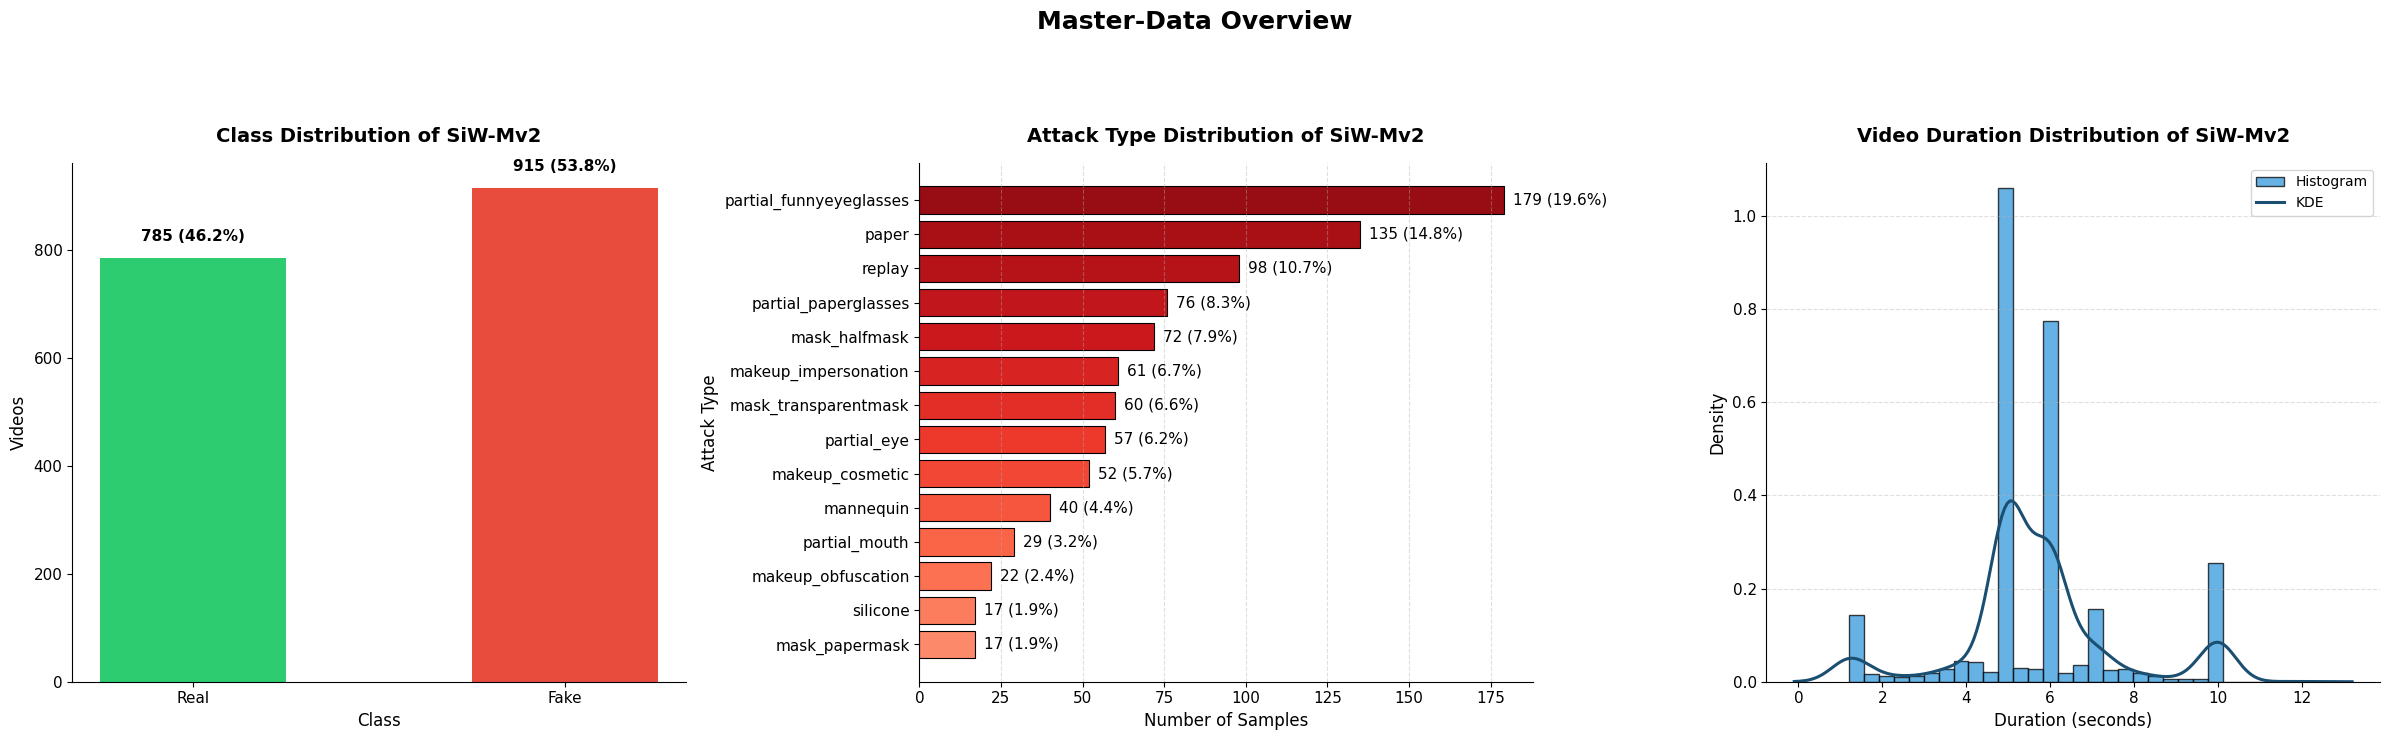

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# -----------------------------
# 1. Prepare data
# -----------------------------
counts = df['label'].value_counts()
total_videos = len(df)

# Only spoof videos for attack-type analysis
fake_df = df[df['label'] == 1]
atypes = fake_df['attack_type'].value_counts()
total_fake = len(fake_df)

# Video duration values
durations = df['duration']

# -----------------------------
# 2. Create subplots
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
fig.suptitle(
    'Master-Data Overview',
    fontsize=18,
    fontweight='bold',
    y=1.05
)

# -----------------------------
# a) Bar chart: Real vs Fake
# -----------------------------
labels = ['Real', 'Fake']
values = [counts.get(0, 0), counts.get(1, 0)]

bars = axes[0].bar(
    labels,
    values,
    color=['#2ECC71', '#E74C3C'],
    width=0.5
)

axes[0].set_title(
    'Class Distribution of SiW-Mv2',
    fontsize=14,
    fontweight='bold',
    pad=15
)
axes[0].set_xlabel('Class', fontsize=12)
axes[0].set_ylabel('Videos', fontsize=12)
axes[0].tick_params(axis='both', labelsize=11)

axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Add count and percentage above each bar
for bar, val in zip(bars, values):
    pct = (val / total_videos) * 100

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        val + total_videos * 0.015,
        f'{val:,} ({pct:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

# -----------------------------
# b) Bar chart: Fake attack types
# -----------------------------
atypes_sorted = atypes.sort_values(ascending=True)

sizes = atypes_sorted.values
attack_labels = atypes_sorted.index
total = sizes.sum()

percentages = (sizes / total) * 100

colors = plt.cm.Reds(
    np.linspace(0.4, 0.9, len(atypes_sorted))
)

axes[1].barh(
    attack_labels,
    sizes,
    color=colors,
    edgecolor='black',
    linewidth=0.8
)

# Add count and percentage beside each bar
for i, (v, p) in enumerate(zip(sizes, percentages)):
    axes[1].text(
        v + max(sizes) * 0.015,
        i,
        f'{v:,} ({p:.1f}%)',
        va='center',
        fontsize=11
    )

axes[1].set_title(
    'Attack Type Distribution of SiW-Mv2',
    fontsize=14,
    fontweight='bold',
    pad=15
)
axes[1].set_xlabel('Number of Samples', fontsize=12)
axes[1].set_ylabel('Attack Type', fontsize=12)
axes[1].tick_params(axis='both', labelsize=11)

axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

axes[1].grid(
    axis='x',
    linestyle='--',
    alpha=0.4
)

# -----------------------------
# c) Histogram + KDE:
#    Video duration distribution
# -----------------------------
axes[2].hist(
    durations,
    bins=30,
    color='#3498DB',
    edgecolor='black',
    alpha=0.75,
    density=True,
    label='Histogram'
)

# KDE curve
sns.kdeplot(
    durations,
    ax=axes[2],
    color='#1B4F72',
    linewidth=2.2,
    label='KDE'
)

axes[2].set_title(
    'Video Duration Distribution of SiW-Mv2',
    fontsize=14,
    fontweight='bold',
    pad=15
)
axes[2].set_xlabel('Duration (seconds)', fontsize=12)
axes[2].set_ylabel('Density', fontsize=12)
axes[2].tick_params(axis='both', labelsize=11)

axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

axes[2].grid(
    axis='y',
    linestyle='--',
    alpha=0.4
)

axes[2].legend(fontsize=10)

# -----------------------------
# 3. Layout and save
# -----------------------------
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    'eda_overview_updated.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Check Face Detector**

In [10]:
from Functions.face_detect_2 import *

# Check ONNXRuntime execution provider
ort_version = ort.__version__
available_providers = ort.get_available_providers()
print("ORT Version:", ort_version)
print("Available ONNXRuntime providers:", available_providers)

# Check SCRFD details
print("Using providers:", SCRFD_PROVIDERS)
print("SCRFD ctx_id:", SCRFD_CTX_ID)

ORT Version: 1.26.0
Available ONNXRuntime providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Using providers: ['CUDAExecutionProvider']
SCRFD ctx_id: 0


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Frame Sampling - Quick Demo Test to check if the main frame sampling function is responding well**

In [18]:
"""
Tests for sample_frames_from_video

Three independent approaches are shown:
  1. Real end-to-end test: build a tiny video with OpenCV, then decode it.
  2. Pure unit test: mock Decord's VideoReader so no real file/codec is needed.
  3. Edge-case tests: empty video and corrupted/unreadable file.

Pick approach 1 for a true end-to-end check through Decord.
Pick approach 2/3 for fast, dependency-free tests (ideal for CI).

The main frame sampling function and the demo tests for it, are all declared at Functions/frame_sampling.py
"""

# Run everything when executed as a script
if __name__ == "__main__":
    test_end_to_end()
    test_padding_when_short()
    test_empty_video()
    test_corrupted_file()
    print("\nAll tests passed.")

Approach 1 (end-to-end) passed.
Approach 2 (padding) passed.
Approach 3a (empty video) passed.
Approach 3b (corrupted file) passed.

All tests passed.


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Extract and Prepare each face from a video frame - Demo Test**

In [19]:
"""
Quick demo test that works from a VIDEO (no separate image needed, no ffmpeg).

It grabs ONE frame from the video, aligns the face, draws the canonical landmark
points on the aligned face, and saves it so it can eyeball that the 5 dots land
on eyes / nose / mouth. Then it runs prepare_video_faces on a few frames.

Usage:
    python demo_face_prep_test_video.py /path/to/video.mp4
"""

# Function present in ./Functions/prepare_faces_from_videos.py

if __name__ == "__main__":
    # Pass the first video path in the dataframe
    vid = df['path'][0]
    test_alignment_visual_from_video(vid)
    test_prepare_video_runs_from_video(vid)
    print("\nDone. Eyeball 'aligned_check.png' for the dot placement.")

Test 1: saved './test_siW_files/aligned_check.png'. Check the 5 red dots land on left eye, right eye, nose, and the two mouth corners.
Test 2: prepare_video_faces ran. mode=aligned, good=6, interp=2, usable_frac=1.00

Done. Eyeball 'aligned_check.png' for the dot placement.


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Verify RGB + FFT + Flow is working fine**

In [20]:
from Functions.FFT_3 import *
from Functions.optical_flow_4 import *

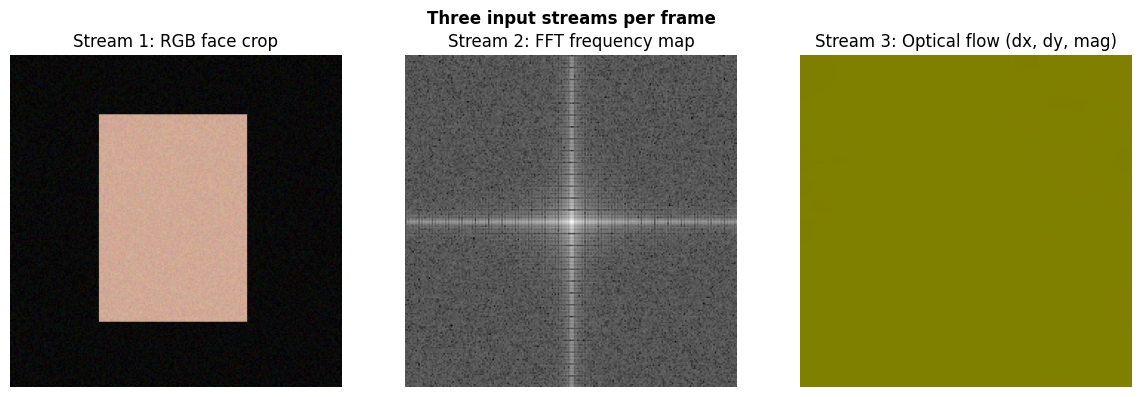

In [21]:
# Visualise the three streams for one demo frame

def visualise_streams():
    np.random.seed(42)  
    # Set random seed so the demo output is always the same

    # Create a blank black image of size 224x224 with 3 color channels
    demo = np.zeros((224, 224, 3), dtype=np.uint8)

    # Add a fake face-like rectangle in skin color
    demo[40:180, 60:160] = [200, 160, 140]

    # Add small random noise to make image look more realistic
    demo += np.random.randint(0, 20, demo.shape, dtype=np.uint8)

    # Create FFT frequency map from the demo face image
    freq = compute_freq_map(demo)

    # Create a second slightly changed frame
    demo2 = demo.copy()

    # Add small random changes to simulate slight movement between frames
    demo2 += np.random.randint(-5, 5, demo.shape, dtype=np.int16).clip(0, 255).astype(np.uint8)

    # Compute optical flow between first and second frame
    flow_maps = compute_optical_flow_sequence([demo, demo2])

    # Create a figure with 3 side-by-side plots
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    # Add main title for the whole figure
    fig.suptitle('Three input streams per frame', fontweight='bold')

    # Show original RGB image
    axes[0].imshow(demo)
    axes[0].set_title('Stream 1: RGB face crop')

    # Show FFT frequency map
    axes[1].imshow(freq)
    axes[1].set_title('Stream 2: FFT frequency map')

    # Show optical flow map
    axes[2].imshow(flow_maps[0])
    axes[2].set_title('Stream 3: Optical flow (dx, dy, mag)')

    # Remove axis numbers/ticks from all images
    for ax in axes:
        ax.axis('off')

    # Adjust spacing so plots fit nicely
    plt.tight_layout()

    # Display the figure
    plt.show()


# Run the visualisation function
visualise_streams()

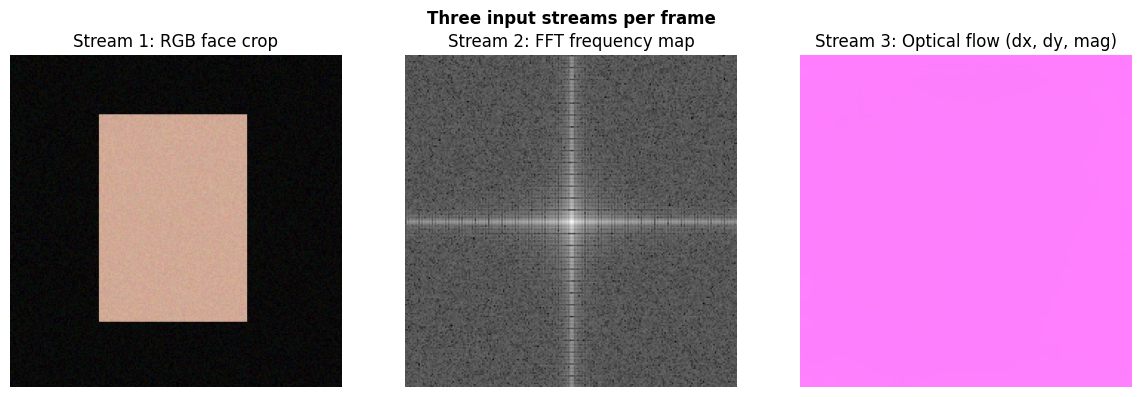

In [22]:
# Visualise the three streams for one demo frame

def visualise_streams():
    np.random.seed(42)  
    # Set random seed so the demo output is always the same

    # Create a blank black image of size 224x224 with 3 color channels
    demo = np.zeros((224, 224, 3), dtype=np.uint8)

    # Add a fake face-like rectangle in skin color
    demo[40:180, 60:160] = [200, 160, 140]

    # Add small random noise to make image look more realistic
    demo += np.random.randint(0, 20, demo.shape, dtype=np.uint8)

    # Create FFT frequency map from the demo face image
    freq = compute_freq_map(demo)

    # Create a second slightly changed frame
    demo2 = demo.copy()

    # Add small random changes to simulate slight movement between frames
    demo2 = np.roll(demo, shift=10, axis=1)   # shift right 10 px = real motion

    # Compute optical flow between first and second frame
    flow_maps = compute_optical_flow_sequence([demo, demo2])

    # Create a figure with 3 side-by-side plots
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    # Add main title for the whole figure
    fig.suptitle('Three input streams per frame', fontweight='bold')

    # Show original RGB image
    axes[0].imshow(demo)
    axes[0].set_title('Stream 1: RGB face crop')

    # Show FFT frequency map
    axes[1].imshow(freq)
    axes[1].set_title('Stream 2: FFT frequency map')

    # Show optical flow map
    axes[2].imshow(flow_maps[0])
    axes[2].set_title('Stream 3: Optical flow (dx, dy, mag)')

    # Remove axis numbers/ticks from all images
    for ax in axes:
        ax.axis('off')

    # Adjust spacing so plots fit nicely
    plt.tight_layout()

    # Display the figure
    plt.show()


# Run the visualisation function
visualise_streams()

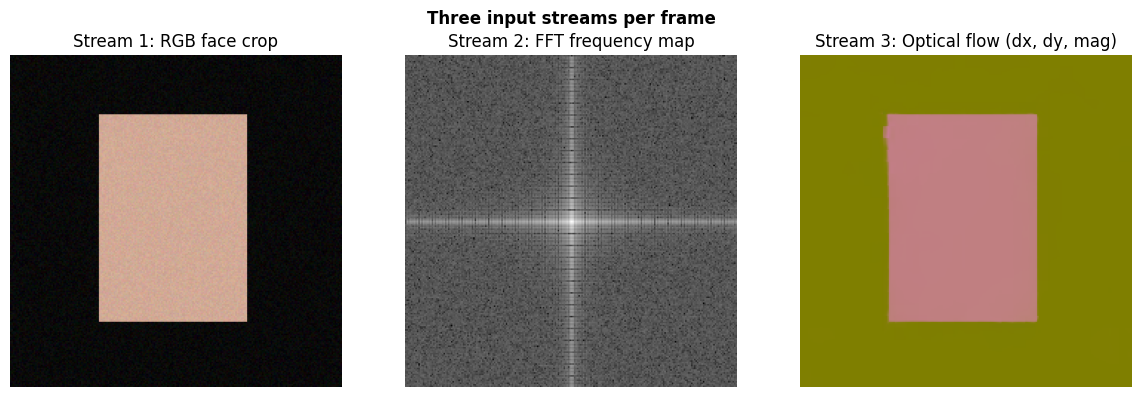

In [23]:
# Visualise the three streams for one demo frame

def visualise_streams():
    np.random.seed(42)  
    # Set random seed so the demo output is always the same

    # Create a blank black image of size 224x224 with 3 color channels
    demo = np.zeros((224, 224, 3), dtype=np.uint8)

    # Add a fake face-like rectangle in skin color
    demo[40:180, 60:160] = [200, 160, 140]

    # Add small random noise to make image look more realistic
    demo += np.random.randint(0, 20, demo.shape, dtype=np.uint8)

    # Create FFT frequency map from the demo face image
    freq = compute_freq_map(demo)

    # Create a second slightly changed frame
    demo2 = demo.copy()

    # Add small random changes to simulate slight movement between frames
    # Move only the "face" region slightly (local motion, like a head shift)
    demo2[40:180, 60:160] = 0                          # clear old position
    demo2[40:180, 65:165] = demo[40:180, 60:160]       # paste shifted right 5 px

    # Compute optical flow between first and second frame
    flow_maps = compute_optical_flow_sequence([demo, demo2])

    # Create a figure with 3 side-by-side plots
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    # Add main title for the whole figure
    fig.suptitle('Three input streams per frame', fontweight='bold')

    # Show original RGB image
    axes[0].imshow(demo)
    axes[0].set_title('Stream 1: RGB face crop')

    # Show FFT frequency map
    axes[1].imshow(freq)
    axes[1].set_title('Stream 2: FFT frequency map')

    # Show optical flow map
    axes[2].imshow(flow_maps[0])
    axes[2].set_title('Stream 3: Optical flow (dx, dy, mag)')

    # Remove axis numbers/ticks from all images
    for ax in axes:
        ax.axis('off')

    # Adjust spacing so plots fit nicely
    plt.tight_layout()

    # Display the figure
    plt.show()


# Run the visualisation function
visualise_streams()

<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Pre-compute all streams before training --and-- load RAFT:**

In [24]:
# Commenting this section of code because precompute is already complete -- DO NOT DELETE THIS CODE


# Clear the cache folder for a fresh precompute run

# for d in [CACHE_DIR_SiW]:
#     d = Path(d)
#     if d.exists():
#         shutil.rmtree(d)                      # delete folder and all contents
#     d.mkdir(parents=True, exist_ok=True)      # recreate empty folder
#     print(f"Cleared and recreated: {d}")

In [25]:
from Functions.precompute_5 import *
from Functions.config import *

# =============================================================================
# Load RAFT-Large, then precompute all streams
# =============================================================================
# RAFT-Large is loaded ONCE (matches the optical-flow function's defaults).
# precompute_and_cache then builds frame/freq/flow + video_meta for every video.
# It only computes uncached videos, so it is safe to re-run if interrupted.

_weights = Raft_Large_Weights.DEFAULT
RAFT_MODEL = raft_large(weights=_weights).eval().to(DEVICE)
RAFT_TRANSFORMS = _weights.transforms()
print(f"RAFT-Large ready on {DEVICE}.")


#################################
# Commenting this section of code because precompute is already complete -- DO NOT DELETE THIS CODE
# precompute_and_cache(df, CACHE_DIR_SiW)

RAFT-Large ready on cuda.


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Check if any checkpoint file still exists in the precompute folder:**

In [26]:
# Precompute folder
pc = CACHE_DIR_SiW / "precompute"

found_checkpoint = False        # track whether any checkpoint was found
for f in pc.iterdir():
    if "checkpoint" in f.name.lower():
        found_checkpoint = True
        print(f.name, "->", "dir" if f.is_dir() else "file")
        if f.is_dir():
            print("   contents:", [c.name for c in f.iterdir()][:5])

# After the loop: report if nothing was found
if not found_checkpoint:
    print("No checkpoint files or folders found in the precompute cache.")

No checkpoint files or folders found in the precompute cache.


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Setup Augmentation**

In [27]:
from Functions.augmentations_6 import *

# Create augmentation pipelines
train_transforms = get_transforms('train')  # training pipeline with augmentations
val_transforms   = get_transforms('val')    # validation pipeline without randomness

<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

<div style="background-color: #C7EA46; padding: 12px; border-radius: 6px;">

## Model Development:

```
VIDEO (T frames)
      │
      ├──────────────────┬──────────────────┐
      ▼                  ▼                  ▼
    [RGB]              [FFT]          [Optical flow]
      │                  │                  │
  CNN encoder        CNN encoder        CNN encoder
  (B, T, 256)        (B, T, 256)        (B, T, 256)
      │                  │                  │
      └──────────────────┼──────────────────┘
                         ▼
            ┌────────────────────────┐
            │  Stream Gate           │
            │  (attention fusion)    │
            │  Learns which stream   │
            │  to trust more         │
            └───────────┬────────────┘
                        │ weighted sum (B, T, 256)
               ┌────────┴────────┐
               ▼                 ▼
          [BiLSTM]        [Transformer]
          (B, 512)           (B, 256)
          sequential       long-range
          patterns          patterns
               └────────┬────────┘
                        ▼
                  [Fusion MLP]
               ┌────────┴────────┐
               ▼                 ▼
            P(fake)           Projection Head
     Real vs Fake score    L2-normalised embedding
        score 0–1          Supports SupCon loss (training only)
```

</div>

<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

### **Sanity Check for full model architechture:**

This code performs a sanity check by running a forward pass with dummy data to verify output shapes and ensure the model architecture works correctly, while also reporting total and trainable parameters.

In [28]:
from Functions.full_model_pipeline_13 import *


# ------------- Model creation -------------------
# Create the model and move it to the device (CPU or GPU) so computations
# happen on the correct hardware.
model = HybridPADModel().to(DEVICE)

# --------- Create dummy input data ----------------
# Random tensors just to test the pipeline (not real images).
# Shape = (B, T, C, H, W):  B=batch, T=frames, C=channels, H,W=frame size.
dummy_rgb  = torch.randn(2, CFG.N_FRAMES, 3, CFG.FRAME_SIZE, CFG.FRAME_SIZE).to(DEVICE)
dummy_freq = torch.randn_like(dummy_rgb)
dummy_flow = torch.randn_like(dummy_rgb)

# ------- Forward pass ------------------------
# Pass fake data through the model to confirm forward() runs without errors.
# Outputs: logits (raw scores), probs (sigmoid), proj (embeddings for SupCon).
model.eval()
with torch.no_grad():
    logits, probs, proj = model(dummy_rgb, dummy_freq, dummy_flow)

# ------- Parameter counting ---------------------
# numel() = number of elements. Count total and trainable (non-frozen) params.
# Useful to gauge model size and confirm freezing worked (RGB backbone frozen).
total_p = sum(p.numel() for p in model.parameters())
train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)

# ------- Print results -------------------------
print('Model test passed.')
print(f'  Logits: {list(logits.shape)}')
print(f'  Probs : {list(probs.shape)}')
print(f'  Proj (SupCon): {list(proj.shape)}')
print(f'  Total params: {total_p/1e6:.1f}M | Trainable: {train_p/1e6:.1f}M')

Model test passed.
  Logits: [2]
  Probs : [2]
  Proj (SupCon): [2, 128]
  Total params: 58.0M | Trainable: 45.6M


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Compound Loss: Focal + SupCon + Aux Depth**

#### Loss formula:
```
L_total = λ_focal * L_focal  +  λ_supcon * L_supcon  +  λ_depth * L_depth
        =   1.0   * L_focal  +    0.3    * L_supcon  +    0.2   * L_depth
```

- **Focal Loss:** Makes correct predictions.
  Predict: 0 for real, 1 for fake.
- **Structure the feature space:** Works on embeddings (features), not labels directly. It pulls real faces in one cluster, fake faces in another cluster. It pushes real and fake faces far apart.
- **Depth Loss:** Uses physical realism. Real faces have 3D structure, so the model learns that. Fake faces are often flat/inconsistent depth.

In [29]:
## Testing the loss function using dummy data

from Functions.loss_functions_14 import *

# Initialise loss function
criterion = CompoundFASLoss()
print('Compound loss ready: Focal + SupCon')

# Create random dummy data
dummy_labels = torch.randint(0, 2, (4,)).to(DEVICE)     # Random labels
dummy_logits = torch.randn(4).to(DEVICE)                # Random predictions
dummy_probs  = torch.sigmoid(dummy_logits)              # logits -> probabilities
dummy_emb    = F.normalize(torch.randn(4, 128), dim=1).to(DEVICE)  # embeddings

# Compute loss (no depth args)
loss_val, loss_components = criterion(
    dummy_logits,
    dummy_probs,
    dummy_emb,
    dummy_labels.float()
)
print(f'Test loss: {loss_val:.4f} | Components: {loss_components}')

Compound loss ready: Focal + SupCon
Test loss: 0.5625 | Components: {'focal': 0.08913817256689072, 'supcon': 1.5777190923690796}


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Optimiser & Scheduler** 

In [30]:
from Functions.optimiser_and_scheduler_15 import *

# Parameter Groups
# Differential LRs: backbone (pretrained) gets 10× smaller LR
# Freq/flow CNNs: train from scratch at full LR
# SupCon proj head: full LR
# NOTE: params wrapped in list() so they can be reused (e.g. by the count print below) without exhausting the generator.
param_groups = [
    {
        # Pretrained RGB backbone (ConvNeXt-Tiny) ; Smaller LR to avoid destroying learned features
        'params': list(model.cnn_rgb.backbone.parameters()), 'lr': CFG.LR * 0.1, 'name': 'rgb_backbone'
    },
    {
        # Projection head for RGB stream (per-stream projector inside the extractor); Trained from scratch -> full LR
        'params': list(model.cnn_rgb.projector.parameters()), 'lr': CFG.LR, 'name': 'rgb_proj'
    },
    {
        # Frequency-domain CNN (FFT features); Trained from scratch -> full LR
        'params': list(model.cnn_freq.parameters()), 'lr': CFG.LR, 'name': 'freq_cnn'
    },
    {
        # Optical flow CNN (motion features) ; Trained from scratch -> full LR
        'params': list(model.cnn_flow.parameters()), 'lr': CFG.LR, 'name': 'flow_cnn'
    },
    {
        # Stream gating module (learns importance of each stream)
        'params': list(model.stream_gate.parameters()), 'lr': CFG.LR, 'name': 'gate'
    },
    {
        # BiLSTM / RNN encoder (temporal modeling)
        'params': list(model.rnn_encoder.parameters()), 'lr': CFG.LR, 'name': 'rnn'
    },
    {
        # Transformer encoder (long-range temporal dependencies)
        'params': list(model.tf_encoder.parameters()), 'lr': CFG.LR, 'name': 'transformer'
    },
    {
        # Final classifier (binary classification head)
        'params': list(model.classifier.parameters()), 'lr': CFG.LR, 'name': 'classifier'
    },
    {
        # Supervised contrastive projection head ; Used to generate embeddings for SupCon loss
        'params': list(model.proj_head.parameters()), 'lr': CFG.LR, 'name': 'supcon_head'
    },
]

# Create optimiser with weight decay (AdamW helps regularization)
optimizer = optim.AdamW(
    param_groups,
    weight_decay=CFG.WEIGHT_DECAY
)

# Initialize LR scheduler (warmup + cosine decay)
scheduler = WarmupCosineScheduler(
    optimizer,
    CFG.WARMUP_EPOCHS,
    CFG.N_EPOCHS,
    CFG.LR
)

# Mixed precision training scaler (prevents gradient underflow)
scaler = torch.amp.GradScaler('cuda')

print('Optimiser ready.')

# Print parameter count per group (useful for debugging & analysis)
for pg in param_groups:
    # Count total parameters in this group
    n = sum(p.numel() for p in pg['params'])

    # Print name, size (in millions), and learning rate
    print(f"  {pg['name']:<20}: {n/1e6:.2f}M params @ LR={pg['lr']:.1e}")

Optimiser ready.
  rgb_backbone        : 27.82M params @ LR=3.0e-05
  rgb_proj            : 0.20M params @ LR=3.0e-04
  freq_cnn            : 4.34M params @ LR=3.0e-04
  flow_cnn            : 21.42M params @ LR=3.0e-04
  gate                : 0.00M params @ LR=3.0e-04
  rnn                 : 2.70M params @ LR=3.0e-04
  transformer         : 1.05M params @ LR=3.0e-04
  classifier          : 0.21M params @ LR=3.0e-04
  supcon_head         : 0.23M params @ LR=3.0e-04


<div style="background-color: #dbeafe; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: blue;">
</div>

## **Model Training and Evaluation per Protocol:**

<div style="background-color: #FFB6C1; padding: 12px; border-radius: 6px;">
    <h2 style="margin: 0;">Protocol 1 – Known Spoof Attacks</h2>
</div>

## **Check the protocol 1 video files**
## **Create the train/val/test splits**
## **Perform some sanity checks**

In [31]:
SEED=42

In [32]:
# ============================================================================
#  PROTOCOL 1  —  Known Spoof Attack Detection  (subject-wise, one-time split)
# ============================================================================
# Official files (each line is a name like "Live1", "Replay23" — NO extension):
#   trainlist_live.txt  -> live train subjects   (shared with Protocol II)
#   trainlist_all.txt   -> spoof train subjects
#   testlist_live.txt   -> live test subjects     (shared with Protocol II)
#   testlist_all.txt    -> spoof test subjects
#
# Matching key: the filename WITHOUT extension (df['subject_id']) must equal
# the names inside the partition files.
# ----------------------------------------------------------------------------


# --- 1. Read the four official partition files ------------------------------
#     (set() de-duplicates the intentional repeated names used for balancing)
def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pc = PROTOCOL_CONFIG_SiW[1]
train_live_ids_P1  = _read_ids(pc['train_live_P1'])
train_spoof_ids_P1 = _read_ids(pc['train_spoof_P1'])
test_live_ids_P1   = _read_ids(pc['test_live_P1'])
test_spoof_ids_P1  = _read_ids(pc['test_spoof_P1'])

# --- 2. Merge live + spoof for train and for test ---------------------------
train_ids_P1 = train_live_ids_P1 | train_spoof_ids_P1
test_ids_P1  = test_live_ids_P1  | test_spoof_ids_P1

# --- 3. Select rows from df by matching the stem ----------------------------
train_full_df_P1 = df[df['subject_id'].isin(train_ids_P1)].copy()
test_df_P1       = df[df['subject_id'].isin(test_ids_P1)].copy()

# --- 3b. Sanity: confirm the names actually matched -------------------------
print('Match check (Protocol 1):')
print(f'  Total no of train-files in the protocol = {len(train_ids_P1):>4} | Total no of videos that actually matched those names = {len(train_full_df_P1):>5}')
print(f'  Total no of test-files in the protocol = {len(test_ids_P1):>4} | Total no of videos that actually matched those names = {len(test_df_P1):>5}')
if len(train_full_df_P1) == 0 or len(test_df_P1) == 0:
    print('  !! WARNING: 0 matched — the split-file names do not match df["subject_id"].')
    print('     Example df stems:', df['subject_id'].head(3).tolist())
    print('     Example file ids :', list(train_ids_P1)[:3])

# --- 4. Carve a SUBJECT-DISJOINT validation set out of TRAIN ----------------
#     Group on the stem so a subject's videos never split across train/val.
gss = GroupShuffleSplit(n_splits=1, test_size=CFG.VAL_RATIO, random_state=SEED)
tr_idx_P1, val_idx_P1 = next(gss.split(train_full_df_P1, groups=train_full_df_P1['subject_id']))

train_df_P1 = train_full_df_P1.iloc[tr_idx_P1].copy()
val_df_P1   = train_full_df_P1.iloc[val_idx_P1].copy()

# --- 5. Report --------------------------------------------------------------
print(f'\nProtocol 1  ->  Train: {len(train_df_P1):,} | Val: {len(val_df_P1):,} | Test: {len(test_df_P1):,}')
print('\nPer-class counts:')
for name, d in [('Train', train_df_P1), ('Val', val_df_P1), ('Test', test_df_P1)]:
    n_real_P1 = (d['label'] == 0).sum()
    n_fake_P1 = (d['label'] == 1).sum()
    print(f'  {name:<5}: real {n_real_P1:>4} | fake {n_fake_P1:>4}')

Match check (Protocol 1):
  Total no of train-files in the protocol = 1064 | Total no of videos that actually matched those names =  1057
  Total no of test-files in the protocol =  627 | Total no of videos that actually matched those names =   623

Protocol 1  ->  Train: 898 | Val: 159 | Test: 623

Per-class counts:
  Train: real  438 | fake  460
  Val  : real   86 | fake   73
  Test : real  261 | fake  362


In [33]:
# Names in the train files but NOT found in your df:
missing_train = train_ids_P1 - set(df['subject_id'])
print(f"{len(missing_train)} train names have no matching video:")
print(missing_train)

# Same for test:
missing_test = test_ids_P1 - set(df['subject_id'])
print(f"{len(missing_test)} test names have no matching video:")
print(missing_test)

7 train names have no matching video:
{'Live_895', 'Live_892', 'Live_894', 'Live_897', 'Live_902', 'Live_901', 'Live_898'}
4 test names have no matching video:
{'Live_899', 'Live_900', 'Live_896', 'Live_893'}


In [34]:
# ============================================================================
#  INVESTIGATE MISSING SUBJECT IDs (train + test)
# ============================================================================
from pathlib import Path

# --- 1. What's missing ---
missing_train = train_ids_P1 - set(df['subject_id'])
missing_test  = test_ids_P1  - set(df['subject_id'])

print(f"Missing train: {len(missing_train)} | Missing test: {len(missing_test)}\n")

# --- 2. Show examples side by side: file names vs df names ---
print("Sample names IN THE PROTOCOL FILE (missing from df):")
print("  ", sorted(missing_test)[:10])
print("\nSample names IN df (subject_id):")
print("  ", sorted(set(df['subject_id']))[:10])

# --- 3. Format comparison — are they the same STYLE? ---
if missing_test:
    example_missing = sorted(missing_test)[0]
    example_df      = sorted(set(df['subject_id']))[0]
    print(f"\nFormat check:")
    print(f"  Missing file name : '{example_missing}'  (len={len(example_missing)})")
    print(f"  df subject_id     : '{example_df}'  (len={len(example_df)})")
    # Check for common mismatch causes
    print(f"  Missing has spaces? {' ' in example_missing}")
    print(f"  Missing has comma?  {',' in example_missing}")   # leftover label prefix?
    print(f"  Missing lowercase?  {example_missing.islower()}")

# --- 4. Is it a genuine missing FILE? Check if the video exists on disk ---
# Adjust the search root to where your OULU videos live
print("\nChecking if missing videos exist on disk:")
for name in sorted(missing_test)[:5]:
    # search for any file matching this name in your data root
    matches = list(REAL_DIR_SiW.parent.rglob(f"*{name}*"))   # adjust root as needed
    if matches:
        print(f"  '{name}' → FOUND on disk: {matches[0].name}  (so it's a MATCHING/format issue)")
    else:
        print(f"  '{name}' → NOT found on disk (genuinely missing video)")

# --- 5. Near-match check: is there a df name that's CLOSE to a missing one? ---
print("\nNear-match check (df names containing the missing name or vice versa):")
df_ids = set(df['subject_id'])
for name in sorted(missing_test)[:5]:
    near = [d for d in df_ids if name in d or d in name]
    print(f"  '{name}' → near matches in df: {near[:3] if near else 'NONE'}")

Missing train: 7 | Missing test: 4

Sample names IN THE PROTOCOL FILE (missing from df):
   ['Live_893', 'Live_896', 'Live_899', 'Live_900']

Sample names IN df (subject_id):
   ['Live_1', 'Live_10', 'Live_100', 'Live_101', 'Live_102', 'Live_103', 'Live_105', 'Live_106', 'Live_107', 'Live_108']

Format check:
  Missing file name : 'Live_893'  (len=8)
  df subject_id     : 'Live_1'  (len=6)
  Missing has spaces? False
  Missing has comma?  False
  Missing lowercase?  False

Checking if missing videos exist on disk:
  'Live_893' → NOT found on disk (genuinely missing video)
  'Live_896' → NOT found on disk (genuinely missing video)
  'Live_899' → NOT found on disk (genuinely missing video)
  'Live_900' → NOT found on disk (genuinely missing video)

Near-match check (df names containing the missing name or vice versa):
  'Live_893' → near matches in df: ['Live_8', 'Live_89']
  'Live_896' → near matches in df: ['Live_8', 'Live_89']
  'Live_899' → near matches in df: ['Live_8', 'Live_89']
 

CHECK 1 — Subject disjointness across splits
Unique subjects -> Train: 898 | Val: 159 | Test: 623

Overlap Train ∩ Val  : 0 subjects
Overlap Train ∩ Test : 0 subjects
Overlap Val   ∩ Test : 0 subjects

PASS — all three splits are subject-disjoint (no leakage).

Videos vs unique subjects per split:
  Train:  898 videos |  898 unique subjects
  Val  :  159 videos |  159 unique subjects
  Test :  623 videos |  623 unique subjects

CHECK 2 — Per-attack distribution across splits


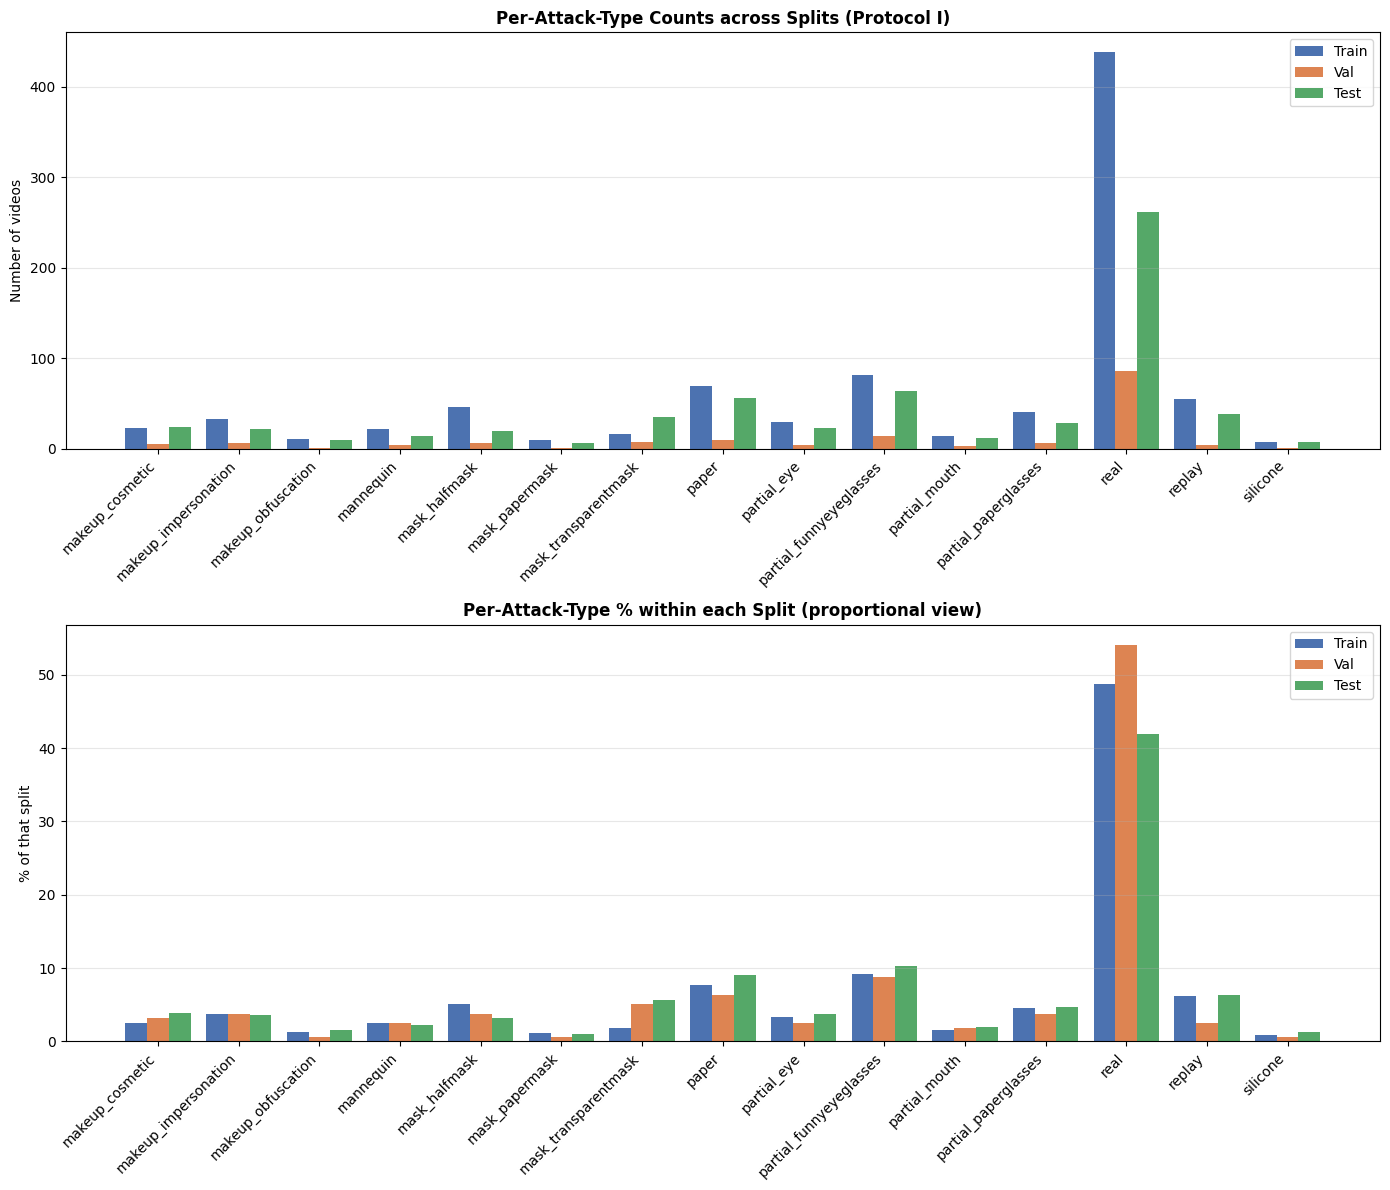


Attack Type                Train     Val    Test
------------------------------------------------
makeup_cosmetic               23       5      24
makeup_impersonation          33       6      22
makeup_obfuscation            11       1      10
mannequin                     22       4      14
mask_halfmask                 46       6      20
mask_papermask                10       1       6
mask_transparentmask          16       8      35
paper                         69      10      56
partial_eye                   30       4      23
partial_funnyeyeglasses       82      14      64
partial_mouth                 14       3      12
partial_paperglasses          41       6      29
real                         438      86     261
replay                        55       4      39
silicone                       8       1       8


In [35]:
## Sanity checks 

# ============================================================================
# CHECK 1 — Subject disjointness across train / val / test
# ============================================================================
# Goal: confirm NO subject appears in more than one split (no leakage).
# We compare the SET of unique subject_ids in each split.
# ----------------------------------------------------------------------------
print('=' * 60)
print('CHECK 1 — Subject disjointness across splits')
print('=' * 60)

train_subj = set(train_df_P1['subject_id'])
val_subj   = set(val_df_P1['subject_id'])
test_subj  = set(test_df_P1['subject_id'])

print(f'Unique subjects -> Train: {len(train_subj)} | Val: {len(val_subj)} | Test: {len(test_subj)}')

# Pairwise overlaps (each MUST be empty for no leakage)
tv  = train_subj & val_subj
tt  = train_subj & test_subj
vt  = val_subj   & test_subj

print(f'\nOverlap Train ∩ Val  : {len(tv)} subjects')
print(f'Overlap Train ∩ Test : {len(tt)} subjects')
print(f'Overlap Val   ∩ Test : {len(vt)} subjects')

if len(tv) == 0 and len(tt) == 0 and len(vt) == 0:
    print('\nPASS — all three splits are subject-disjoint (no leakage).')
else:
    print('\nFAIL — subjects shared across splits (LEAKAGE):')
    if tv: print('   Train∩Val :', list(tv)[:10])
    if tt: print('   Train∩Test:', list(tt)[:10])
    if vt: print('   Val∩Test  :', list(vt)[:10])

# Also confirm no subject is duplicated WITHIN a split at the subject level
# (a subject can have multiple videos which is fine, but let's report it)
print('\nVideos vs unique subjects per split:')
for name, d in [('Train', train_df_P1), ('Val', val_df_P1), ('Test', test_df_P1)]:
    print(f'  {name:<5}: {len(d):>4} videos | {d["subject_id"].nunique():>4} unique subjects')


# ============================================================================
# CHECK 2 — Per-attack-type distribution across the three splits
# ============================================================================
# Goal: see whether each attack type is represented PROPORTIONALLY in
# train / val / test. We plot counts (and also normalized %) side by side.
# ----------------------------------------------------------------------------
print('\n' + '=' * 60)
print('CHECK 2 — Per-attack distribution across splits')
print('=' * 60)

# All attack types present (union across splits), sorted for stable order
all_attacks = sorted(
    set(train_df_P1['attack_type']) |
    set(val_df_P1['attack_type'])   |
    set(test_df_P1['attack_type'])
)

# Count per attack type in each split
def counts_by_attack(d):
    vc = d['attack_type'].value_counts()
    return [int(vc.get(a, 0)) for a in all_attacks]

train_counts = counts_by_attack(train_df_P1)
val_counts   = counts_by_attack(val_df_P1)
test_counts  = counts_by_attack(test_df_P1)

# ---- Plot: grouped bar chart of RAW COUNTS ----
x = np.arange(len(all_attacks))
w = 0.27

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

ax = axes[0]
ax.bar(x - w, train_counts, w, label='Train', color='#4C72B0')
ax.bar(x,     val_counts,   w, label='Val',   color='#DD8452')
ax.bar(x + w, test_counts,  w, label='Test',  color='#55A868')
ax.set_title('Per-Attack-Type Counts across Splits (Protocol I)', fontweight='bold')
ax.set_ylabel('Number of videos')
ax.set_xticks(x); ax.set_xticklabels(all_attacks, rotation=45, ha='right')
ax.legend(); ax.grid(axis='y', alpha=0.3)

# ---- Plot: grouped bar chart of WITHIN-SPLIT % (proportional check) ----
# Each split normalised to its own total -> compare shape, not size.
def pct(counts):
    tot = sum(counts)
    return [100 * c / tot if tot else 0 for c in counts]

ax = axes[1]
ax.bar(x - w, pct(train_counts), w, label='Train', color='#4C72B0')
ax.bar(x,     pct(val_counts),   w, label='Val',   color='#DD8452')
ax.bar(x + w, pct(test_counts),  w, label='Test',  color='#55A868')
ax.set_title('Per-Attack-Type % within each Split (proportional view)', fontweight='bold')
ax.set_ylabel('% of that split')
ax.set_xticks(x); ax.set_xticklabels(all_attacks, rotation=45, ha='right')
ax.legend(); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('split_distribution_check.png', dpi=120, bbox_inches='tight')
plt.show()

# ---- Print the numbers too ----
print(f'\n{"Attack Type":<24}{"Train":>8}{"Val":>8}{"Test":>8}')
print('-' * 48)
for a, tr, vl, te in zip(all_attacks, train_counts, val_counts, test_counts):
    print(f'{a:<24}{tr:>8}{vl:>8}{te:>8}')

label
1    460
0    438
Name: count, dtype: int64
attack_type
real                       438
partial_funnyeyeglasses     82
paper                       69
replay                      55
mask_halfmask               46
partial_paperglasses        41
makeup_impersonation        33
partial_eye                 30
makeup_cosmetic             23
mannequin                   22
mask_transparentmask        16
partial_mouth               14
makeup_obfuscation          11
mask_papermask              10
silicone                     8
Name: count, dtype: int64


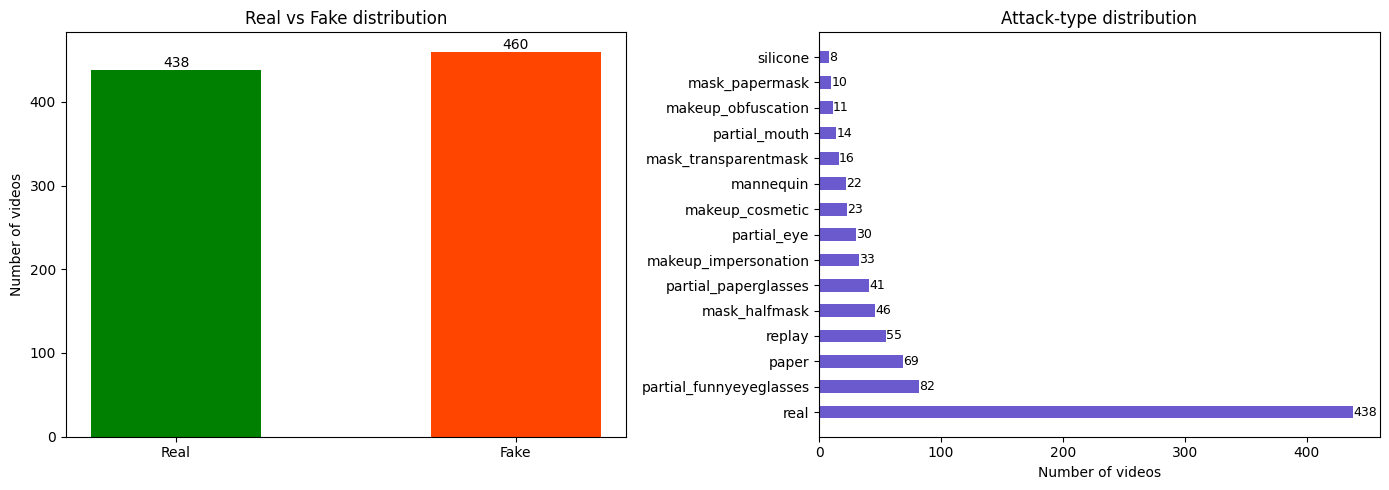

In [36]:
# Real distributions from the full dataframe (not one batch)
print(train_df_P1['label'].value_counts())        # real vs fake counts
print(train_df_P1['attack_type'].value_counts())  # per attack-type counts

import matplotlib.pyplot as plt

# --- Real vs Fake distribution ---
label_counts = train_df_P1['label'].value_counts().sort_index()
# 0 = real, 1 = fake (adjust labels to your convention)

# --- Attack-type distribution ---
attack_counts = train_df_P1['attack_type'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot 1: real vs fake (width=0.5 for narrower bars)
bars0 = axes[0].bar(['Real', 'Fake'], label_counts.values,
                    color=['green', 'orangered'], width=0.5)
axes[0].set_title('Real vs Fake distribution')
axes[0].set_ylabel('Number of videos')
# Put the count on top of each bar
for b in bars0:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height(),
                 f'{int(b.get_height())}', ha='center', va='bottom', fontsize=10)

# Bar plot 2: attack types (horizontal, height=0.5 for narrower bars)
bars1 = axes[1].barh(attack_counts.index, attack_counts.values,
                     color='slateblue', height=0.5)
axes[1].set_title('Attack-type distribution')
axes[1].set_xlabel('Number of videos')
# Put the count at the end of each horizontal bar
for b in bars1:
    axes[1].text(b.get_width(), b.get_y() + b.get_height()/2,
                 f'{int(b.get_width())}', ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 1 - Create train / val / test datasets**

**Each uses proper transforms.**

In [37]:
# Create objects of the data pipeline class

from Functions.data_pipeline_setup_7 import *

# Training dataset:
# Includes augmentation + balanced sampling
train_dataset_P1 = PADVideoDataset(
    train_df_P1,
    real_dir = REAL_DIR_SiW,
    cache_dir = CACHE_DIR_SiW,
    transform=train_transforms,
    demo_mode=False,
    use_freq=CFG.USE_FREQ_STREAM,
    use_flow=CFG.USE_FLOW_STREAM
)

# Validation dataset:
# No augmentation randomness
val_dataset_P1 = PADVideoDataset(
    val_df_P1,
    real_dir = REAL_DIR_SiW,
    cache_dir = CACHE_DIR_SiW,
    transform=val_transforms,
    demo_mode=False,
    use_freq=CFG.USE_FREQ_STREAM,
    use_flow=CFG.USE_FLOW_STREAM
)

# Test dataset:
# Used for final evaluation
test_dataset_P1 = PADVideoDataset(
    test_df_P1,
    real_dir = REAL_DIR_SiW,
    cache_dir = CACHE_DIR_SiW,
    transform=val_transforms,
    demo_mode=False,
    use_freq=CFG.USE_FREQ_STREAM,
    use_flow=CFG.USE_FLOW_STREAM
)

In [38]:
# Grab one sample to confirm shapes and that the cache loads
rgb, freq, flow, label, attack_type, usable_frac = train_dataset_P1[0]
print('rgb :', rgb.shape)    # expect (N_FRAMES, 3, 224, 224)
print('freq:', freq.shape)   # same
print('flow:', flow.shape)   # same
print('label:', label, '| attack:', attack_type, '| usable:', usable_frac)

rgb : torch.Size([16, 3, 224, 224])
freq: torch.Size([16, 3, 224, 224])
flow: torch.Size([16, 3, 224, 224])
label: 0 | attack: real | usable: 0.75


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 1 - Create Data Loaders for creating batches:**

In [39]:
from Functions.weighted_sampler_8 import *

# -------- Create DataLoaders -------------------------------------

# Weighted sampler for balanced batches
train_sampler_P1 = make_weighted_sampler(train_dataset_P1)

# Train loader:
# Random balanced batch sampling
train_loader_P1 = DataLoader(
    train_dataset_P1,
    batch_size=CFG.BATCH_SIZE,           # Batch size = 32
    sampler=train_sampler_P1,            # uses the weighted sampler to balance real/fake videos
    num_workers=2,                       # 2 parallel CPU processes load data in the background
    pin_memory=True,                     # speeds up CPU->GPU transfer
    prefetch_factor=2,                   # each worker preloads 2 batches ahead, so the GPU never waits
    persistent_workers=True              # keep workers alive between epochs (avoids restart overhead)
)

# Validation loader:
# Sequential loading
val_loader_P1 = DataLoader(
    val_dataset_P1,
    batch_size=CFG.BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    prefetch_factor=2,
    persistent_workers=True
)

# Test loader:
# Sequential loading
test_loader_P1 = DataLoader(
    test_dataset_P1,
    batch_size=CFG.BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    prefetch_factor=2,
    persistent_workers=True
)

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **For all the data in Protocol 1, check if the cache files are correctly formed:**

In [40]:
"""
The three levels it checks
For every training video, in order:
Level 1 — Directory exists? Checks if the precompute folder is there at all. If not, records it in missing_dir and skips the file checks (no folder = nothing inside to check).
Level 2 — FFT files complete? Counts freq_*.npy files in the folder. If fewer than N_FRAMES, records it in missing_fft with the actual count.
Level 3 — Flow files complete? Counts flow_*.npy files. If fewer than N_FRAMES, records it in missing_flow with the count.
"""

# ============================================================================
#  CACHE COVERAGE CHECK  —  directories, FFT files, and flow files
# ----------------------------------------------------------------------------
#  For every video in the training split, this verifies three levels of cache
#  completeness:
#     1. the precompute DIRECTORY exists
#     2. all N_FRAMES  freq_*.npy  (FFT) files are present
#     3. all N_FRAMES  flow_*.npy  (optical flow) files are present
#  Any video failing a level triggers the on-the-fly recompute fallback in the
#  dataset (slower, and — for FFT — the source of the CUDA-in-worker crash),
#  so the goal is zero incompletes on every level.
# ============================================================================
from pathlib import Path

missing_dir  = []   # videos with NO precompute folder at all
missing_fft  = []   # videos whose folder exists but freq_*.npy files are incomplete
missing_flow = []   # videos whose folder exists but flow_*.npy files are incomplete

for _, row in train_df_P1.iterrows():
    vid_id  = Path(row['path']).stem
    vid_dir = CACHE_DIR_SiW / "precompute" / vid_id

    # ---- Level 1: does the cache directory exist at all? ----
    if not vid_dir.exists():
        missing_dir.append(vid_id)
        continue                       # no folder -> can't check files inside

    # ---- Level 2: count the FFT (freq) files inside the folder ----
    fft_files = list(vid_dir.glob('freq_*.npy'))
    if len(fft_files) < CFG.N_FRAMES:  # expect one freq file per frame
        missing_fft.append((vid_id, len(fft_files)))

    # ---- Level 3: count the optical-flow files inside the folder ----
    flow_files = list(vid_dir.glob('flow_*.npy'))
    if len(flow_files) < CFG.N_FRAMES: # expect one flow file per frame
        missing_flow.append((vid_id, len(flow_files)))

# ----------------------------------------------------------------------------
#  Report
# ----------------------------------------------------------------------------
total = len(train_df_P1)
print(f"Total training videos           : {total}")
print(f"Missing cache directory         : {len(missing_dir)}")
print(f"Incomplete FFT (freq_*.npy)     : {len(missing_fft)}")
print(f"Incomplete flow (flow_*.npy)    : {len(missing_flow)}")

# Show a few examples for each problem level (only if any exist)
if missing_dir:
    print("\nExamples — missing directory:")
    print("  ", missing_dir[:10])
if missing_fft:
    print("\nExamples — incomplete FFT (vid_id, n_freq_files):")
    print("  ", missing_fft[:10])
if missing_flow:
    print("\nExamples — incomplete flow (vid_id, n_flow_files):")
    print("  ", missing_flow[:10])

# Clean bill of health
if not (missing_dir or missing_fft or missing_flow):
    print("\nAll cache directories, FFT files, and flow files are complete.")

Total training videos           : 898
Missing cache directory         : 0
Incomplete FFT (freq_*.npy)     : 0
Incomplete flow (flow_*.npy)    : 0

All cache directories, FFT files, and flow files are complete.


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 1 - Check if a batch loads successfully:**

In [41]:
# ------------- Check One Batch ----------------------------------------------
# Load one batch to verify pipeline works
rgb_b, freq_b, flow_b, lbl_b, atk_b, uf_b = next(iter(train_loader_P1))
# Print shapes:
# RGB   = (batch, frames, channels, H, W)
# Freq  = (batch, frames, channels, H, W)
# Flow  = (batch, frames, channels, H, W)
print(
    f'Batch shapes: '
    f'RGB={list(rgb_b.shape)}, '
    f'Freq={list(freq_b.shape)}, '
    f'Flow={list(flow_b.shape)}'
)
print(f'Labels={list(lbl_b)} \n attack={atk_b} \n usable_frac={list(uf_b)}')   # label, attack type, usable fraction

Batch shapes: RGB=[32, 16, 3, 224, 224], Freq=[32, 16, 3, 224, 224], Flow=[32, 16, 3, 224, 224]
Labels=[tensor(1), tensor(0), tensor(0), tensor(0), tensor(1), tensor(0), tensor(1), tensor(1), tensor(0), tensor(0), tensor(0), tensor(1), tensor(0), tensor(1), tensor(0), tensor(1), tensor(0), tensor(1), tensor(0), tensor(1), tensor(1), tensor(1), tensor(0), tensor(1), tensor(0), tensor(1), tensor(0), tensor(1), tensor(1), tensor(1), tensor(0), tensor(0)] 
 attack=['makeup_obfuscation', 'real', 'real', 'real', 'paper', 'real', 'makeup_impersonation', 'partial_eye', 'real', 'real', 'real', 'partial_funnyeyeglasses', 'real', 'makeup_cosmetic', 'real', 'replay', 'real', 'replay', 'real', 'partial_paperglasses', 'mask_halfmask', 'makeup_cosmetic', 'real', 'replay', 'real', 'mask_halfmask', 'real', 'makeup_impersonation', 'partial_eye', 'partial_paperglasses', 'real', 'real'] 
 usable_frac=[tensor(1., dtype=torch.float64), tensor(1., dtype=torch.float64), tensor(1., dtype=torch.float64), tensor

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 1 - Check how many of the total videos got letterboxed or aligned, by using their usable fraction**

Collected usable_frac for 898 videos


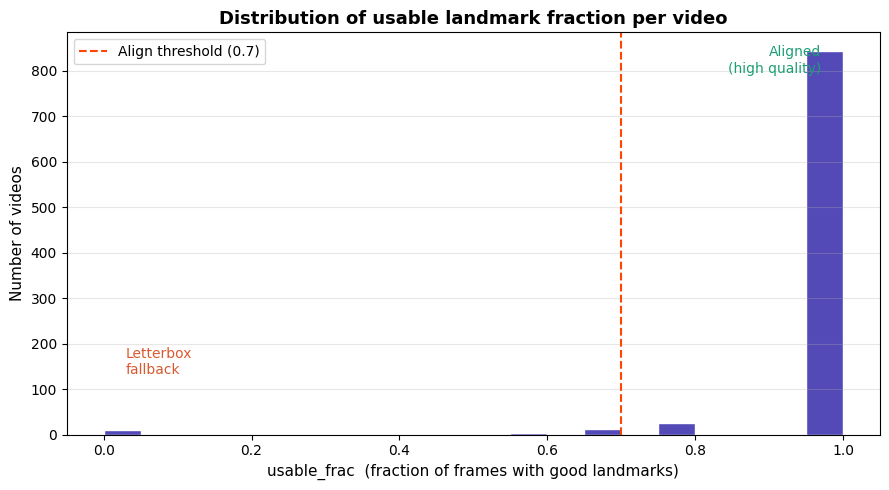

In [42]:
# --- Build the list of usable_frac values from cached video_meta.json ---
fracs = []
for _, row in train_df_P1.iterrows():
    vid_id = Path(row['path']).stem
    mp = CACHE_DIR_SiW / "precompute" / vid_id / "video_meta.json"
    if mp.exists():
        fracs.append(json.load(open(mp))['usable_frac'])

print(f"Collected usable_frac for {len(fracs)} videos")

# --- Plot ---
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(fracs, bins=20, color='#534AB7', edgecolor='white')

ax.set_title('Distribution of usable landmark fraction per video',
             fontsize=13, fontweight='bold')
ax.set_xlabel('usable_frac  (fraction of frames with good landmarks)', fontsize=11)
ax.set_ylabel('Number of videos', fontsize=11)

# Reference line at the align threshold
ax.axvline(CFG.ALIGN_MIN_FRAC, color='orangered', linestyle='--', linewidth=1.5,
           label=f'Align threshold ({CFG.ALIGN_MIN_FRAC})')

# Region annotations
ax.text(0.97, ax.get_ylim()[1] * 0.9, 'Aligned\n(high quality)',
        ha='right', color='#1D9E75', fontsize=10)
ax.text(0.03, ax.get_ylim()[1] * 0.15, 'Letterbox\nfallback',
        ha='left', color='#D85A30', fontsize=10)

ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [43]:
# Collect videos below the align threshold, WITH their attack types
low_videos = []
for _, row in train_df_P1.iterrows():
    vid_id = Path(row['path']).stem
    mp = CACHE_DIR_SiW / "precompute" / vid_id / "video_meta.json"
    if mp.exists():
        uf = json.load(open(mp))['usable_frac']
        if uf < CFG.ALIGN_MIN_FRAC:          # < 0.70 -> letterboxed
            low_videos.append({
                'vid_id': vid_id,
                'label': row['label'],
                'attack_type': row.get('attack_type', 'unknown'),
                'usable_frac': round(uf, 3),
            })

print(f"Total letterboxed (usable_frac < {CFG.ALIGN_MIN_FRAC}): {len(low_videos)}\n")

# Percetage of total videos that were letterboxed
total = len(train_df_P1)
# Percentage to 6 decimal places
pct = (len(low_videos) / total * 100) if total else 0.0
print(f"Total videos      : {total}")
print(f"Letterboxed %%     : {pct:.6f}%")

# Only print the breakdowns if there ARE letterboxed videos
if low_videos:
    # Count per attack type
    attack_counts = Counter(v['attack_type'] for v in low_videos)
    print("\nLetterboxed videos by attack type:")
    for atk, cnt in attack_counts.most_common():
        print(f"  {atk:30s} : {cnt}")

    # Real vs fake split
    label_counts = Counter(v['label'] for v in low_videos)
    print(f"\nBy label: {dict(label_counts)}")

    # Full list
    print("\nIndividual videos:")
    for v in low_videos:
        print(f"  {v['vid_id']:25s} label={v['label']} attack={v['attack_type']:20s} uf={v['usable_frac']}")
else:
    print("\nNo letterboxed videos — all videos met the alignment threshold.")

Total letterboxed (usable_frac < 0.7): 31

Total videos      : 898
Letterboxed %%     : 3.452116%

Letterboxed videos by attack type:
  real                           : 15
  partial_funnyeyeglasses        : 7
  paper                          : 4
  partial_paperglasses           : 2
  mannequin                      : 1
  mask_halfmask                  : 1
  partial_mouth                  : 1

By label: {0: 15, 1: 16}

Individual videos:
  Live_161                  label=0 attack=real                 uf=0.562
  Live_227                  label=0 attack=real                 uf=0.562
  Live_232                  label=0 attack=real                 uf=0.688
  Live_292                  label=0 attack=real                 uf=0.688
  Live_33                   label=0 attack=real                 uf=0.562
  Live_356                  label=0 attack=real                 uf=0.688
  Live_357                  label=0 attack=real                 uf=0.688
  Live_470                  label=0 attack=real  

In [44]:
"""
Diagnostics to confirm the letterbox check is actually reading files (not silently finding nothing):
It checks two things at once: 
(1) how many meta files were actually found, and 
(2) how many of those are letterboxed. 
The first number is the key diagnostic—it confirms the check isn't silently failing.
"""

found = 0
low_videos = []
for _, row in train_df_P1.iterrows():
    vid_id = Path(row['path']).stem
    mp = CACHE_DIR_SiW / "precompute" / vid_id / "video_meta.json"
    if mp.exists():
        found += 1                          # ← count files actually found
        uf = json.load(open(mp))['usable_frac']
        if uf < CFG.ALIGN_MIN_FRAC:
            low_videos.append({...})

print(f"Meta files found: {found} / {len(train_df_P1)}")   # ← the key diagnostic
print(f"Letterboxed: {len(low_videos)}")

Meta files found: 898 / 898
Letterboxed: 31


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 1 - Training Model**

In [41]:
from Functions.run_epochs_17 import *

#--------------------- Take current protocol details -----------------------
ACTIVE_PROTOCOL = 1
pcfg = PROTOCOL_CONFIG_SiW[ACTIVE_PROTOCOL]
BEST_CKPT = pcfg['ckpt']                      # protocol-specific checkpoint (Path to save best model checkpoint)
result_dir = pcfg['result']                   # protocol-specific result
result_dir.mkdir(parents=True, exist_ok=True)


# -------------------- Training History Storage --------------------
# Create a dictionary of empty lists to record metrics for every epoch—losses, ACER, AUC (for both train and val), 
# the loss components, and the learning rate. 
# Append these in each epoch, so the training curve can be analysed later.
history = {
    'train_loss':[], 'val_loss':[],                  # total loss per epoch (train/val)
    'train_acer':[], 'val_acer':[],                  # ACER metric per epoch (train/val)
    'train_bpcer':[], 'val_bpcer':[],                # BPCER metric per epoch (train/val)
    'val_apcer':[],                                  # 
    'train_auc': [], 'val_auc': [],                  # AUC metric per epoch (train/val)
    'focal':[],      'supcon':[],                    # loss component tracking (train only)
    'val_focal':[], 'val_supcon':[],
    'lr': []                                         # learning rate per epoch
}

# -------------------- Early Stopping Setup --------------------
# Track the best validation ACER so far. Starts at infinity (so the first epoch always counts as an improvement). 
# Lower ACER = better.
best_val_acer = float('inf')
# Counts how many epochs have passed without improvement
patience_counter = 0
# If validation doesn't improve for 7 epochs in a row, stop training (early stopping)
PATIENCE = 7


# Start Training time
train_start_time = time.time()   # record start

# -------------------- Training Start Info --------------------
# Print a startup message
print(f'Training for {CFG.N_EPOCHS} epochs | Patience={PATIENCE}')
print('='*80)

# -------------------- Main Training Loop --------------------
# Loop over all epochs
for epoch in range(CFG.N_EPOCHS):
    # Update the learning rate for this epoch (warmup/cosine). Returns the LR(s)
    current_lr = scheduler.step(epoch)

    # -------------------- Training Phase --------------------
    # Training pass: run a full epoch of training. Gets back the average loss, metrics, and loss components. 
    # (The three _ ignore the returned probs/labels/attack types)
    train_loss, train_metrics, _, _, train_comps, _ = run_epoch(
        model, train_loader_P1, optimizer, criterion, DEVICE, scaler, is_train=True, epoch=epoch)

    # -------------------- Validation Phase --------------------
    # Validation pass: run the validation data (no weight updates, scaler=None, is_train=False)
    val_loss, val_metrics, _, _, val_comps, _ = run_epoch(
        model, val_loader_P1, optimizer, criterion, DEVICE, scaler=None, is_train=False, epoch=epoch)

    # -------------------- Store Metrics in History --------------------
    # Record this epoch's losses and metrics into the history.
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acer'].append(train_metrics['ACER'])
    history['val_acer'].append(val_metrics['ACER'])
    history['train_auc'].append(train_metrics['AUC'])
    history['val_auc'].append(val_metrics['AUC'])
    history['train_bpcer'].append(train_metrics['BPCER'])
    history['val_bpcer'].append(val_metrics['BPCER'])
    history['val_apcer'].append(val_metrics['APCER'])
    history['val_focal'].append(val_comps['focal'])
    history['val_supcon'].append(val_comps['supcon'])

    # store loss components (training only)
    history['focal'].append(train_comps['focal'])
    history['supcon'].append(train_comps['supcon'])

    # store learning rate (use the full-rate group for a clean single value)
    history['lr'].append(current_lr[-1] if isinstance(current_lr, (list, tuple)) else current_lr)

    # -------------------- Model Improvement Check --------------------
    # Check if this epoch's validation ACER beat the best so far. If yes, mark it with a "BEST" star in the log.
    improved = val_metrics['ACER'] < best_val_acer
    star = ' * BEST' if improved else ''

    # -------------------- Logging --------------------
    # Print a summary line for this epoch:
    # losses, ACER, AUC, loss components, and the BEST marker.
    print(f"Ep {epoch+1:02d}/{CFG.N_EPOCHS} | "
          f"Loss T:{train_loss:.4f} V:{val_loss:.4f} | "
          f"ACER T:{train_metrics['ACER']:.4f} V:{val_metrics['ACER']:.4f} | "
          f"AUC:{val_metrics['AUC']:.4f} | "
          f"[focal={train_comps['focal']:.3f} supcon={train_comps['supcon']:.3f}]"
          f"{star}")

    # -------------------- Save Best Model --------------------
    # If improved: update the best score, reset patience, and save the model checkpoint to disk.
    if improved:
        # update best score
        best_val_acer = val_metrics['ACER']
        # reset patience counter
        patience_counter = 0
        # save model checkpoint
        torch.save({
            'epoch': epoch+1,
            'state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),   # for resuming
            'scaler_state_dict': scaler.state_dict(),         # for resuming (mixed precision)
            'val_acer': best_val_acer,
            'val_metrics': val_metrics,
            'history': history,                               # training curves
        }, BEST_CKPT)
    
    # If not improved: increment the patience counter. If it hits 7, stop training early
    else:
        # no improvement --> increase patience counter
        patience_counter += 1
        # -------------------- Early Stopping Condition --------------------
        if patience_counter >= PATIENCE:
            print(f'\nEarly stopping at epoch {epoch+1}')
            break

# -------------------- Training Finished --------------------
print(f'\nTraining complete. Best val ACER: {best_val_acer:.4f}')

# Print total training time
# Compute total elapsed time
elapsed = time.time() - train_start_time
hours, rem = divmod(int(elapsed), 3600)
minutes, seconds = divmod(rem, 60)
print(f'Total training time = {hours:02d}:{minutes:02d}:{seconds:02d}')

Training for 30 epochs | Patience=7


Ep 01/30 | Loss T:1.1119 V:1.0573 | ACER T:0.3977 V:0.0965 | AUC:0.9728 | [focal=0.097 supcon=3.384] * BEST


Ep 02/30 | Loss T:0.9175 V:1.1391 | ACER T:0.1278 V:0.0575 | AUC:0.9807 | [focal=0.031 supcon=2.955] * BEST


Ep 03/30 | Loss T:0.8633 V:1.0659 | ACER T:0.0354 V:0.0322 | AUC:0.9976 | [focal=0.022 supcon=2.806] * BEST


Ep 04/30 | Loss T:0.8544 V:1.0384 | ACER T:0.0354 V:0.0428 | AUC:0.9955 | [focal=0.015 supcon=2.798]


Ep 05/30 | Loss T:0.8768 V:1.1186 | ACER T:0.0145 V:0.0342 | AUC:0.9984 | [focal=0.067 supcon=2.699]


... (6 outputs left out)

Ep 12/30 | Loss T:0.7960 V:1.0758 | ACER T:0.0011 V:0.0233 | AUC:0.9990 | [focal=0.001 supcon=2.650]


Ep 13/30 | Loss T:0.8043 V:1.0566 | ACER T:0.0033 V:0.0205 | AUC:0.9992 | [focal=0.003 supcon=2.672]


Ep 14/30 | Loss T:0.8656 V:1.0076 | ACER T:0.0078 V:0.0068 | AUC:0.9998 | [focal=0.054 supcon=2.706]


Ep 15/30 | Loss T:0.8165 V:1.0360 | ACER T:0.0011 V:0.0116 | AUC:0.9998 | [focal=0.028 supcon=2.627]

Early stopping at epoch 15

Training complete. Best val ACER: 0.0068
Total training time = 00:18:56


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 1 - Enhanced Evaluation: Per-Attack-Type Breakdown**

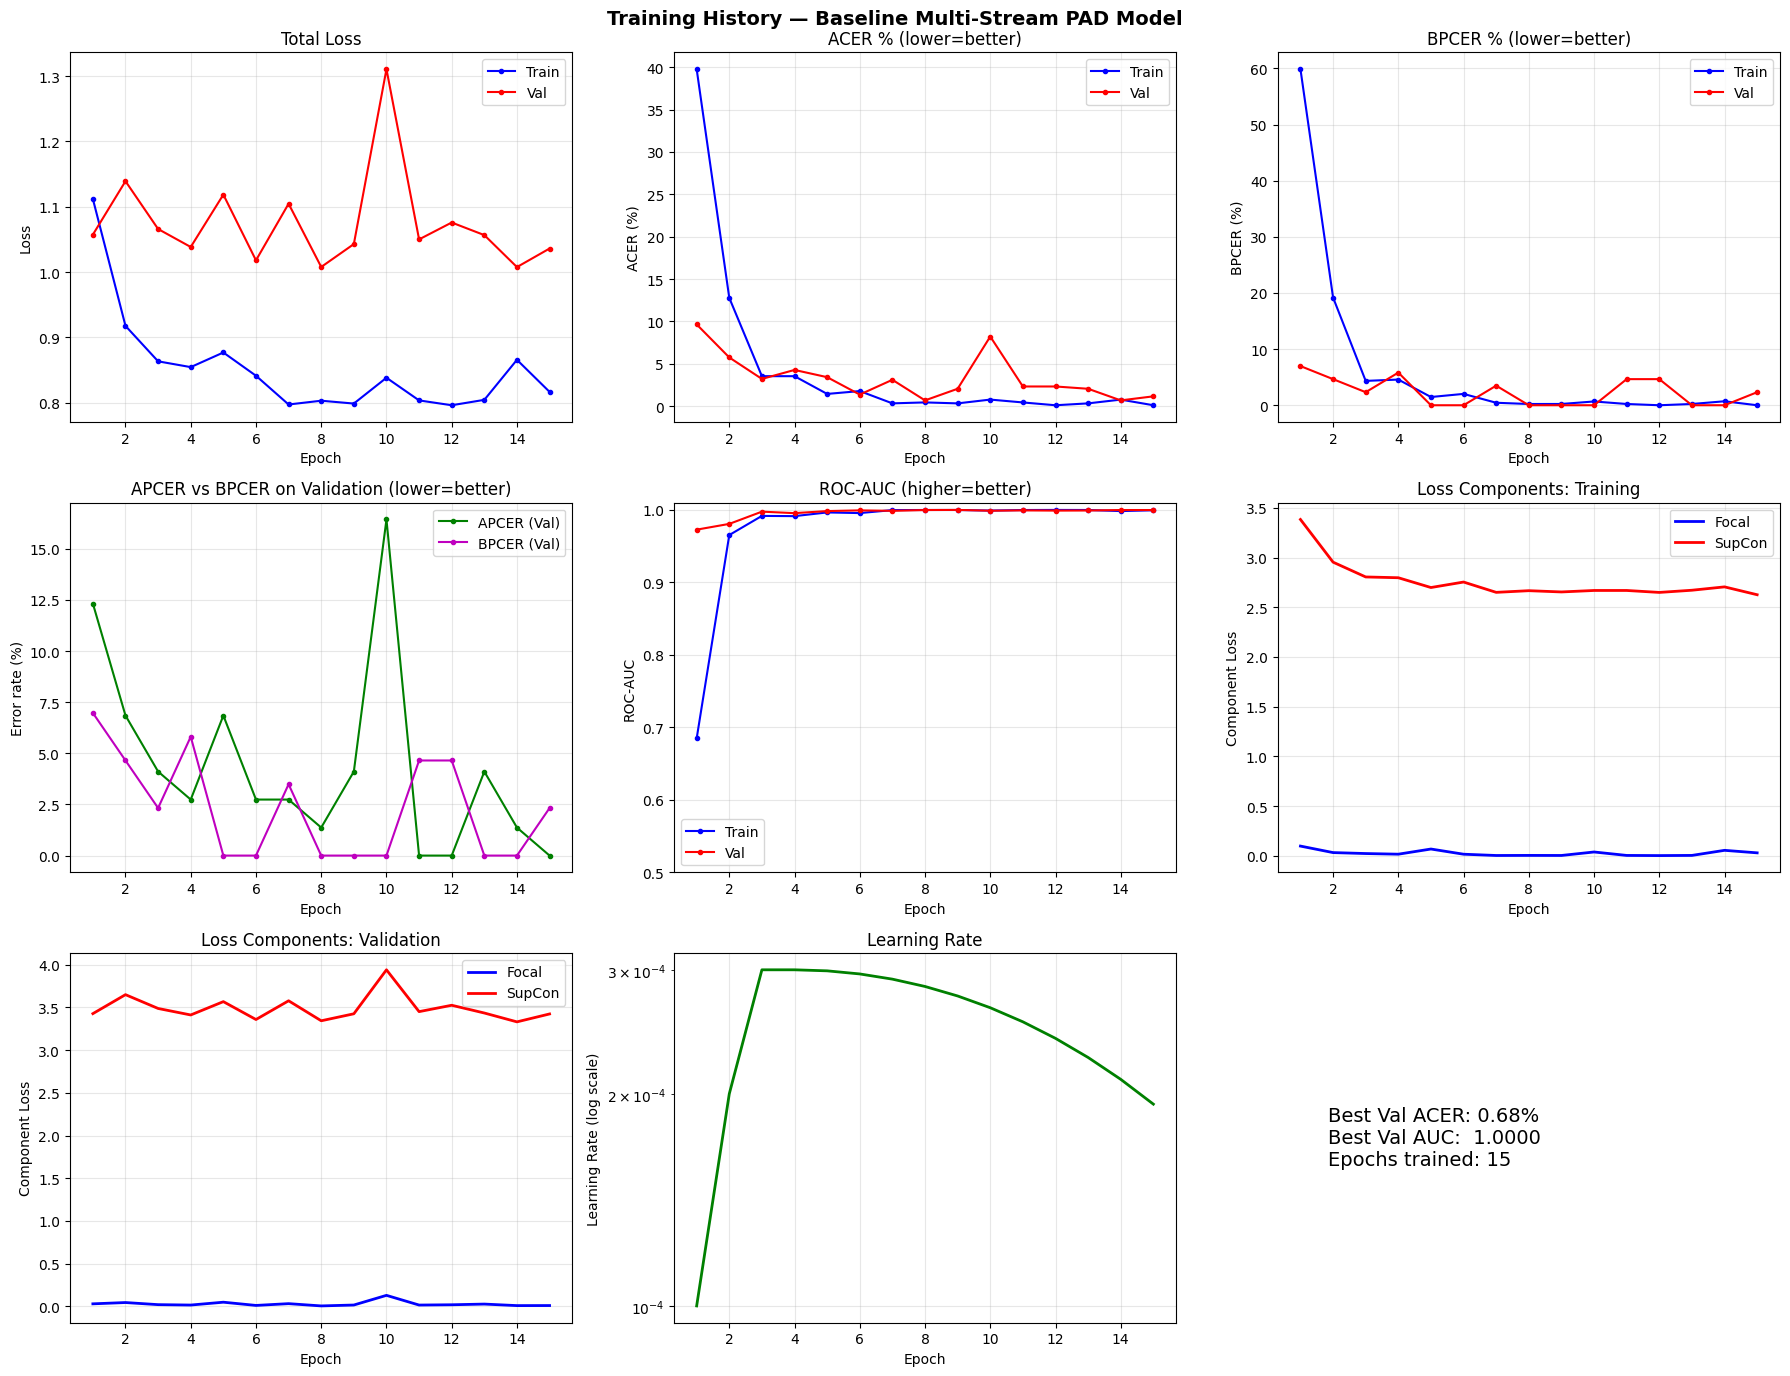

In [42]:
def plot_training_history(history):
    # X-axis values = epoch numbers (1, 2, 3, ...)
    epochs = range(1, len(history['train_loss']) + 1)

    fig, axes = plt.subplots(3, 3, figsize=(18, 14))
    fig.suptitle('Training History — Baseline Multi-Stream PAD Model',
                 fontsize=14, fontweight='bold')

    # ---- [0,0] Total Loss (train vs val) ----
    axes[0, 0].plot(epochs, history['train_loss'], 'b-o', ms=3, label='Train')
    axes[0, 0].plot(epochs, history['val_loss'],   'r-o', ms=3, label='Val')
    axes[0, 0].set_title('Total Loss')
    axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)

    # ---- [0,1] ACER % (train vs val) ----
    axes[0, 1].plot(epochs, [a*100 for a in history['train_acer']], 'b-o', ms=3, label='Train')
    axes[0, 1].plot(epochs, [a*100 for a in history['val_acer']],   'r-o', ms=3, label='Val')
    axes[0, 1].set_title('ACER % (lower=better)')
    axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('ACER (%)')
    axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3)

    # ---- [0,2] BPCER % (train vs val) ----
    axes[0, 2].plot(epochs, [a*100 for a in history['train_bpcer']], 'b-o', ms=3, label='Train')
    axes[0, 2].plot(epochs, [a*100 for a in history['val_bpcer']],   'r-o', ms=3, label='Val')
    axes[0, 2].set_title('BPCER % (lower=better)')
    axes[0, 2].set_xlabel('Epoch'); axes[0, 2].set_ylabel('BPCER (%)')
    axes[0, 2].legend(); axes[0, 2].grid(alpha=0.3)

    # ---- [1,0] APCER vs BPCER % (validation) ----
    axes[1, 0].plot(epochs, [a*100 for a in history['val_apcer']], 'g-o', ms=3, label='APCER (Val)')
    axes[1, 0].plot(epochs, [a*100 for a in history['val_bpcer']], 'm-o', ms=3, label='BPCER (Val)')
    axes[1, 0].set_title('APCER vs BPCER on Validation (lower=better)')
    axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('Error rate (%)')
    axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

    # ---- [1,1] ROC-AUC (train vs val) ----
    axes[1, 1].plot(epochs, history['train_auc'], 'b-o', ms=3, label='Train')
    axes[1, 1].plot(epochs, history['val_auc'],   'r-o', ms=3, label='Val')
    axes[1, 1].set_title('ROC-AUC (higher=better)')
    axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('ROC-AUC')
    axes[1, 1].set_ylim([0.5, 1.01])
    axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

    # ---- [1,2] Loss Components: Training ----
    axes[1, 2].plot(epochs, history['focal'],  'b-', lw=2, label='Focal')
    axes[1, 2].plot(epochs, history['supcon'], 'r-', lw=2, label='SupCon')
    axes[1, 2].set_title('Loss Components: Training')
    axes[1, 2].set_xlabel('Epoch'); axes[1, 2].set_ylabel('Component Loss')
    axes[1, 2].legend(); axes[1, 2].grid(alpha=0.3)

    # ---- [2,0] Loss Components: Validation ----
    axes[2, 0].plot(epochs, history['val_focal'],  'b-', lw=2, label='Focal')
    axes[2, 0].plot(epochs, history['val_supcon'], 'r-', lw=2, label='SupCon')
    axes[2, 0].set_title('Loss Components: Validation')
    axes[2, 0].set_xlabel('Epoch'); axes[2, 0].set_ylabel('Component Loss')
    axes[2, 0].legend(); axes[2, 0].grid(alpha=0.3)

    # ---- [2,1] Learning Rate (log scale) ----
    axes[2, 1].plot(epochs, history['lr'], 'g-', lw=2)
    axes[2, 1].set_title('Learning Rate')
    axes[2, 1].set_xlabel('Epoch'); axes[2, 1].set_ylabel('Learning Rate (log scale)')
    axes[2, 1].set_yscale('log')
    axes[2, 1].grid(alpha=0.3)

    # ---- [2,2] Summary text box (no axes) ----
    axes[2, 2].axis('off')
    text  = f"Best Val ACER: {min(history['val_acer'])*100:.2f}%\n"
    text += f"Best Val AUC:  {max(history['val_auc']):.4f}\n"
    text += f"Epochs trained: {len(epochs)}"
    axes[2, 2].text(0.1, 0.5, text, transform=axes[2, 2].transAxes,
                    fontsize=14, verticalalignment='center')

    plt.tight_layout()
    plt.savefig('training_history_baseline.png', dpi=120, bbox_inches='tight')
    plt.show()


plot_training_history(history)

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 1 - Load best model and evaluate on test set**

In [45]:
# =================== Load best model and evaluate on the TEST set ===================================================
# Loads the best checkpoint saved during training, runs ONE pass over the test
# set (unseen data), then finds the decision threshold that minimises ACER and
# reports the final metrics at that threshold.

# --- 1. Load the best checkpoint (if it exists) -------------------------------
if BEST_CKPT.exists():
    # Read the checkpoint file onto the current device
    ckpt = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
    # Restore the model's trained weights
    model.load_state_dict(ckpt['state_dict'])
    # The print confirms which epoch's model loaded.
    print(f'Loaded best checkpoint (epoch {ckpt["epoch"]}, val ACER={ckpt["val_acer"]:.4f})')
else:
    # No checkpoint -> warn, but still evaluate whatever is currently in `model`
    print('[WARNING] No best checkpoint found; evaluating current in-memory model.')

# --- 2. Run one evaluation pass over the validation set -----------------------------
# is_train=False -> no weight updates, no gradients (pure evaluation).
# scaler=None    -> plain FP32 inference.
# take the loss, metrics, the predicted probabilities (val_probs) and (val_labels); 
# ignore the loss-component dict (using _)
# Take the attacks types for further anyalysis later
val_loss, val_metrics, val_probs, val_labels, _, _ = run_epoch(
    model, val_loader_P1, optimizer, criterion, DEVICE, scaler=None, is_train=False)


# --- 3. Find the threshold that minimises ACER --------------------------------
# The model outputs probabilities (0–1), but we need a cut-off to decide real vs. fake. 
# Instead of assuming 0.5, this step tries 100 thresholds from 0.1 to 0.9, computes ACER at each, 
# and picks the one with the lowest ACER (np.argmin finds the index of the minimum). 
# This finds the optimal decision boundary for the model.
val_labels_int = val_labels.round().astype(int)                                                 # ensure integer labels
thresholds = np.linspace(0.1, 0.9, 100)                                                         # 100 candidate cut-offs
val_acers = [compute_pad_metrics(val_labels_int, val_probs, t)['ACER'] for t in thresholds]
best_thresh = thresholds[np.argmin(val_acers)]                                                  # threshold with lowest ACER

# --- 4. Compute final metrics at the chosen threshold -------------------------
# Run test pass
test_loss, test_metrics, test_probs, test_labels, _, test_attacks = run_epoch(
    model, test_loader_P1, optimizer, criterion, DEVICE, scaler=None, is_train=False)
test_labels_int = test_labels.round().astype(int)
opt_metrics = compute_pad_metrics(test_labels_int, test_probs, threshold=best_thresh)

# --- 5. Report ----------------------------------------------------------------
# Print each metric as a percentage, labeled with whether higher or lower is better
print(f'\nOptimal Threshold = {best_thresh:.3f}')
print('=' * 50)
for k, v in opt_metrics.items():
    # Label each metric with its "good" direction for readability
    direction = 'lower=better' if k in ['APCER', 'BPCER', 'ACER'] else 'higher=better'
    print(f'  {k:8s}: {v*100:.2f}%  ({direction})')


# --- 6. Save results to the protocol's result folder ---
result_dir = PROTOCOL_CONFIG_SiW[1]['result']
result_dir.mkdir(parents=True, exist_ok=True)

# Save the metrics as JSON
results_to_save = {
    'protocol': 1,
    'best_threshold': float(best_thresh),
    'test_metrics': {k: float(v) for k, v in opt_metrics.items()},
    'checkpoint_epoch': int(ckpt['epoch']) if BEST_CKPT.exists() else None,
}
with open(result_dir / 'test_metrics.json', 'w') as f:
    json.dump(results_to_save, f, indent=2)

print(f'\nResults saved to {result_dir / "test_metrics.json"}')

Loaded best checkpoint (epoch 8, val ACER=0.0068)



Optimal Threshold = 0.100
  APCER   : 2.49%  (lower=better)
  BPCER   : 0.77%  (lower=better)
  ACER    : 1.63%  (lower=better)
  Acc     : 98.23%  (higher=better)
  AUC     : 99.61%  (higher=better)

Results saved to output_siW/results/protocol_1/test_metrics.json


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 1 - Per attack result: APCER/ACER/TDR@1%, along with shared BPCER:**

In [47]:
# ============================================================================
#  PROTOCOL I — Per-Attack ACER + TDR table (paper format)
# ----------------------------------------------------------------------------
#  It reuses the test predictions produced there: 
#  test_probs / test_labels / test_attacks / best_thresh. 
#  Also needs compute_tdr_at_fdr() and the (fixed) metric defs.
#
#  Why ACER is computed this way:
#    ACER needs APCER (a SPOOF error) and BPCER (a REAL error). But "real"
#    faces are not attack-specific, so there is no per-attack BPCER. Following
#    the paper, each attack's ACER pairs THAT attack's APCER with the ONE
#    shared overall BPCER:  per-attack ACER = (attack APCER + overall BPCER)/2
# ============================================================================

# ---- Pull predictions into plain arrays (aligned per test sample) ----------
probs   = np.asarray(test_probs)                       # spoof probability, 0..1
labels  = np.asarray(test_labels).round().astype(int)  # ground truth: 0=real, 1=spoof
attacks = np.asarray(test_attacks)                     # attack-type string per sample
preds   = (probs >= best_thresh).astype(int)           # hard decision at the chosen threshold

# Strings that mean "real / bona-fide" in the attack_type column
REAL_NAMES = {'real', 'live', 'Real', 'Live'}

# ---- Split every sample into real vs spoof --------------------------------
# A sample is "real" if its attack_type says so OR its label is 0 (belt & braces).
is_real    = np.isin(attacks, list(REAL_NAMES)) | (labels == 0)
real_mask  = is_real
spoof_mask = ~is_real

# ---- Overall BPCER (shared by every attack) -------------------------------
# BPCER = real faces wrongly rejected as spoof  /  total real faces.
# This is computed ONCE and reused in every attack's ACER.
n_real        = real_mask.sum()
real_rejected = ((preds == 1) & real_mask).sum()       # real predicted as spoof
overall_bpcer = real_rejected / (n_real + 1e-8)        # 1e-8 guards divide-by-zero

# All real faces' probs/labels — reused for each attack's TDR computation
real_probs  = probs[real_mask]
real_labels = labels[real_mask]                        # all zeros

# ---- Per-attack metrics ----------------------------------------------------
rows = []
spoof_attack_names = sorted(set(attacks[spoof_mask].tolist()))   # the 14 attack types

for atk in spoof_attack_names:
    # Mask selecting only THIS attack's spoof samples
    m = (attacks == atk) & spoof_mask
    n_atk = m.sum()
    if n_atk == 0:
        continue                                       # skip attacks with no samples

    # APCER for this attack = its spoofs that slipped through (predicted real)
    #                         / its total spoofs
    atk_passed = ((preds == 0) & m).sum()              # this attack's spoofs called "real"
    atk_apcer  = atk_passed / (n_atk + 1e-8)

    # Per-attack ACER = (this attack's APCER + the shared overall BPCER) / 2
    atk_acer = (atk_apcer + overall_bpcer) / 2

    # Per-attack TDR@FDR=1%: evaluate this attack's spoofs against ALL real faces
    # (a 2-class problem: reals=0, this-attack=1), at a 1% false-alarm budget.
    combo_probs  = np.concatenate([real_probs,  probs[m]])
    combo_labels = np.concatenate([real_labels, labels[m]])
    atk_tdr = compute_tdr_at_fdr(combo_labels, combo_probs, target_fdr=0.01)

    rows.append({'attack': atk, 'n': int(n_atk),
                 'APCER': atk_apcer * 100, 'ACER': atk_acer * 100, 'TDR': atk_tdr})

# ---- Overall row (all spoofs pooled together) -----------------------------
overall_apcer = ((preds == 0) & spoof_mask).sum() / (spoof_mask.sum() + 1e-8)
overall_acer  = (overall_apcer + overall_bpcer) / 2
overall_tdr   = compute_tdr_at_fdr(labels, probs, target_fdr=0.01)   # all real + all spoof

# ---- Print the table -------------------------------------------------------
print(f"{'Attack':<24}{'n':>5}{'APCER%':>9}{'ACER%':>9}{'TDR@1%':>9}")
print('-' * 56)
for r in rows:
    print(f"{r['attack']:<24}{r['n']:>5}{r['APCER']:>9.2f}{r['ACER']:>9.2f}{r['TDR']:>9.2f}")
print('-' * 56)
print(f"{'OVERALL':<24}{spoof_mask.sum():>5}{overall_apcer*100:>9.2f}"
      f"{overall_acer*100:>9.2f}{overall_tdr:>9.2f}")
# BPCER is the same for every attack, so print it once at the bottom
print(f"\nShared overall BPCER (real rejected): {overall_bpcer*100:.2f}%")

# ---- Save for the final paper-format comparison table ----------------------
protocol1_per_attack = {
    'per_attack': rows,
    'overall': {'APCER': overall_apcer * 100, 'BPCER': overall_bpcer * 100,
                'ACER': overall_acer * 100, 'TDR': overall_tdr},
}

# Get the protocol-specific results folder
result_dir = PROTOCOL_CONFIG_SiW[ACTIVE_PROTOCOL]['result']
result_dir.mkdir(parents=True, exist_ok=True)

# ---- Save the structured data as JSON ----
with open(result_dir / 'per_attack_result_metrics_protocol_1.json', 'w') as f:
    json.dump(protocol1_per_attack, f, indent=2)

print(f"\nSaved per-attack table to {result_dir / 'per_attack_result_metrics_protocol_1.json'}")

Attack                      n   APCER%    ACER%   TDR@1%
--------------------------------------------------------
makeup_cosmetic            24     0.00     0.38   100.00
makeup_impersonation       22     0.00     0.38   100.00
makeup_obfuscation         10    20.00    10.38    80.00
mannequin                  14     0.00     0.38   100.00
mask_halfmask              20     0.00     0.38   100.00
mask_papermask              6     0.00     0.38   100.00
mask_transparentmask       35    11.43     6.10    94.29
paper                      56     0.00     0.38   100.00
partial_eye                23     0.00     0.38   100.00
partial_funnyeyeglasses    64     0.00     0.38   100.00
partial_mouth              12     0.00     0.38   100.00
partial_paperglasses       29     0.00     0.38   100.00
replay                     39     7.69     4.23    97.44
silicone                    8     0.00     0.38   100.00
--------------------------------------------------------
OVERALL                   362  

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **ROC + Confusion Matrix**

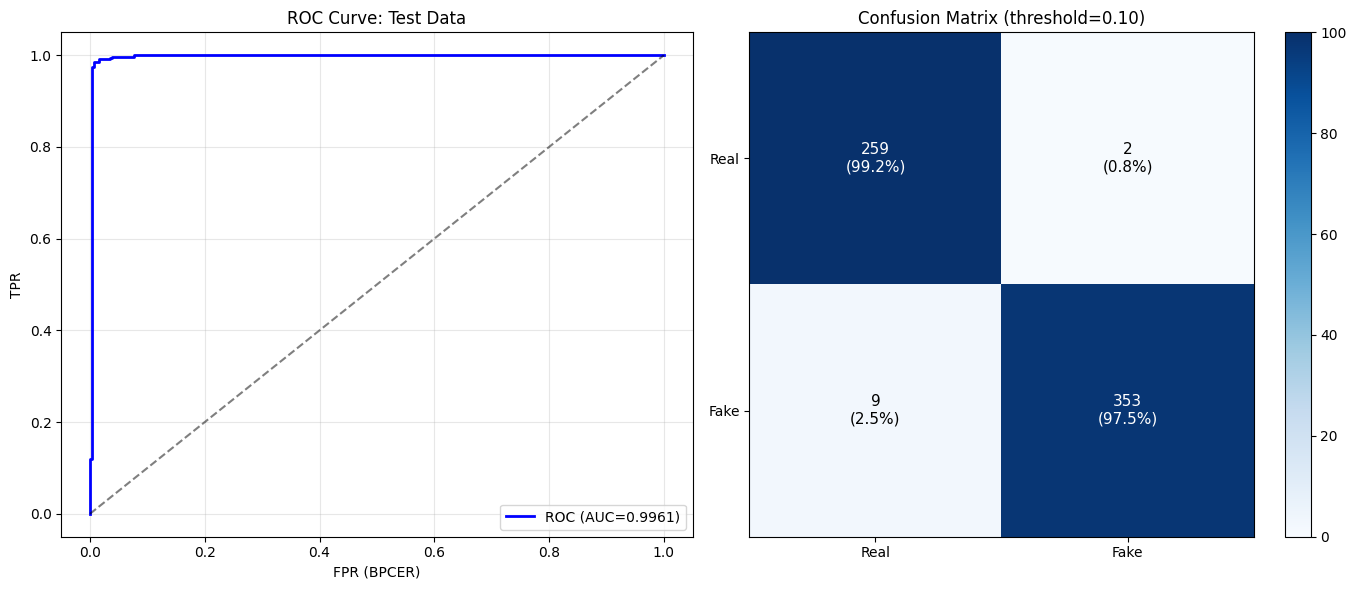

In [49]:
# ============== ROC + Confusion Matrix =================================================
# Two diagnostic plots side by side from the TEST predictions:
#   Left  : ROC curve (TPR vs FPR across thresholds) with the AUC score.
#   Right : Confusion matrix at the chosen threshold (counts + row-%).
# Requires: from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# Make sure the protocol result folder exists
result_dir = PROTOCOL_CONFIG_SiW[1]['result']
result_dir.mkdir(parents=True, exist_ok=True)

# Create a 1-row, 2-column figure
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ----- Left panel: ROC curve -------------------------------------------------
# roc_curve returns the false-positive rate, true-positive rate, and the
# thresholds it swept (we ignore the thresholds with '_').
fpr, tpr, _ = roc_curve(test_labels.round().astype(int), test_probs)
# Area under the ROC curve (1.0 = perfect, 0.5 = random)
auc_score = roc_auc_score(test_labels.round().astype(int), test_probs)
# Plot the ROC curve
axes[0].plot(fpr, tpr, 'b-', lw=2, label=f'ROC (AUC={auc_score:.4f})')
# Diagonal reference line = random-guess baseline
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title('ROC Curve: Test Data')
axes[0].set_xlabel('FPR (BPCER)')      # x-axis: false positive rate
axes[0].set_ylabel('TPR')              # y-axis: true positive rate

# ----- Right panel: Confusion matrix -----------------------------------------
# Turn probabilities into hard 0/1 predictions using the chosen threshold
y_pred = (test_probs >= best_thresh).astype(int)
# Raw confusion-matrix counts (rows = true class, cols = predicted class)
cm = confusion_matrix(test_labels.round().astype(int), y_pred)
# Convert each ROW to percentages (so each true class sums to 100%)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
# Draw the matrix as a heatmap (0–100% colour scale)
im = axes[1].imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
plt.colorbar(im, ax=axes[1])
# Label the axes with class names (0=Real, 1=Fake)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['Real', 'Fake'])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(['Real', 'Fake'])
# Write the count + percentage inside each cell
for i in range(2):
    for j in range(2):
        axes[1].text(
            j, i, f'{cm[i,j]:,}\n({cm_pct[i,j]:.1f}%)',
            ha='center', va='center',
            # white text on dark cells, black on light cells, for readability
            color='white' if cm_pct[i, j] > 50 else 'black',
            fontsize=11
        )
axes[1].set_title(f'Confusion Matrix (threshold={best_thresh:.2f})')

# Lay out, save, and display
plt.tight_layout()
plt.savefig(result_dir / 'roc_confusion_protocol_1.png', dpi=120, bbox_inches='tight')
plt.show()

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

### **Protocol 1 - Per-attack-type misclassification bar chart (TEST set)**

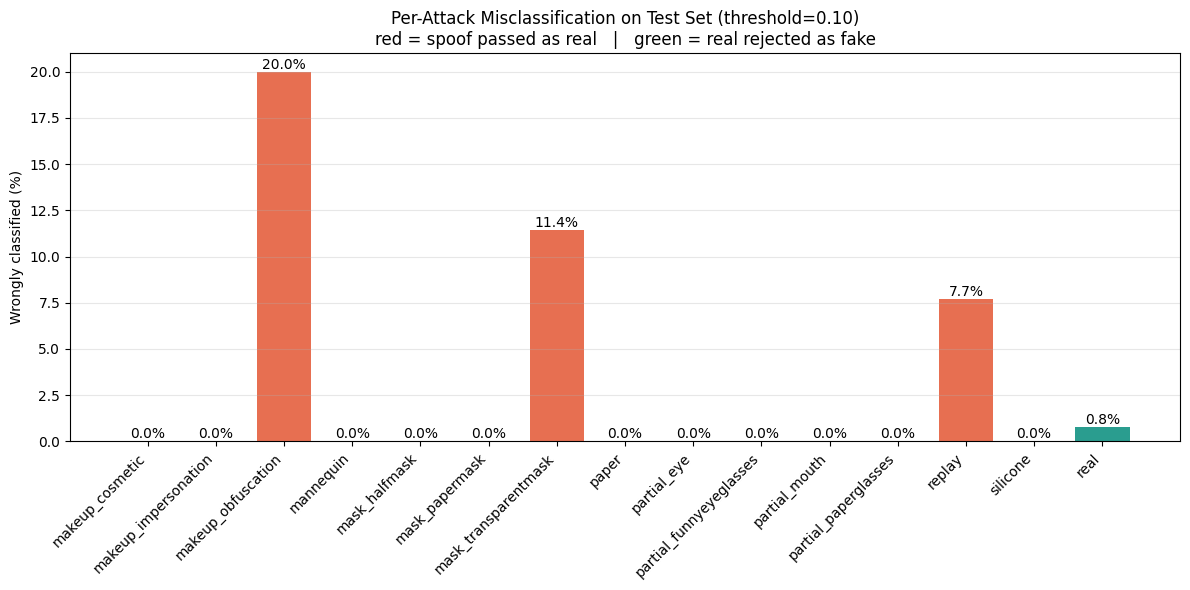

Category                 Wrong %
makeup_cosmetic             0.00   (spoof passed)
makeup_impersonation        0.00   (spoof passed)
makeup_obfuscation         20.00   (spoof passed)
mannequin                   0.00   (spoof passed)
mask_halfmask               0.00   (spoof passed)
mask_papermask              0.00   (spoof passed)
mask_transparentmask       11.43   (spoof passed)
paper                       0.00   (spoof passed)
partial_eye                 0.00   (spoof passed)
partial_funnyeyeglasses      0.00   (spoof passed)
partial_mouth               0.00   (spoof passed)
partial_paperglasses        0.00   (spoof passed)
replay                      7.69   (spoof passed)
silicone                    0.00   (spoof passed)
real                        0.77   (real rejected)


<Figure size 640x480 with 0 Axes>

In [51]:
# ------------- Per-attack-type misclassification bar chart (TEST set) ------------------------------
# Each SPOOF attack type -> % of that type misclassified as REAL (spoof passed through).
# REAL (bona-fide) -> % of real faces misclassified as FAKE -> shown as a SEPARATE
# bar at the END in a different colour.
#
# Requires (aligned per test sample):
#   test_probs, test_labels (0=real, 1=fake), test_attacks, best_thresh
#
# How "real" is identified: any attack-type string in REAL_NAMES is treated as the
# bona-fide/real class. Adjust REAL_NAMES to match your dataset's label for real
# (commonly 'Live', 'Real', or 'live').


# --- which attack-type string(s) mean "real" ---
REAL_NAMES = {'Live', 'Real', 'live', 'real', 'genuine', 'bonafide', 'Bona-fide'}

probs   = np.asarray(test_probs)
labels  = np.asarray(test_labels).round().astype(int)
attacks = np.asarray(test_attacks)
preds   = (probs >= best_thresh).astype(int)

spoof_names, spoof_errs = [], []
real_err, real_name = None, 'Real'

for atk in sorted(set(attacks.tolist())):
    m = attacks == atk
    atk_preds = preds[m]

    # Decide real vs spoof primarily by the name; fall back to label majority.
    is_real = (atk in REAL_NAMES) or (labels[m].mean() < 0.5)

    if is_real:
        # % of real faces wrongly called FAKE (predicted 1)
        real_err  = float(np.mean(atk_preds == 1) * 100)
        real_name = atk
    else:
        # % of this spoof type wrongly called REAL (predicted 0) -> passed through
        spoof_names.append(atk)
        spoof_errs.append(float(np.mean(atk_preds == 0) * 100))

# Spoof bars first, then the Real bar last
names  = spoof_names + ([real_name] if real_err is not None else [])
errs   = spoof_errs  + ([real_err]  if real_err is not None else [])
colors = ['#e76f51'] * len(spoof_names) + (['#2a9d8f'] if real_err is not None else [])

# ----- Plot -----
plt.figure(figsize=(12, 6))
bars = plt.bar(names, errs, color=colors)
plt.ylabel('Wrongly classified (%)')
plt.title(f'Per-Attack Misclassification on Test Set (threshold={best_thresh:.2f})\n'
          'red = spoof passed as real   |   green = real rejected as fake')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
for b, e in zip(bars, errs):
    plt.text(b.get_x() + b.get_width()/2, b.get_height(),
             f'{e:.1f}%', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

# ----- Print the numbers -----
print(f"{'Category':<22}{'Wrong %':>10}")
print('=' * 34)
for nm, e in zip(names, errs):
    tag = '(real rejected)' if nm == real_name else '(spoof passed)'
    print(f'{nm:<22}{e:>10.2f}   {tag}')

#---- Save results ----
result_dir = PROTOCOL_CONFIG_SiW[1]['result']
result_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(result_dir / 'per_attack_barchart_protocol_1.png', dpi=120, bbox_inches='tight')

In [52]:
# Just check the total parameters trained
total_p = sum(p.numel() for p in model.parameters())
train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'  Total params       : {total_p/1e6:.1f}M ({train_p/1e6:.1f}M trainable)')

  Total params       : 58.0M (45.6M trainable)


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

<div style="background-color: #FFB6C1; padding: 12px; border-radius: 6px;">
    <h2 style="margin: 0;">Protocol 2 – Unknown Spoof Attack</h2>
</div>

## **Check the protocol 2 video files**
## **Create the train/val/test splits**
## **Perform same sanity checks**

In [47]:
# ============================================================================
#  SiW PROTOCOL II — CHECK 1 + CHECK 4 (merged)
#  Match check + per-fold video counts + leakage/disjointness check
#  (verification only — NO training. Run this BEFORE the full training loop.)
# ============================================================================
#  PART A (pool level) — confirm every name in the partition files (live-train,
#    live-test, spoof-pool) actually has a matching video in df.
#  PART B (per fold)   — for EACH of the 14 held-out attacks, build the
#    train/val/test split ONCE, then print:
#      (1) the disjointness TABLE for all folds, then
#      (2) the per-fold Train/Val/Test count breakdown for all folds.
# ============================================================================

# Reads a partition .txt file (one video/subject name per line) into a set
def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

# ============================================================================
# PART A — pool-level match check
# ============================================================================

pcfg  = PROTOCOL_CONFIG_SiW[2]      # Protocol II config block (live files live here)                                                                          
p1cfg = PROTOCOL_CONFIG_SiW[1]      # Protocol I config block (spoof files are pooled from here)

live_train_names = _read_ids(pcfg['train_live_P2_80per'])                                                # names in the FIXED 80% live-train file
live_test_names  = _read_ids(pcfg['test_live_P2_20per'])                                                 # names in the FIXED 20% live-test file
spoof_pool_names = _read_ids(p1cfg['train_spoof_P1']) | _read_ids(p1cfg['test_spoof_P1'])                # union of P1's spoof files = the P2 spoof pool

df_ids = set(df['subject_id'])                                                                           # every subject_id that actually exists in the dataframe

live_train_matched = live_train_names & df_ids      # live-train names that DO have a video in df
live_test_matched  = live_test_names & df_ids       # live-test  names that DO have a video in df
spoof_pool_matched = spoof_pool_names & df_ids      # spoof-pool names that DO have a video in df

print("Match check (Protocol 2 — pool level):")
print(f"  Total no of live-train names in partition = {len(live_train_names)} | "                 # how many names the file lists
      f"Total no of videos that actually matched those names = {len(live_train_matched)}")        # vs. how many were found in df
print(f"  Total no of live-test  names in partition = {len(live_test_names)} | "
      f"Total no of videos that actually matched those names = {len(live_test_matched)}")
print(f"  Total no of spoof-pool names in partition = {len(spoof_pool_names)} | "
      f"Total no of videos that actually matched those names = {len(spoof_pool_matched)}")

# ----------------------------------------------------------------------------
# Build the 3 base dataframes ONCE — reused for every fold in Part B below,
# so we never re-filter df from scratch inside the loop.
# ----------------------------------------------------------------------------
live_train_df = df[(df['label'] == 0) & (df['subject_id'].isin(live_train_matched))].copy()   # all live-train video rows
live_test_df  = df[(df['label'] == 0) & (df['subject_id'].isin(live_test_matched))].copy()    # all live-test video rows
spoof_pool_df = df[(df['label'] == 1) & (df['subject_id'].isin(spoof_pool_matched))].copy()   # all spoof-pool video rows (all 14 attacks)

# ============================================================================
# PART B — one loop per fold (per held-out attack)
# ============================================================================
fold_results = []    # will hold one dict per fold — computed once, printed twice (table + detail)
flagged = []         # attacks that fail a MUST-be-0/False/True disjointness condition
skipped = []         # attacks with 0 videos (nothing to hold out, so no fold is built)

for held_out_attack in SPOOF_ATTACKS_SiW:   # loop over all 14 attack types, one becomes "held out" each time

    # ---- split the spoof pool: everything except the held-out attack goes to train ----
    spoof_train_df = spoof_pool_df[spoof_pool_df['attack_type'] != held_out_attack].copy()  # 13 attacks -> train
    spoof_test_df  = spoof_pool_df[spoof_pool_df['attack_type'] == held_out_attack].copy()  # 1 attack   -> test

    if len(spoof_test_df) == 0:            # if this attack has no videos at all in the pool
        skipped.append(held_out_attack)    # record it and skip — nothing to build a fold from
        continue

    # ---- assemble the fold's train pool (live-train + 13 attacks) and test set (live-test + held-out attack) ----
    train_full_df = pd.concat([live_train_df, spoof_train_df], ignore_index=True)  # everything BEFORE the val carve
    test_df_chk   = pd.concat([live_test_df,  spoof_test_df],  ignore_index=True)  # final test set for this fold

    # ---- carve a validation set OUT of train_full_df, keeping subjects disjoint between train and val ----
    gss = GroupShuffleSplit(n_splits=1, test_size=CFG.VAL_RATIO, random_state=SEED)        # groups by subject_id so no subject leaks train<->val
    tr_idx, val_idx = next(gss.split(train_full_df, groups=train_full_df['subject_id']))   # get row indices for train vs val
    train_df_chk = train_full_df.iloc[tr_idx].copy()   # final train set for this fold
    val_df_chk   = train_full_df.iloc[val_idx].copy()  # final val set for this fold

    # ---- (1) count summary: how many real/fake videos land in each split ----
    tr_real  = (train_df_chk['label'] == 0).sum()   # real (live) videos in train
    tr_fake  = (train_df_chk['label'] == 1).sum()   # fake (spoof) videos in train
    val_real = (val_df_chk['label'] == 0).sum()     # real videos in val
    val_fake = (val_df_chk['label'] == 1).sum()     # fake videos in val
    te_real  = (test_df_chk['label'] == 0).sum()    # real videos in test (from the fixed live-test file)
    te_fake  = (test_df_chk['label'] == 1).sum()    # fake videos in test (ONLY the held-out attack)

    # ---- (2) disjointness / leakage checks ----
    ho_in_train  = held_out_attack in set(train_df_chk[train_df_chk['label'] == 1]['attack_type'])
    # ^ True would mean the held-out attack leaked into train spoofs — should be False

    test_only_ho = set(test_df_chk[test_df_chk['label'] == 1]['attack_type']) == {held_out_attack}
    # ^ True means test spoofs are ONLY the held-out attack, as intended — should be True

    tr_s = set(train_df_chk['subject_id'])   # subjects that ended up in train
    vl_s = set(val_df_chk['subject_id'])     # subjects that ended up in val
    trval = len(tr_s & vl_s)                 # count of subjects appearing in BOTH — must be 0

    live_tr = set(train_df_chk[train_df_chk['label'] == 0]['subject_id'])  # live subjects in train
    live_te = set(test_df_chk[test_df_chk['label'] == 0]['subject_id'])    # live subjects in test
    live_overlap = len(live_tr & live_te)    # live subjects appearing in BOTH train and test — should be 0

    sp_tr = set(train_df_chk[train_df_chk['label'] == 1]['subject_id'])    # spoof subjects (identities) in train
    sp_te = set(test_df_chk[test_df_chk['label'] == 1]['subject_id'])      # spoof subjects (identities) in test
    spoof_overlap = len(sp_tr & sp_te)       # MAY be > 0 — same person can appear under different attacks (known P2 property)

    # ---- overall pass/fail for this fold: all the MUST-be conditions together ----
    ok = (not ho_in_train) and test_only_ho and (trval == 0) and (live_overlap == 0)
    status = 'OK' if ok else 'CHECK!'
    if not ok:
        flagged.append(held_out_attack)      # remember which attacks need a closer look

    # ---- store everything for this fold; nothing is printed inside the loop ----
    fold_results.append(dict(
        attack=held_out_attack,
        train_n=len(train_df_chk), val_n=len(val_df_chk), test_n=len(test_df_chk),   # split sizes
        tr_real=tr_real, tr_fake=tr_fake, val_real=val_real, val_fake=val_fake,       # per-class counts
        te_real=te_real, te_fake=te_fake,
        ho_in_train=ho_in_train, test_only_ho=test_only_ho, trval=trval,              # disjointness results
        live_overlap=live_overlap, spoof_overlap=spoof_overlap, status=status,
    ))

# ============================================================================
# PRINTOUT 1 — disjointness TABLE, all 14 rows together, printed FIRST
# ============================================================================
print("\n" + "=" * 86)
print("Disjointness check — all folds (one row per held-out attack)")
print("=" * 86)
print(f"{'Attack':<24}{'HO!inTrain':>11}{'TestOnlyHO':>11}"          # column headers
      f"{'Tr∩Val':>8}{'LiveTr∩Te':>11}{'SpoofTr∩Te':>11}{'status':>10}")
print('-' * 86)

for r in fold_results:                      # one row per fold, read straight from the stored dicts
    print(f"{r['attack']:<24}{str(r['ho_in_train']):>11}{str(r['test_only_ho']):>11}"
          f"{r['trval']:>8}{r['live_overlap']:>11}{r['spoof_overlap']:>11}{r['status']:>10}")

for attack in skipped:                       # any attacks with 0 videos get a SKIP row instead
    print(f"{attack:<24}{'SKIP — 0 samples for this attack':>40}")

print('-' * 86)
print("Legend:")
print("  HO!inTrain   = held-out attack present in train spoofs   (want False)")
print("  TestOnlyHO   = test spoofs are only the held-out attack  (want True)")
print("  Tr∩Val       = train/val shared subjects                 (must be 0)")
print("  LiveTr∩Te    = live train/test shared subjects           (should be 0)")
print("  SpoofTr∩Te   = spoof train/test shared subjects          (MAY be >0: identity")
print("                 overlap — the known Protocol II property, NOT a hard failure)")

if flagged:
    print(f"\nAttacks needing attention (a MUST-be condition failed): {flagged}")
else:
    print(f"\nAll attacks pass the mandatory checks "
          f"(held-out isolation + train/val disjoint + live disjoint).")

# ============================================================================
# PRINTOUT 2 — individual per-fold count breakdown, printed AFTER the table
# ============================================================================
print("\n" + "=" * 86)
print("Per-fold video counts (one block per held-out attack)")
print("=" * 86)

for r in fold_results:                       # same stored data as above, just a different view of it
    print(f"\nFold: {r['attack']}")
    print(f"  Protocol 2 [{r['attack']}]  ->  "
          f"Train: {r['train_n']:,} | Val: {r['val_n']:,} | Test: {r['test_n']:,}")   # split sizes
    print(f"  Per-class counts:")
    print(f"    Train: real {r['tr_real']:>4} | fake {r['tr_fake']:>4}")
    print(f"    Val  : real {r['val_real']:>4} | fake {r['val_fake']:>4}")
    print(f"    Test : real {r['te_real']:>4} | fake {r['te_fake']:>4}   "
          f"(fake = only '{r['attack']}' videos)")    # reminder: test spoofs are single-attack only

Match check (Protocol 2 — pool level):
  Total no of live-train names in partition = 531 | Total no of videos that actually matched those names = 524
  Total no of live-test  names in partition = 265 | Total no of videos that actually matched those names = 261
  Total no of spoof-pool names in partition = 895 | Total no of videos that actually matched those names = 895

Disjointness check — all folds (one row per held-out attack)
Attack                   HO!inTrain TestOnlyHO  Tr∩Val  LiveTr∩Te SpoofTr∩Te    status
--------------------------------------------------------------------------------------
makeup_cosmetic               False       True       0          0          0        OK
makeup_impersonation          False       True       0          0          0        OK
makeup_obfuscation            False       True       0          0          0        OK
mannequin                     False       True       0          0          0        OK
mask_halfmask                 False       Tr

In [48]:
# ============================================================================
#  SiW PROTOCOL II — CHECK 2: Missing names
#  Which partition-file names have NO matching video in df — checked
#  separately for live-train, live-test, and the spoof-pool (3 distinct
#  name pools, same as the 3 lines printed in Check 1's match check).
# ============================================================================

# Live-train
missing_live_train = live_train_names - df_ids
print(f"{len(missing_live_train)} live-train names have no matching video:")
print(missing_live_train)

# Live-test
missing_live_test = live_test_names - df_ids
print(f"\n{len(missing_live_test)} live-test names have no matching video:")
print(missing_live_test)

# Spoof-pool
missing_spoof_pool = spoof_pool_names - df_ids
print(f"\n{len(missing_spoof_pool)} spoof-pool names have no matching video:")
print(missing_spoof_pool)

7 live-train names have no matching video:
{'Live_901', 'Live_894', 'Live_897', 'Live_898', 'Live_895', 'Live_902', 'Live_892'}

4 live-test names have no matching video:
{'Live_893', 'Live_900', 'Live_896', 'Live_899'}

0 spoof-pool names have no matching video:
set()


In [49]:
# ============================================================================
#  SiW PROTOCOL II — CHECK 3: INVESTIGATE MISSING NAMES (live-train, live-test, spoof-pool)
# ============================================================================
#  Same 5-step method as your OULU investigation, but run once per pool since
#  SiW P2 has 3 name pools (not just train/test): live-train, live-test, spoof-pool.
#  From Check 2's output: live-train had missing names, live-test had missing
#  names, spoof-pool had 0 — this will confirm WHY for each.
# ============================================================================
from pathlib import Path

def _read_ids(p):
    # Reads a partition .txt file (one video/subject name per line) into a set
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pcfg  = PROTOCOL_CONFIG_SiW[2]
p1cfg = PROTOCOL_CONFIG_SiW[1]

live_train_names = _read_ids(pcfg['train_live_P2_80per'])
live_test_names  = _read_ids(pcfg['test_live_P2_20per'])
spoof_pool_names = _read_ids(p1cfg['train_spoof_P1']) | _read_ids(p1cfg['test_spoof_P1'])

df_ids = set(df['subject_id'])          # every subject_id that actually exists in df

# each pool gets run through the same 5 steps, one at a time
pools = {
    'live-train': live_train_names,
    'live-test' : live_test_names,
    'spoof-pool': spoof_pool_names,
}

for pool_name, pool_ids in pools.items():

    print("\n" + "=" * 70)
    print(f"POOL: {pool_name}")
    print("=" * 70)

    # --- 1. What's missing ---
    missing = pool_ids - df_ids
    print(f"Missing {pool_name}: {len(missing)}\n")

    if not missing:
        print(f"  Nothing missing in {pool_name} — skipping steps 2-5 for this pool.")
        continue

    # --- 2. Show examples side by side: file names vs df names ---
    print(f"Sample names IN THE {pool_name.upper()} PARTITION FILE (missing from df):")
    print("  ", sorted(missing)[:10])
    print("\nSample names IN df (subject_id):")
    print("  ", sorted(df_ids)[:10])

    # --- 3. Format comparison — are they the same STYLE? ---
    example_missing = sorted(missing)[0]
    example_df      = sorted(df_ids)[0]
    print(f"\nFormat check:")
    print(f"  Missing file name : '{example_missing}'  (len={len(example_missing)})")
    print(f"  df subject_id     : '{example_df}'  (len={len(example_df)})")
    # Check for common mismatch causes
    print(f"  Missing has spaces? {' ' in example_missing}")
    print(f"  Missing has comma?  {',' in example_missing}")   # leftover label prefix?
    print(f"  Missing lowercase?  {example_missing.islower()}")

    # --- 4. Is it a genuine missing FILE? Check if the video exists on disk ---
    # Adjust the search root to where your SiW videos live
    print("\nChecking if missing videos exist on disk:")
    for name in sorted(missing)[:5]:
        # search for any file matching this name in your SiW data root
        matches = list(REAL_DIR_SiW.parent.rglob(f"*{name}*"))   # adjust root as needed
        if matches:
            print(f"  '{name}' \u2192 FOUND on disk: {matches[0].name}  (so it's a MATCHING/format issue)")
        else:
            print(f"  '{name}' \u2192 NOT found on disk (genuinely missing video)")

    # --- 5. Near-match check: is there a df name that's CLOSE to a missing one? ---
    print("\nNear-match check (df names containing the missing name or vice versa):")
    for name in sorted(missing)[:5]:
        near = [d for d in df_ids if name in d or d in name]
        print(f"  '{name}' \u2192 near matches in df: {near[:3] if near else 'NONE'}")


POOL: live-train
Missing live-train: 7

Sample names IN THE LIVE-TRAIN PARTITION FILE (missing from df):
   ['Live_892', 'Live_894', 'Live_895', 'Live_897', 'Live_898', 'Live_901', 'Live_902']

Sample names IN df (subject_id):
   ['Live_1', 'Live_10', 'Live_100', 'Live_101', 'Live_102', 'Live_103', 'Live_105', 'Live_106', 'Live_107', 'Live_108']

Format check:
  Missing file name : 'Live_892'  (len=8)
  df subject_id     : 'Live_1'  (len=6)
  Missing has spaces? False
  Missing has comma?  False
  Missing lowercase?  False

Checking if missing videos exist on disk:
  'Live_892' → NOT found on disk (genuinely missing video)
  'Live_894' → NOT found on disk (genuinely missing video)
  'Live_895' → NOT found on disk (genuinely missing video)
  'Live_897' → NOT found on disk (genuinely missing video)
  'Live_898' → NOT found on disk (genuinely missing video)

Near-match check (df names containing the missing name or vice versa):
  'Live_892' → near matches in df: ['Live_89', 'Live_8']
  '

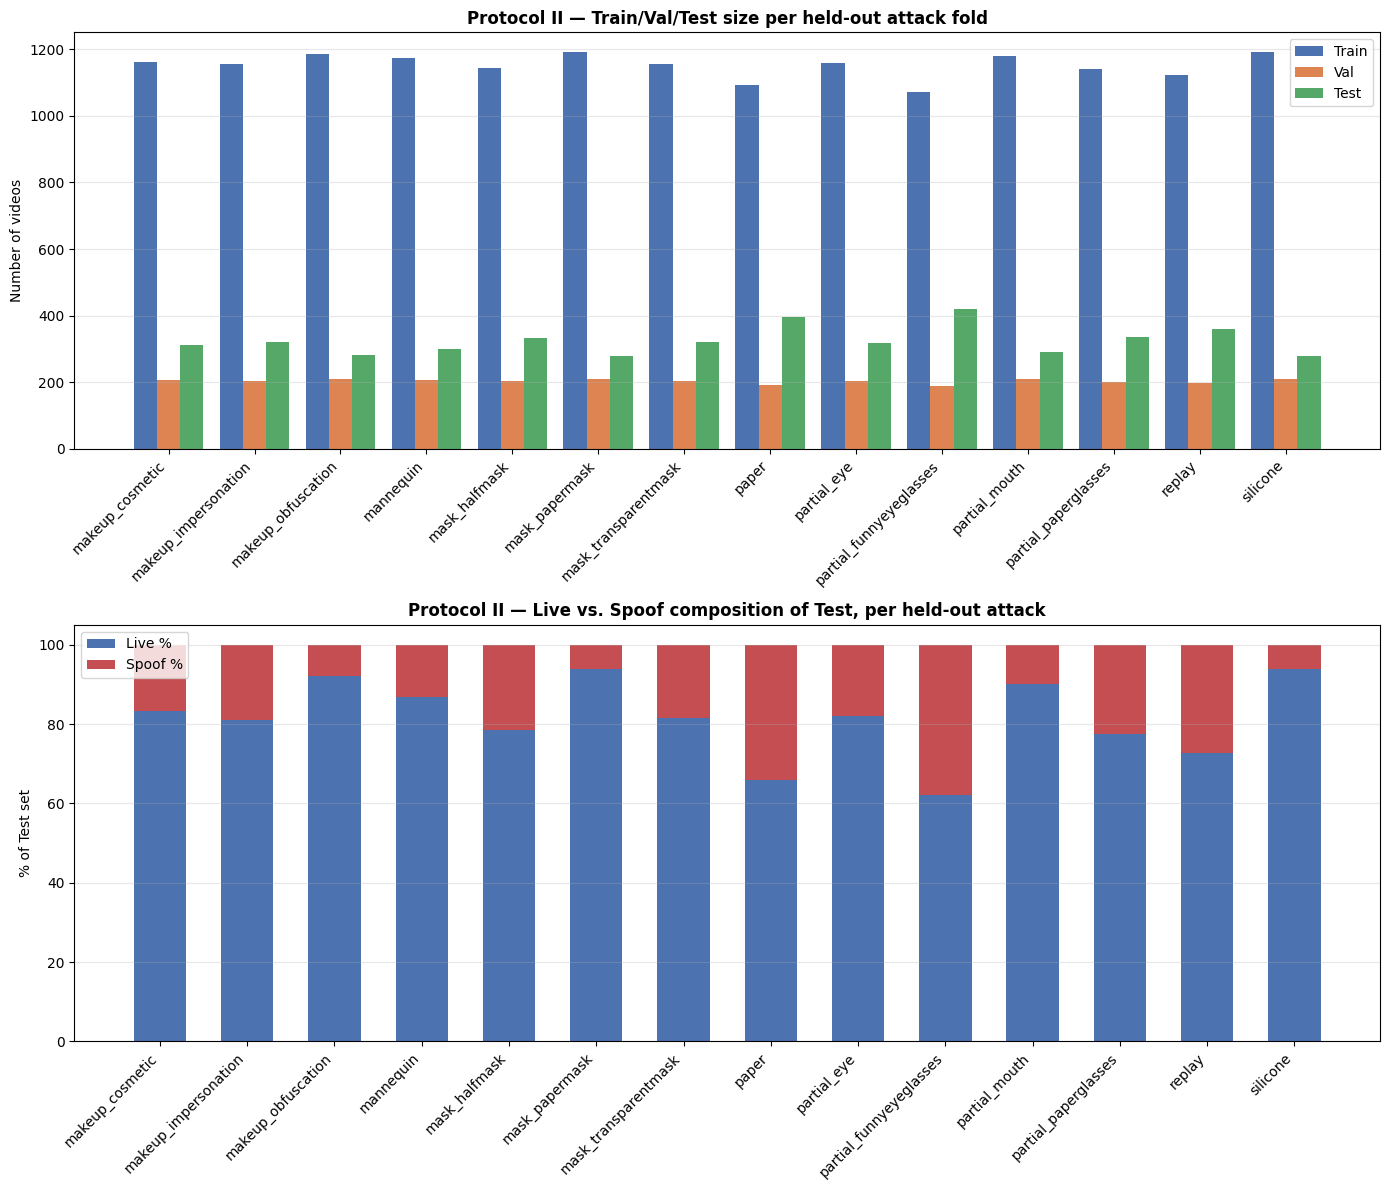


Held-out attack            Train     Val    Test  Test-Live%  Test-Spoof%
-------------------------------------------------------------------------
makeup_cosmetic             1161     206     313       83.4%        16.6%
makeup_impersonation        1154     204     322       81.1%        18.9%
makeup_obfuscation          1187     210     283       92.2%         7.8%
mannequin                   1172     207     301       86.7%        13.3%
mask_halfmask               1144     203     333       78.4%        21.6%
mask_papermask              1191     211     278       93.9%         6.1%
mask_transparentmask        1156     204     320       81.6%        18.4%
paper                       1091     193     396       65.9%        34.1%
partial_eye                 1157     205     318       82.1%        17.9%
partial_funnyeyeglasses     1070     189     421       62.0%        38.0%
partial_mouth               1181     209     290       90.0%        10.0%
partial_paperglasses        1141     

In [50]:
# ============================================================================
#  SiW PROTOCOL II — CHECK 2 equivalent: Split-size distribution across folds
# ============================================================================
#  Why this differs from OULU's Check 2:
#  OULU has ONE fixed split, so "per-attack distribution across splits" means
#  "how are the attack types spread across Train/Val/Test". SiW P2 rebuilds
#  the split 14 times, and Test ALWAYS contains exactly one attack type — so
#  an attack-composition-of-Test chart would be trivially 100%/0% and useless.
#
#  What's actually informative for P2:
#    (a) how Train/Val/Test SIZE varies fold-to-fold (x-axis = held-out attack)
#    (b) how the live/spoof MIX of Test varies fold-to-fold — Test = fixed
#        live-test count + that attack's pool size, so small attacks give a
#        live-heavy Test and large attacks give a spoof-heavy Test.
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pcfg  = PROTOCOL_CONFIG_SiW[2]
p1cfg = PROTOCOL_CONFIG_SiW[1]

live_train_names = _read_ids(pcfg['train_live_P2_80per'])
live_test_names  = _read_ids(pcfg['test_live_P2_20per'])
spoof_pool_names = _read_ids(p1cfg['train_spoof_P1']) | _read_ids(p1cfg['test_spoof_P1'])
df_ids = set(df['subject_id'])

live_train_df = df[(df['label'] == 0) & (df['subject_id'].isin(live_train_names & df_ids))].copy()
live_test_df  = df[(df['label'] == 0) & (df['subject_id'].isin(live_test_names  & df_ids))].copy()
spoof_pool_df = df[(df['label'] == 1) & (df['subject_id'].isin(spoof_pool_names & df_ids))].copy()

# ----------------------------------------------------------------------------
# Rebuild each fold's split ONCE, keeping just the counts we need for the charts
# ----------------------------------------------------------------------------
all_attacks = []      # held-out attack per fold (x-axis)
train_counts = []     # Train size per fold
val_counts = []       # Val size per fold
test_counts = []      # Test size per fold
test_live_pct = []    # % of Test that is live, per fold
test_spoof_pct = []   # % of Test that is spoof, per fold

for held_out_attack in SPOOF_ATTACKS_SiW:

    spoof_train_df = spoof_pool_df[spoof_pool_df['attack_type'] != held_out_attack].copy()
    spoof_test_df  = spoof_pool_df[spoof_pool_df['attack_type'] == held_out_attack].copy()

    if len(spoof_test_df) == 0:      # attack has no videos -> no fold to build
        continue

    train_full_df = pd.concat([live_train_df, spoof_train_df], ignore_index=True)
    test_df_chk   = pd.concat([live_test_df,  spoof_test_df],  ignore_index=True)

    gss = GroupShuffleSplit(n_splits=1, test_size=CFG.VAL_RATIO, random_state=SEED)
    tr_idx, val_idx = next(gss.split(train_full_df, groups=train_full_df['subject_id']))
    train_df_chk = train_full_df.iloc[tr_idx]
    val_df_chk   = train_full_df.iloc[val_idx]

    n_test = len(test_df_chk)
    n_test_live  = (test_df_chk['label'] == 0).sum()
    n_test_spoof = (test_df_chk['label'] == 1).sum()

    all_attacks.append(held_out_attack)
    train_counts.append(len(train_df_chk))
    val_counts.append(len(val_df_chk))
    test_counts.append(n_test)
    test_live_pct.append(100 * n_test_live / n_test if n_test else 0)
    test_spoof_pct.append(100 * n_test_spoof / n_test if n_test else 0)

# ----------------------------------------------------------------------------
# PLOT (a): grouped bar chart of Train / Val / Test SIZE per fold
# ----------------------------------------------------------------------------
x = np.arange(len(all_attacks))
w = 0.27

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

ax = axes[0]
ax.bar(x - w, train_counts, w, label='Train', color='#4C72B0')
ax.bar(x,     val_counts,   w, label='Val',   color='#DD8452')
ax.bar(x + w, test_counts,  w, label='Test',  color='#55A868')
ax.set_title('Protocol II — Train/Val/Test size per held-out attack fold', fontweight='bold')
ax.set_ylabel('Number of videos')
ax.set_xticks(x); ax.set_xticklabels(all_attacks, rotation=45, ha='right')
ax.legend(); ax.grid(axis='y', alpha=0.3)

# ----------------------------------------------------------------------------
# PLOT (b): stacked bar — live % vs spoof % composition of Test, per fold
# (this is the P2-meaningful version of OULU's "proportional" chart, since
#  Test's attack composition itself is always 100% one attack)
# ----------------------------------------------------------------------------
ax = axes[1]
ax.bar(x, test_live_pct,  0.6, label='Live %',  color='#4C72B0')
ax.bar(x, test_spoof_pct, 0.6, bottom=test_live_pct, label='Spoof %', color='#C44E52')
ax.set_title('Protocol II — Live vs. Spoof composition of Test, per held-out attack', fontweight='bold')
ax.set_ylabel('% of Test set')
ax.set_xticks(x); ax.set_xticklabels(all_attacks, rotation=45, ha='right')
ax.legend(); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('siw_p2_split_distribution_check.png', dpi=120, bbox_inches='tight')
plt.show()

# ----------------------------------------------------------------------------
# Print the numbers too, same table style as OULU's Check 2
# ----------------------------------------------------------------------------
print(f'\n{"Held-out attack":<24}{"Train":>8}{"Val":>8}{"Test":>8}{"Test-Live%":>12}{"Test-Spoof%":>13}')
print('-' * 73)
for a, tr, vl, te, lp, sp in zip(all_attacks, train_counts, val_counts, test_counts, test_live_pct, test_spoof_pct):
    print(f'{a:<24}{tr:>8}{vl:>8}{te:>8}{lp:>11.1f}%{sp:>12.1f}%')

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **For all the data in Protocol 2, check if the cache files are correctly formed:**

In [51]:
# ============================================================================
#  SiW PROTOCOL II — CACHE COVERAGE CHECK — directories, FFT files, flow files
# ============================================================================
#  For every video in the training split, this verifies three levels of cache
#  completeness:
#     1. the precompute DIRECTORY exists
#     2. all N_FRAMES  freq_*.npy  (FFT) files are present
#     3. all N_FRAMES  flow_*.npy  (optical flow) files are present
#  Any video failing a level triggers the on-the-fly recompute fallback in the
#  dataset (slower, and — for FFT — the source of the CUDA-in-worker crash),
#  so the goal is zero incompletes on every level.
#
#  P2 has no single train set — each of the 14 folds' train set is
#  live-train + (spoof-pool minus one attack). Checking cache fold-by-fold
#  would re-check the same ~895 spoof videos 13 times over (once per fold),
#  just missing a different single attack each time — pure duplicated work.
#  The correct scope is: every video that could EVER be a training video in
#  ANY fold = live_train_df UNION spoof_pool_df. live_test_df is excluded —
#  it's never used for training in any fold, only as the fixed test set.
#  This checks that full universe exactly once.
# ============================================================================
def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pcfg  = PROTOCOL_CONFIG_SiW[2]
p1cfg = PROTOCOL_CONFIG_SiW[1]

live_train_names = _read_ids(pcfg['train_live_P2_80per'])
spoof_pool_names = _read_ids(p1cfg['train_spoof_P1']) | _read_ids(p1cfg['test_spoof_P1'])
df_ids = set(df['subject_id'])

live_train_df = df[(df['label'] == 0) & (df['subject_id'].isin(live_train_names & df_ids))]
spoof_pool_df = df[(df['label'] == 1) & (df['subject_id'].isin(spoof_pool_names & df_ids))]

# every video that could ever appear in SOME fold's training set, checked once
train_universe_df = pd.concat([live_train_df, spoof_pool_df], ignore_index=True)

missing_dir  = []   # videos with NO precompute folder at all
missing_fft  = []   # videos whose folder exists but freq_*.npy files are incomplete
missing_flow = []   # videos whose folder exists but flow_*.npy files are incomplete

for _, row in train_universe_df.iterrows():
    vid_id  = Path(row['path']).stem
    vid_dir = CACHE_DIR_SiW / "precompute" / vid_id      # <- CACHE_DIR_OULU -> CACHE_DIR_SiW

    # ---- Level 1: does the cache directory exist at all? ----
    if not vid_dir.exists():
        missing_dir.append(vid_id)
        continue                       # no folder -> can't check files inside

    # ---- Level 2: count the FFT (freq) files inside the folder ----
    fft_files = list(vid_dir.glob('freq_*.npy'))
    if len(fft_files) < CFG.N_FRAMES:  # expect one freq file per frame
        missing_fft.append((vid_id, len(fft_files)))

    # ---- Level 3: count the optical-flow files inside the folder ----
    flow_files = list(vid_dir.glob('flow_*.npy'))
    if len(flow_files) < CFG.N_FRAMES: # expect one flow file per frame
        missing_flow.append((vid_id, len(flow_files)))

# ----------------------------------------------------------------------------
#  Report
# ----------------------------------------------------------------------------
total = len(train_universe_df)
print(f"Total training-universe videos (live-train + spoof-pool): {total}")
print(f"Missing cache directory         : {len(missing_dir)}")
print(f"Incomplete FFT (freq_*.npy)     : {len(missing_fft)}")
print(f"Incomplete flow (flow_*.npy)    : {len(missing_flow)}")

# Show a few examples for each problem level (only if any exist)
if missing_dir:
    print("\nExamples — missing directory:")
    print("  ", missing_dir[:10])
if missing_fft:
    print("\nExamples — incomplete FFT (vid_id, n_freq_files):")
    print("  ", missing_fft[:10])
if missing_flow:
    print("\nExamples — incomplete flow (vid_id, n_flow_files):")
    print("  ", missing_flow[:10])

# Clean bill of health
if not (missing_dir or missing_fft or missing_flow):
    print("\nAll cache directories, FFT files, and flow files are complete.")

Total training-universe videos (live-train + spoof-pool): 1419
Missing cache directory         : 0
Incomplete FFT (freq_*.npy)     : 0
Incomplete flow (flow_*.npy)    : 0

All cache directories, FFT files, and flow files are complete.


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 2 - Check how many of the total videos got letterboxed or aligned, by using their usable fraction**

Collected usable_frac for 1419 videos (out of 1419 in the training universe)


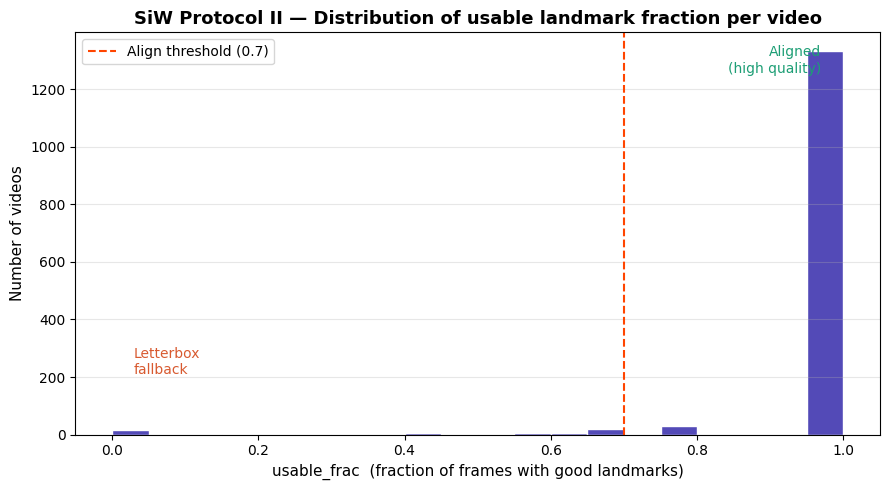

In [52]:
# ============================================================================
#  SiW PROTOCOL II — USABLE-LANDMARK-FRACTION DISTRIBUTION
# ============================================================================
#  Same scoping logic as the cache coverage check: P2 has no single
#  train_df_P2, so this reads video_meta.json for every video that could
#  EVER be a training video in some fold — live_train_df UNION spoof_pool_df
#  — checked once, rather than re-reading the same ~895 spoof jsons 14 times.
# ============================================================================
from pathlib import Path
import json
import matplotlib.pyplot as plt

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pcfg  = PROTOCOL_CONFIG_SiW[2]
p1cfg = PROTOCOL_CONFIG_SiW[1]

live_train_names = _read_ids(pcfg['train_live_P2_80per'])
spoof_pool_names = _read_ids(p1cfg['train_spoof_P1']) | _read_ids(p1cfg['test_spoof_P1'])
df_ids = set(df['subject_id'])

live_train_df = df[(df['label'] == 0) & (df['subject_id'].isin(live_train_names & df_ids))]
spoof_pool_df = df[(df['label'] == 1) & (df['subject_id'].isin(spoof_pool_names & df_ids))]

# every video that could ever appear in SOME fold's training set, read once
train_universe_df = pd.concat([live_train_df, spoof_pool_df], ignore_index=True)

# --- Build the list of usable_frac values from cached video_meta.json ---
fracs = []
for _, row in train_universe_df.iterrows():
    vid_id = Path(row['path']).stem
    mp = CACHE_DIR_SiW / "precompute" / vid_id / "video_meta.json"   # <- CACHE_DIR_OULU -> CACHE_DIR_SiW
    if mp.exists():
        fracs.append(json.load(open(mp))['usable_frac'])

print(f"Collected usable_frac for {len(fracs)} videos "
      f"(out of {len(train_universe_df)} in the training universe)")

# --- Plot ---
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(fracs, bins=20, color='#534AB7', edgecolor='white')
ax.set_title('SiW Protocol II — Distribution of usable landmark fraction per video',
             fontsize=13, fontweight='bold')
ax.set_xlabel('usable_frac  (fraction of frames with good landmarks)', fontsize=11)
ax.set_ylabel('Number of videos', fontsize=11)

# Reference line at the align threshold
ax.axvline(CFG.ALIGN_MIN_FRAC, color='orangered', linestyle='--', linewidth=1.5,
           label=f'Align threshold ({CFG.ALIGN_MIN_FRAC})')

# Region annotations
ax.text(0.97, ax.get_ylim()[1] * 0.9, 'Aligned\n(high quality)',
        ha='right', color='#1D9E75', fontsize=10)
ax.text(0.03, ax.get_ylim()[1] * 0.15, 'Letterbox\nfallback',
        ha='left', color='#D85A30', fontsize=10)

ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [53]:
# ============================================================================
#  SiW PROTOCOL II — LETTERBOXED VIDEOS (usable_frac BELOW align threshold)
# ============================================================================
#  Same scoping fix as the previous two checks: no single train_df_P2 for
#  P2, so this scans live_train_df UNION spoof_pool_df once — every video
#  that could ever be a training video in some fold.
#
#  Note on attack_type for live videos: live rows have label=0 and no real
#  attack_type (there's no attack). row.get('attack_type', 'unknown') would
#  silently label them 'unknown' if the column is missing/NaN, which reads
#  as "we don't know what attack this is" rather than "this is real, not an
#  attack". Labeled explicitly as 'real' below instead, so the per-attack
#  breakdown isn't misleading.
# ============================================================================
from pathlib import Path
import json
from collections import Counter

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pcfg  = PROTOCOL_CONFIG_SiW[2]
p1cfg = PROTOCOL_CONFIG_SiW[1]

live_train_names = _read_ids(pcfg['train_live_P2_80per'])
spoof_pool_names = _read_ids(p1cfg['train_spoof_P1']) | _read_ids(p1cfg['test_spoof_P1'])
df_ids = set(df['subject_id'])

live_train_df = df[(df['label'] == 0) & (df['subject_id'].isin(live_train_names & df_ids))]
spoof_pool_df = df[(df['label'] == 1) & (df['subject_id'].isin(spoof_pool_names & df_ids))]

# every video that could ever appear in SOME fold's training set, scanned once
train_universe_df = pd.concat([live_train_df, spoof_pool_df], ignore_index=True)

# --- Collect videos below the align threshold, WITH their attack types ---
low_videos = []
for _, row in train_universe_df.iterrows():
    vid_id = Path(row['path']).stem
    mp = CACHE_DIR_SiW / "precompute" / vid_id / "video_meta.json"   # <- CACHE_DIR_OULU -> CACHE_DIR_SiW
    if mp.exists():
        uf = json.load(open(mp))['usable_frac']
        if uf < CFG.ALIGN_MIN_FRAC:          # below threshold -> letterboxed
            atk = row.get('attack_type', 'unknown')
            if row['label'] == 0:            # live video: not an attack, label explicitly
                atk = 'real'
            low_videos.append({
                'vid_id': vid_id,
                'label': row['label'],
                'attack_type': atk,
                'usable_frac': round(uf, 3),
            })

print(f"Total letterboxed (usable_frac < {CFG.ALIGN_MIN_FRAC}): {len(low_videos)}\n")

# Percentage of total videos that were letterboxed
total = len(train_universe_df)
pct = (len(low_videos) / total * 100) if total else 0.0
print(f"Total videos (training universe): {total}")
print(f"Letterboxed %%                    : {pct:.6f}%")

# Only print the breakdowns if there ARE letterboxed videos
if low_videos:
    # Count per attack type (now includes 'real' as its own bucket)
    attack_counts = Counter(v['attack_type'] for v in low_videos)
    print("\nLetterboxed videos by attack type:")
    for atk, cnt in attack_counts.most_common():
        print(f"  {atk:30s} : {cnt}")

    # Real vs fake split
    label_counts = Counter(v['label'] for v in low_videos)
    print(f"\nBy label: {dict(label_counts)}")

    # Full list
    print("\nIndividual videos:")
    for v in low_videos:
        print(f"  {v['vid_id']:25s} label={v['label']} attack={v['attack_type']:20s} uf={v['usable_frac']}")
else:
    print("\nNo letterboxed videos — all videos met the alignment threshold.")

Total letterboxed (usable_frac < 0.7): 57

Total videos (training universe): 1419
Letterboxed %%                    : 4.016913%

Letterboxed videos by attack type:
  real                           : 22
  paper                          : 9
  partial_funnyeyeglasses        : 9
  mask_transparentmask           : 5
  mask_halfmask                  : 3
  partial_paperglasses           : 3
  replay                         : 2
  makeup_cosmetic                : 1
  mannequin                      : 1
  partial_mouth                  : 1
  silicone                       : 1

By label: {0: 22, 1: 35}

Individual videos:
  Live_113                  label=0 attack=real                 uf=0.688
  Live_161                  label=0 attack=real                 uf=0.562
  Live_227                  label=0 attack=real                 uf=0.562
  Live_232                  label=0 attack=real                 uf=0.688
  Live_248                  label=0 attack=real                 uf=0.688
  Live_291       

In [54]:
# Diagnostics to confirm the letterbox check is actually reading files
# (not silently finding nothing). Checks:
#   (1) how many meta files were actually found
#   (2) how many of those are letterboxed
# (1) is the key diagnostic — confirms the check isn't silently failing.
found = 0
low_videos = []
for _, row in train_universe_df.iterrows():          # <- train_df_P2 -> train_universe_df (live_train + spoof_pool)
    vid_id = Path(row['path']).stem
    mp = CACHE_DIR_SiW / "precompute" / vid_id / "video_meta.json"   # <- CACHE_DIR_OULU -> CACHE_DIR_SiW
    if mp.exists():
        found += 1                          # ← count files actually found
        uf = json.load(open(mp))['usable_frac']
        if uf < CFG.ALIGN_MIN_FRAC:
            low_videos.append({...})
print(f"Meta files found: {found} / {len(train_universe_df)}")   # ← the key diagnostic
print(f"Letterboxed: {len(low_videos)}")

Meta files found: 1419 / 1419
Letterboxed: 57


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 2 - Model Training:**

### **Create train / val / test datasets**
### **Create Data Loaders for creating batches.**
### **Model Training.**

In [ ]:
from Functions.run_epochs_17 import *
from Functions.data_pipeline_setup_7 import *
from Functions.weighted_sampler_8 import *
from Functions.full_model_pipeline_13 import *
from Functions.loss_functions_14 import *
from Functions.optimiser_and_scheduler_15 import *

# ============================================================================
#  PROTOCOL II  —  Unknown Spoof Attack Detection (leave-one-attack-out)
#  Trains a FRESH model for EACH of the 14 held-out attacks, evaluates on the
#  held-out attack, and reports per-attack + mean ± std.
# ============================================================================

# --------------------- Protocol details -------------------------------------
ACTIVE_PROTOCOL = 2
pcfg = PROTOCOL_CONFIG_SiW[ACTIVE_PROTOCOL]              # pulls the Protocol II block from the config dict
Path(pcfg['ckpt_prefix']).parent.mkdir(parents=True, exist_ok=True)   # ckpt_prefix is a FILENAME prefix, not a dir —
                                                                       # .parent gives the actual folder to create
result_dir = pcfg['result']                               # where protocol2_summary.json will be saved
result_dir.mkdir(parents=True, exist_ok=True)

# --------------------- Read shared live + spoof pool ONCE -------------------
def _read_ids(p):
    # Reads a partition .txt file (one video/subject name per line) into a set
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

live_train_ids = _read_ids(pcfg['train_live_P2_80per'])     # FIXED 80% live-train file — same every fold, not re-split
live_test_ids  = _read_ids(pcfg['test_live_P2_20per'])      # FIXED 20% live-test file  — same every fold, not re-split

p1 = PROTOCOL_CONFIG_SiW[1]                                  # P2 has no spoof file of its own — it reuses P1's
spoof_pool_ids = (_read_ids(p1['train_spoof_P1']) | _read_ids(p1['test_spoof_P1'])) & set(df['subject_id'])
# ^ union of P1's train+test spoof names, intersected with what's actually in df -> the full 14-attack spoof pool
spoof_pool_df  = df[(df['label'] == 1) & (df['subject_id'].isin(spoof_pool_ids))].copy()
print(f'Spoof pool: {len(spoof_pool_ids)} subjects | {len(spoof_pool_df)} spoof videos')

# --------------------- Results collector ------------------------------------
protocol2_results = []      # one entry appended per attack, after that attack's fold finishes
PATIENCE = 7                 # epochs to wait for val ACER improvement before early-stopping a fold
overall_start = time.time()  # for the total-runtime readout at the very end

# ============================================================================
#  OUTER LOOP — leave out each attack in turn (all 14, in sequence)
#  Everything inside this loop — split, model, optimizer, checkpoint — is
#  rebuilt from scratch per attack, so no fold ever leaks into another.
# ============================================================================
for held_out_attack in SPOOF_ATTACKS_SiW:

    print('\n' + '=' * 80)
    print(f'PROTOCOL II  |  held-out attack = {held_out_attack}')
    print('=' * 80)

    # -------- Build the split for THIS held-out attack ----------------------
    live_train_df = df[(df['label'] == 0) & (df['subject_id'].isin(live_train_ids))].copy()  # fixed, same every fold
    live_test_df  = df[(df['label'] == 0) & (df['subject_id'].isin(live_test_ids))].copy()    # fixed, same every fold
    spoof_train_df = spoof_pool_df[spoof_pool_df['attack_type'] != held_out_attack].copy()    # pool minus 1 attack (13 attacks)
    spoof_test_df  = spoof_pool_df[spoof_pool_df['attack_type'] == held_out_attack].copy()    # ONLY the held-out attack

    if len(spoof_test_df) == 0:                 # attack string didn't match anything in the pool
        print(f'  SKIP — 0 samples for {held_out_attack!r} (check attack_type string)')
        continue

    train_full_df_P2 = pd.concat([live_train_df, spoof_train_df], ignore_index=True)  # everything BEFORE the val carve
    test_df_P2       = pd.concat([live_test_df,  spoof_test_df],  ignore_index=True)  # final test set for this fold

    # subject-disjoint validation carve from train — GroupShuffleSplit groups by
    # subject_id so no single person's videos end up split across train AND val
    gss = GroupShuffleSplit(n_splits=1, test_size=CFG.VAL_RATIO, random_state=SEED)
    tr_idx, val_idx = next(gss.split(train_full_df_P2, groups=train_full_df_P2['subject_id']))
    train_df_P2 = train_full_df_P2.iloc[tr_idx].copy()   # final train set for this fold
    val_df_P2   = train_full_df_P2.iloc[val_idx].copy()  # final val set for this fold
    print(f'  Train {len(train_df_P2)} | Val {len(val_df_P2)} | Test {len(test_df_P2)} '
          f'(held-out spoof {len(spoof_test_df)})')

    # -------- Datasets (cache already built for whole df) -------------------
    # demo_mode=False -> reads real cached tensors (frames/freq/flow), not dummy data
    train_dataset_P2 = PADVideoDataset(train_df_P2, real_dir = REAL_DIR_SiW, cache_dir = CACHE_DIR_SiW, 
                                       transform=train_transforms, demo_mode=False,
                                       use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
    val_dataset_P2   = PADVideoDataset(val_df_P2, real_dir = REAL_DIR_SiW, cache_dir = CACHE_DIR_SiW, 
                                       transform=val_transforms, demo_mode=False,
                                       use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
    test_dataset_P2  = PADVideoDataset(test_df_P2, real_dir = REAL_DIR_SiW, cache_dir = CACHE_DIR_SiW,
                                       transform=val_transforms, demo_mode=False,
                                       use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)

    # -------- Loaders -------------------------------------------------------
    train_sampler_P2 = make_weighted_sampler(train_dataset_P2)   # rebalances real vs. fake sampling per fold
    train_loader_P2 = DataLoader(train_dataset_P2, batch_size=CFG.BATCH_SIZE, sampler=train_sampler_P2,
                                 num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)
    val_loader_P2   = DataLoader(val_dataset_P2, batch_size=CFG.BATCH_SIZE, shuffle=False,
                                 num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)
    test_loader_P2  = DataLoader(test_dataset_P2, batch_size=CFG.BATCH_SIZE, shuffle=False,
                                 num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)

    # ======================================================================
    #  FRESH model + loss + optimizer + scheduler + scaler
    #  (rebuilt every attack so the model never saw the held-out attack;
    #   param_groups must reference THIS model's modules, so build here)
    # ======================================================================
    model = HybridPADModel().to(DEVICE)          # brand-new, untrained weights every fold — no leakage between folds

    criterion = CompoundFASLoss()

    # Differential LRs: pretrained RGB backbone 10x smaller; everything else full LR
    # (backbone already has useful features from pretraining, so it's fine-tuned
    #  gently; the newer/task-specific modules are trained at full speed)
    param_groups = [
        {'params': list(model.cnn_rgb.backbone.parameters()),  'lr': CFG.LR * 0.1, 'name': 'rgb_backbone'},
        {'params': list(model.cnn_rgb.projector.parameters()), 'lr': CFG.LR,       'name': 'rgb_proj'},
        {'params': list(model.cnn_freq.parameters()),          'lr': CFG.LR,       'name': 'freq_cnn'},
        {'params': list(model.cnn_flow.parameters()),          'lr': CFG.LR,       'name': 'flow_cnn'},
        {'params': list(model.stream_gate.parameters()),       'lr': CFG.LR,       'name': 'gate'},
        {'params': list(model.rnn_encoder.parameters()),       'lr': CFG.LR,       'name': 'rnn'},
        {'params': list(model.tf_encoder.parameters()),        'lr': CFG.LR,       'name': 'transformer'},
        {'params': list(model.classifier.parameters()),        'lr': CFG.LR,       'name': 'classifier'},
        {'params': list(model.proj_head.parameters()),         'lr': CFG.LR,       'name': 'supcon_head'},
    ]
    optimizer = optim.AdamW(param_groups, weight_decay=CFG.WEIGHT_DECAY)
    scheduler = WarmupCosineScheduler(optimizer, CFG.WARMUP_EPOCHS, CFG.N_EPOCHS, CFG.LR)   # warmup then cosine decay
    scaler    = torch.amp.GradScaler('cuda')      # mixed-precision training (fp16/bf16) for speed + memory
    # ======================================================================

    # -------- Per-attack training state ------------------------------------
    best_val_acer = float('inf')    # tracks the best (lowest) val ACER seen so far this fold
    patience_counter = 0            # epochs since the last improvement
    ckpt_path = Path(str(pcfg['ckpt_prefix']) + f'{held_out_attack}.pth')   # e.g. best_model_protocol_2_replay.pth
    history = {'train_loss':[], 'val_loss':[], 'train_acer':[], 'val_acer':[],
               'train_auc':[], 'val_auc':[], 'lr':[]}     # per-epoch log, saved inside the checkpoint

    # -------- Inner training loop (same structure as P1) -------------------
    for epoch in range(CFG.N_EPOCHS):
        current_lr = scheduler.step(epoch)      # advance the LR schedule for this epoch

        # one pass over train (updates weights) and one pass over val (no updates, just metrics)
        train_loss, train_metrics, _, _, train_comps, _ = run_epoch(
            model, train_loader_P2, optimizer, criterion, DEVICE, scaler, is_train=True, epoch=epoch)
        val_loss, val_metrics, _, _, val_comps, _ = run_epoch(
            model, val_loader_P2, optimizer, criterion, DEVICE, scaler=None, is_train=False, epoch=epoch)

        # log this epoch's numbers into the history dict
        history['train_loss'].append(train_loss); history['val_loss'].append(val_loss)
        history['train_acer'].append(train_metrics['ACER']); history['val_acer'].append(val_metrics['ACER'])
        history['train_auc'].append(train_metrics['AUC']);   history['val_auc'].append(val_metrics['AUC'])
        history['lr'].append(current_lr[-1] if isinstance(current_lr, (list, tuple)) else current_lr)

        improved = val_metrics['ACER'] < best_val_acer     # lower ACER = better
        star = ' * BEST' if improved else ''
        print(f"  Ep {epoch+1:02d}/{CFG.N_EPOCHS} | "
              f"Loss T:{train_loss:.4f} V:{val_loss:.4f} | "
              f"ACER T:{train_metrics['ACER']:.4f} V:{val_metrics['ACER']:.4f} | "
              f"AUC:{val_metrics['AUC']:.4f}{star}")

        if improved:
            best_val_acer = val_metrics['ACER']
            patience_counter = 0
            # overwrite the checkpoint with this new best — only the single best epoch is kept per fold
            torch.save({'epoch': epoch+1, 'state_dict': model.state_dict(),
                        'optimizer_state_dict': optimizer.state_dict(),
                        'scaler_state_dict': scaler.state_dict(),
                        'val_acer': best_val_acer, 'val_metrics': val_metrics,
                        'held_out_attack': held_out_attack, 'history': history}, ckpt_path)
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:        # no improvement for PATIENCE epochs -> stop this fold early
                print(f'  Early stopping at epoch {epoch+1}')
                break

    # -------- Evaluate: load best, tune threshold on VAL, apply to TEST -----
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)   # reload the best-epoch weights
    model.load_state_dict(ckpt['state_dict'])
    print(f'  Loaded best (epoch {ckpt["epoch"]}, val ACER={ckpt["val_acer"]:.4f})')

    # validation pass -> choose threshold
    # (threshold is tuned on VAL, never on TEST, to avoid leaking test information into the decision boundary)
    _, _, val_probs, val_labels, _, _ = run_epoch(
        model, val_loader_P2, optimizer, criterion, DEVICE, scaler=None, is_train=False)
    val_labels_int = val_labels.round().astype(int)
    thresholds = np.linspace(0.1, 0.9, 100)          # scan 100 candidate thresholds
    val_acers = [compute_pad_metrics(val_labels_int, val_probs, t)['ACER'] for t in thresholds]
    best_thresh = thresholds[np.argmin(val_acers)]   # pick the one that minimizes val ACER

    # test pass -> final metrics at val-tuned threshold
    _, _, test_probs, test_labels, _, test_attacks = run_epoch(
        model, test_loader_P2, optimizer, criterion, DEVICE, scaler=None, is_train=False)
    test_labels_int = test_labels.round().astype(int)
    m = compute_pad_metrics(test_labels_int, test_probs, threshold=best_thresh)   # ACER/APCER/BPCER/AUC on TEST
    tdr = compute_tdr_at_fdr(test_labels_int, test_probs, target_fdr=0.01)        # true-detection-rate @ 1% false-detection-rate

    print(f'  >> {held_out_attack}: ACER {m["ACER"]*100:.2f}% | APCER {m["APCER"]*100:.2f}% | '
          f'BPCER {m["BPCER"]*100:.2f}% | AUC {m["AUC"]*100:.2f}% | thr {best_thresh:.3f}')

    # store this fold's final numbers for the aggregate summary below
    protocol2_results.append({
        'attack': held_out_attack, 'ACER': m['ACER'], 'APCER': m['APCER'],
        'BPCER': m['BPCER'], 'AUC': m['AUC'], 'threshold': float(best_thresh),
        'best_val_acer': float(best_val_acer),
        'TDR': tdr
    })

# ============================================================================
#  AGGREGATE — per-attack table + mean ± std
#  (this is the headline Protocol II result: mean ACER across all 14 attacks,
#   with std showing how much performance varies attack-to-attack)
# ============================================================================
print('\n' + '=' * 80)
print('PROTOCOL II — SUMMARY')
print('=' * 80)
print(f"{'Attack':<24}{'ACER%':>9}{'APCER%':>9}{'BPCER%':>9}{'AUC%':>9}")
print('-' * 60)
for r in protocol2_results:
    print(f"{r['attack']:<24}{r['ACER']*100:>9.2f}{r['APCER']*100:>9.2f}"
          f"{r['BPCER']*100:>9.2f}{r['AUC']*100:>9.2f}")

acers = np.array([r['ACER'] for r in protocol2_results]) * 100
aucs  = np.array([r['AUC']  for r in protocol2_results]) * 100
print('-' * 60)
print(f"{'MEAN':<24}{acers.mean():>9.2f}{'':>18}{aucs.mean():>9.2f}")
print(f"{'STD':<24}{acers.std():>9.2f}{'':>18}{aucs.std():>9.2f}")

# -------- Save summary -------------------------------------------------------
import json
with open(result_dir / 'protocol2_summary.json', 'w') as f:
    json.dump({'per_attack': protocol2_results,
               'mean_acer': float(acers.mean()), 'std_acer': float(acers.std()),
               'mean_auc': float(aucs.mean()), 'std_auc': float(aucs.std())}, f, indent=2)

elapsed = time.time() - overall_start
h, rem = divmod(int(elapsed), 3600); mnt, s = divmod(rem, 60)   # format elapsed seconds as HH:MM:SS
print(f'\nProtocol II complete. Total time = {h:02d}:{mnt:02d}:{s:02d}')
print(f'Summary saved to {result_dir / "protocol2_summary.json"}')

Spoof pool: 895 subjects | 895 spoof videos

PROTOCOL II  |  held-out attack = makeup_cosmetic
  Train 1161 | Val 206 | Test 313 (held-out spoof 52)


  Ep 01/30 | Loss T:1.1121 V:1.0580 | ACER T:0.3855 V:0.0922 | AUC:0.9737 * BEST


  Ep 02/30 | Loss T:0.9242 V:1.0212 | ACER T:0.0788 V:0.0283 | AUC:0.9979 * BEST


  Ep 03/30 | Loss T:0.8471 V:1.0599 | ACER T:0.0260 V:0.0187 | AUC:0.9991 * BEST


  Ep 04/30 | Loss T:0.8403 V:1.2739 | ACER T:0.0151 V:0.0709 | AUC:0.9997


  Ep 05/30 | Loss T:0.8304 V:1.0691 | ACER T:0.0113 V:0.0491 | AUC:0.9938


... (201 outputs left out)

  Ep 10/30 | Loss T:0.8297 V:1.1126 | ACER T:0.0044 V:0.0143 | AUC:0.9974


  Ep 11/30 | Loss T:0.8294 V:1.1339 | ACER T:0.0042 V:0.0252 | AUC:0.9973


  Ep 12/30 | Loss T:0.8305 V:1.0767 | ACER T:0.0034 V:0.0143 | AUC:0.9979


Train (ep 13/30):  51%|██████████████████████████▋                         | 19/37 [00:39<00:38,  2.12s/it, loss=0.8126]

In [35]:
# # ============================================================================
# #  SANITY CHECK: is protocol2_results_partial.json valid, and do the
# #  numbers in it (especially silicone's) look sane?
# # ============================================================================
# import json

# partial_results_path = pcfg['result'] / 'protocol2_results_partial.json'

# # ---- Step 1: does it even parse as valid JSON? ----
# # If the crash happened mid-write, this will raise json.JSONDecodeError,
# # which tells you the WHOLE file is corrupted, not just one entry.
# try:
#     with open(partial_results_path) as f:
#         results = json.load(f)
#     print(f"\u2705 JSON parsed successfully — {len(results)} entries found.\n")
# except json.JSONDecodeError as e:
#     print(f"\u274c JSON is CORRUPTED — failed to parse: {e}")
#     print("The file itself is broken, not just one entry. "
#           "You'll likely need to restore from a backup, or delete this file "
#           "and let the resumable script rebuild it fold-by-fold "
#           "(re-evaluating any attack whose .pth checkpoint still exists).")
#     raise SystemExit

# # ---- Step 2: print every entry so you can eyeball the numbers ----
# print(f"{'Attack':<24}{'ACER%':>8}{'APCER%':>8}{'BPCER%':>8}{'AUC%':>8}{'Threshold':>11}")
# print('-' * 70)
# for r in results:
#     print(f"{r['attack']:<24}{r['ACER']*100:>8.2f}{r['APCER']*100:>8.2f}"
#           f"{r['BPCER']*100:>8.2f}{r['AUC']*100:>8.2f}{r['threshold']:>11.3f}")

# # ---- Step 3: basic sanity flags — values outside plausible ranges ----
# print("\nSanity flags:")
# any_flagged = False
# for r in results:
#     issues = []
#     for key in ['ACER', 'APCER', 'BPCER', 'AUC']:
#         val = r[key]
#         if not (0.0 <= val <= 1.0):
#             issues.append(f"{key}={val} is outside [0,1]")
#     if r['AUC'] < 0.5:
#         issues.append(f"AUC={r['AUC']:.3f} is worse than random — worth a second look")
#     if issues:
#         any_flagged = True
#         print(f"  \u26a0\ufe0f  {r['attack']}: {', '.join(issues)}")

# if not any_flagged:
#     print("  None — all values are in plausible ranges.")

# # ---- Step 4: specifically pull out silicone's entry, if present ----
# silicone_entries = [r for r in results if r['attack'] == 'silicone']
# print(f"\n'silicone' entries found: {len(silicone_entries)}")
# for r in silicone_entries:
#     print(f"  {r}")

✅ JSON parsed successfully — 14 entries found.

Attack                     ACER%  APCER%  BPCER%    AUC%  Threshold
----------------------------------------------------------------------
makeup_cosmetic            22.69   44.23    1.15   93.56      0.213
makeup_impersonation        0.96    0.00    1.92   99.82      0.100
makeup_obfuscation         14.02   27.27    0.77   89.45      0.286
mannequin                   0.57    0.00    1.15   99.62      0.504
mask_halfmask               2.23    1.39    3.07   99.52      0.100
mask_papermask              1.15    0.00    2.30  100.00      0.504
mask_transparentmask        2.38    1.69    3.07   99.53      0.157
paper                      18.90   37.04    0.77   97.23      0.431
partial_eye                 0.19    0.00    0.38   99.73      0.140
partial_funnyeyeglasses    35.00   70.00    0.00   94.44      0.132
partial_mouth               0.38    0.00    0.77   99.63      0.439
partial_paperglasses        0.19    0.00    0.38   99.63      0.2

In [36]:
# # ============================================================================
# #  Remove 'silicone' entry from protocol2_results_partial.json
# #  (its checkpoint was deleted, so its old recorded result is stale/invalid)
# # ============================================================================
# import json

# partial_results_path = pcfg['result'] / 'protocol2_results_partial.json'

# with open(partial_results_path) as f:
#     results = json.load(f)

# before = len(results)
# results = [r for r in results if r['attack'] != 'silicone']   # drop silicone's entry
# after = len(results)

# with open(partial_results_path, 'w') as f:
#     json.dump(results, f, indent=2)

# print(f"Removed {before - after} entry/entries for 'silicone'")
# print(f"Remaining attacks in partial results ({after}): {[r['attack'] for r in results]}")

Removed 1 entry/entries for 'silicone'
Remaining attacks in partial results (13): ['makeup_cosmetic', 'makeup_impersonation', 'makeup_obfuscation', 'mannequin', 'mask_halfmask', 'mask_papermask', 'mask_transparentmask', 'paper', 'partial_eye', 'partial_funnyeyeglasses', 'partial_mouth', 'partial_paperglasses', 'replay']


In [37]:
# # ============================================================================
# #  SANITY CHECK: is protocol2_results_partial.json valid, and do the
# #  numbers in it (especially silicone's) look sane?
# # ============================================================================
# import json

# partial_results_path = pcfg['result'] / 'protocol2_results_partial.json'

# # ---- Step 1: does it even parse as valid JSON? ----
# # If the crash happened mid-write, this will raise json.JSONDecodeError,
# # which tells you the WHOLE file is corrupted, not just one entry.
# try:
#     with open(partial_results_path) as f:
#         results = json.load(f)
#     print(f"\u2705 JSON parsed successfully — {len(results)} entries found.\n")
# except json.JSONDecodeError as e:
#     print(f"\u274c JSON is CORRUPTED — failed to parse: {e}")
#     print("The file itself is broken, not just one entry. "
#           "You'll likely need to restore from a backup, or delete this file "
#           "and let the resumable script rebuild it fold-by-fold "
#           "(re-evaluating any attack whose .pth checkpoint still exists).")
#     raise SystemExit

# # ---- Step 2: print every entry so you can eyeball the numbers ----
# print(f"{'Attack':<24}{'ACER%':>8}{'APCER%':>8}{'BPCER%':>8}{'AUC%':>8}{'Threshold':>11}")
# print('-' * 70)
# for r in results:
#     print(f"{r['attack']:<24}{r['ACER']*100:>8.2f}{r['APCER']*100:>8.2f}"
#           f"{r['BPCER']*100:>8.2f}{r['AUC']*100:>8.2f}{r['threshold']:>11.3f}")

# # ---- Step 3: basic sanity flags — values outside plausible ranges ----
# print("\nSanity flags:")
# any_flagged = False
# for r in results:
#     issues = []
#     for key in ['ACER', 'APCER', 'BPCER', 'AUC']:
#         val = r[key]
#         if not (0.0 <= val <= 1.0):
#             issues.append(f"{key}={val} is outside [0,1]")
#     if r['AUC'] < 0.5:
#         issues.append(f"AUC={r['AUC']:.3f} is worse than random — worth a second look")
#     if issues:
#         any_flagged = True
#         print(f"  \u26a0\ufe0f  {r['attack']}: {', '.join(issues)}")

# if not any_flagged:
#     print("  None — all values are in plausible ranges.")

# # ---- Step 4: specifically pull out silicone's entry, if present ----
# silicone_entries = [r for r in results if r['attack'] == 'silicone']
# print(f"\n'silicone' entries found: {len(silicone_entries)}")
# for r in silicone_entries:
#     print(f"  {r}")

✅ JSON parsed successfully — 13 entries found.

Attack                     ACER%  APCER%  BPCER%    AUC%  Threshold
----------------------------------------------------------------------
makeup_cosmetic            22.69   44.23    1.15   93.56      0.213
makeup_impersonation        0.96    0.00    1.92   99.82      0.100
makeup_obfuscation         14.02   27.27    0.77   89.45      0.286
mannequin                   0.57    0.00    1.15   99.62      0.504
mask_halfmask               2.23    1.39    3.07   99.52      0.100
mask_papermask              1.15    0.00    2.30  100.00      0.504
mask_transparentmask        2.38    1.69    3.07   99.53      0.157
paper                      18.90   37.04    0.77   97.23      0.431
partial_eye                 0.19    0.00    0.38   99.73      0.140
partial_funnyeyeglasses    35.00   70.00    0.00   94.44      0.132
partial_mouth               0.38    0.00    0.77   99.63      0.439
partial_paperglasses        0.19    0.00    0.38   99.63      0.2

In [38]:
# from Functions.run_epochs_17 import *
# from Functions.data_pipeline_setup_7 import *
# from Functions.weighted_sampler_8 import *
# from Functions.full_model_pipeline_13 import *
# from Functions.loss_functions_14 import *
# from Functions.optimiser_and_scheduler_15 import *
# import json

# # ============================================================================
# #  PROTOCOL II  —  Unknown Spoof Attack Detection (leave-one-attack-out)
# #  Trains a FRESH model for EACH of the 14 held-out attacks, evaluates on the
# #  held-out attack, and reports per-attack + mean ± std.
# #
# #  RESUME SUPPORT (added after the 6hr crash at fold 10/14):
# #   - protocol2_results used to live ONLY in memory and get written to disk
# #     once, at the very end -> a crash lost metrics for ALL completed folds,
# #     not just the ones still in progress.
# #   - Now: (a) a partial-results JSON is written after EVERY fold, and loaded
# #     back in on restart, so completed folds are never lost again; (b) if an
# #     attack's checkpoint (.pth) already exists on disk but isn't yet in the
# #     partial-results JSON (e.g. training finished but the crash happened
# #     during/after evaluation), training is SKIPPED and the checkpoint is
# #     reloaded to recover its metrics via the (cheap) evaluation pass only —
# #     no wasted retraining.
# # ============================================================================

# # --------------------- Protocol details -------------------------------------
# ACTIVE_PROTOCOL = 2
# pcfg = PROTOCOL_CONFIG_SiW[ACTIVE_PROTOCOL]              # pulls the Protocol II block from the config dict
# Path(pcfg['ckpt_prefix']).parent.mkdir(parents=True, exist_ok=True)   # ckpt_prefix is a FILENAME prefix, not a dir —
#                                                                        # .parent gives the actual folder to create
# result_dir = pcfg['result']                               # where protocol2_summary.json will be saved
# result_dir.mkdir(parents=True, exist_ok=True)

# # --------------------- Read shared live + spoof pool ONCE -------------------
# def _read_ids(p):
#     # Reads a partition .txt file (one video/subject name per line) into a set
#     with open(p) as f:
#         return set(line.strip() for line in f if line.strip())

# live_train_ids = _read_ids(pcfg['train_live_P2_80per'])     # FIXED 80% live-train file — same every fold, not re-split
# live_test_ids  = _read_ids(pcfg['test_live_P2_20per'])      # FIXED 20% live-test file  — same every fold, not re-split

# p1 = PROTOCOL_CONFIG_SiW[1]                                  # P2 has no spoof file of its own — it reuses P1's
# spoof_pool_ids = (_read_ids(p1['train_spoof_P1']) | _read_ids(p1['test_spoof_P1'])) & set(df['subject_id'])
# # ^ union of P1's train+test spoof names, intersected with what's actually in df -> the full 14-attack spoof pool
# spoof_pool_df  = df[(df['label'] == 1) & (df['subject_id'].isin(spoof_pool_ids))].copy()
# print(f'Spoof pool: {len(spoof_pool_ids)} subjects | {len(spoof_pool_df)} spoof videos')

# # --------------------- Results collector (RESUMABLE) -------------------------
# partial_results_path = result_dir / 'protocol2_results_partial.json'   # written after every fold, read back on restart

# if partial_results_path.exists():
#     with open(partial_results_path) as f:
#         protocol2_results = json.load(f)
#     print(f"Resuming: {len(protocol2_results)} attack(s) already recorded -> "
#           f"{[r['attack'] for r in protocol2_results]}")
# else:
#     protocol2_results = []

# completed_attacks = {r['attack'] for r in protocol2_results}   # attacks with a FULL result already recorded

# PATIENCE = 7                 # epochs to wait for val ACER improvement before early-stopping a fold
# overall_start = time.time()  # for the total-runtime readout at the very end

# # ============================================================================
# #  OUTER LOOP — leave out each attack in turn (all 14, in sequence)
# #  Everything inside this loop — split, model, optimizer, checkpoint — is
# #  rebuilt from scratch per attack, so no fold ever leaks into another.
# # ============================================================================
# for held_out_attack in SPOOF_ATTACKS_SiW:

#     if held_out_attack in completed_attacks:
#         # already have a full result for this attack (from a previous run) — nothing to do
#         print(f'\nSKIP {held_out_attack} — already completed (found in {partial_results_path.name})')
#         continue

#     print('\n' + '=' * 80)
#     print(f'PROTOCOL II  |  held-out attack = {held_out_attack}')
#     print('=' * 80)

#     # -------- Build the split for THIS held-out attack ----------------------
#     live_train_df = df[(df['label'] == 0) & (df['subject_id'].isin(live_train_ids))].copy()  # fixed, same every fold
#     live_test_df  = df[(df['label'] == 0) & (df['subject_id'].isin(live_test_ids))].copy()    # fixed, same every fold
#     spoof_train_df = spoof_pool_df[spoof_pool_df['attack_type'] != held_out_attack].copy()    # pool minus 1 attack (13 attacks)
#     spoof_test_df  = spoof_pool_df[spoof_pool_df['attack_type'] == held_out_attack].copy()    # ONLY the held-out attack

#     if len(spoof_test_df) == 0:                 # attack string didn't match anything in the pool
#         print(f'  SKIP — 0 samples for {held_out_attack!r} (check attack_type string)')
#         continue

#     train_full_df_P2 = pd.concat([live_train_df, spoof_train_df], ignore_index=True)  # everything BEFORE the val carve
#     test_df_P2       = pd.concat([live_test_df,  spoof_test_df],  ignore_index=True)  # final test set for this fold

#     # subject-disjoint validation carve from train — GroupShuffleSplit groups by
#     # subject_id so no single person's videos end up split across train AND val
#     gss = GroupShuffleSplit(n_splits=1, test_size=CFG.VAL_RATIO, random_state=SEED)
#     tr_idx, val_idx = next(gss.split(train_full_df_P2, groups=train_full_df_P2['subject_id']))
#     train_df_P2 = train_full_df_P2.iloc[tr_idx].copy()   # final train set for this fold
#     val_df_P2   = train_full_df_P2.iloc[val_idx].copy()  # final val set for this fold
#     print(f'  Train {len(train_df_P2)} | Val {len(val_df_P2)} | Test {len(test_df_P2)} '
#           f'(held-out spoof {len(spoof_test_df)})')

#     # -------- Datasets (cache already built for whole df) -------------------
#     # demo_mode=False -> reads real cached tensors (frames/freq/flow), not dummy data
#     train_dataset_P2 = PADVideoDataset(train_df_P2, real_dir=REAL_DIR_SiW, cache_dir=CACHE_DIR_SiW,
#                                        transform=train_transforms, demo_mode=False,
#                                        use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
#     val_dataset_P2   = PADVideoDataset(val_df_P2, real_dir=REAL_DIR_SiW, cache_dir=CACHE_DIR_SiW,
#                                        transform=val_transforms, demo_mode=False,
#                                        use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
#     test_dataset_P2  = PADVideoDataset(test_df_P2, real_dir=REAL_DIR_SiW, cache_dir=CACHE_DIR_SiW,
#                                        transform=val_transforms, demo_mode=False,
#                                        use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)

#     # -------- Loaders -------------------------------------------------------
#     train_sampler_P2 = make_weighted_sampler(train_dataset_P2)   # rebalances real vs. fake sampling per fold
#     train_loader_P2 = DataLoader(train_dataset_P2, batch_size=CFG.BATCH_SIZE, sampler=train_sampler_P2,
#                                  num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)
#     val_loader_P2   = DataLoader(val_dataset_P2, batch_size=CFG.BATCH_SIZE, shuffle=False,
#                                  num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)
#     test_loader_P2  = DataLoader(test_dataset_P2, batch_size=CFG.BATCH_SIZE, shuffle=False,
#                                  num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)

#     # ======================================================================
#     #  FRESH model + loss + optimizer + scheduler + scaler
#     #  (rebuilt every attack so the model never saw the held-out attack;
#     #   param_groups must reference THIS model's modules, so build here)
#     #  Built regardless of resume status — needed to hold the loaded
#     #  weights for evaluation even when training itself is skipped below.
#     # ======================================================================
#     model = HybridPADModel().to(DEVICE)          # brand-new, untrained weights every fold — no leakage between folds

#     criterion = CompoundFASLoss()

#     # Differential LRs: pretrained RGB backbone 10x smaller; everything else full LR
#     param_groups = [
#         {'params': list(model.cnn_rgb.backbone.parameters()),  'lr': CFG.LR * 0.1, 'name': 'rgb_backbone'},
#         {'params': list(model.cnn_rgb.projector.parameters()), 'lr': CFG.LR,       'name': 'rgb_proj'},
#         {'params': list(model.cnn_freq.parameters()),          'lr': CFG.LR,       'name': 'freq_cnn'},
#         {'params': list(model.cnn_flow.parameters()),          'lr': CFG.LR,       'name': 'flow_cnn'},
#         {'params': list(model.stream_gate.parameters()),       'lr': CFG.LR,       'name': 'gate'},
#         {'params': list(model.rnn_encoder.parameters()),       'lr': CFG.LR,       'name': 'rnn'},
#         {'params': list(model.tf_encoder.parameters()),        'lr': CFG.LR,       'name': 'transformer'},
#         {'params': list(model.classifier.parameters()),        'lr': CFG.LR,       'name': 'classifier'},
#         {'params': list(model.proj_head.parameters()),         'lr': CFG.LR,       'name': 'supcon_head'},
#     ]
#     optimizer = optim.AdamW(param_groups, weight_decay=CFG.WEIGHT_DECAY)
#     scheduler = WarmupCosineScheduler(optimizer, CFG.WARMUP_EPOCHS, CFG.N_EPOCHS, CFG.LR)   # warmup then cosine decay
#     scaler    = torch.amp.GradScaler('cuda')      # mixed-precision training (fp16/bf16) for speed + memory
#     # ======================================================================

#     # -------- Per-attack training state ------------------------------------
#     best_val_acer = float('inf')    # tracks the best (lowest) val ACER seen so far this fold
#     patience_counter = 0            # epochs since the last improvement
#     ckpt_path = Path(str(pcfg['ckpt_prefix']) + f'{held_out_attack}.pth')   # e.g. best_model_protocol_2_replay.pth
#     history = {'train_loss':[], 'val_loss':[], 'train_acer':[], 'val_acer':[],
#                'train_auc':[], 'val_auc':[], 'lr':[]}     # per-epoch log, saved inside the checkpoint

#     # -------- RESUME CHECK: does a checkpoint already exist for this fold? --
#     already_trained = ckpt_path.exists()
#     if already_trained:
#         print(f'  Checkpoint already exists for {held_out_attack} — skipping training, '
#               f'recovering metrics via evaluation only.')
#     else:
#         # -------- Inner training loop (same structure as P1) -------------------
#         for epoch in range(CFG.N_EPOCHS):
#             current_lr = scheduler.step(epoch)      # advance the LR schedule for this epoch

#             # one pass over train (updates weights) and one pass over val (no updates, just metrics)
#             train_loss, train_metrics, _, _, train_comps, _ = run_epoch(
#                 model, train_loader_P2, optimizer, criterion, DEVICE, scaler, is_train=True, epoch=epoch)
#             val_loss, val_metrics, _, _, val_comps, _ = run_epoch(
#                 model, val_loader_P2, optimizer, criterion, DEVICE, scaler=None, is_train=False, epoch=epoch)

#             # log this epoch's numbers into the history dict
#             history['train_loss'].append(train_loss); history['val_loss'].append(val_loss)
#             history['train_acer'].append(train_metrics['ACER']); history['val_acer'].append(val_metrics['ACER'])
#             history['train_auc'].append(train_metrics['AUC']);   history['val_auc'].append(val_metrics['AUC'])
#             history['lr'].append(current_lr[-1] if isinstance(current_lr, (list, tuple)) else current_lr)

#             improved = val_metrics['ACER'] < best_val_acer     # lower ACER = better
#             star = ' * BEST' if improved else ''
#             print(f"  Ep {epoch+1:02d}/{CFG.N_EPOCHS} | "
#                   f"Loss T:{train_loss:.4f} V:{val_loss:.4f} | "
#                   f"ACER T:{train_metrics['ACER']:.4f} V:{val_metrics['ACER']:.4f} | "
#                   f"AUC:{val_metrics['AUC']:.4f}{star}")

#             if improved:
#                 best_val_acer = val_metrics['ACER']
#                 patience_counter = 0
#                 # overwrite the checkpoint with this new best — only the single best epoch is kept per fold
#                 torch.save({'epoch': epoch+1, 'state_dict': model.state_dict(),
#                             'optimizer_state_dict': optimizer.state_dict(),
#                             'scaler_state_dict': scaler.state_dict(),
#                             'val_acer': best_val_acer, 'val_metrics': val_metrics,
#                             'held_out_attack': held_out_attack, 'history': history}, ckpt_path)
#             else:
#                 patience_counter += 1
#                 if patience_counter >= PATIENCE:        # no improvement for PATIENCE epochs -> stop this fold early
#                     print(f'  Early stopping at epoch {epoch+1}')
#                     break

#     # -------- Evaluate: load best, tune threshold on VAL, apply to TEST -----
#     # (runs regardless of already_trained — either the model we just trained,
#     #  or the checkpoint recovered from a previous run)
#     ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)   # reload the best-epoch weights
#     model.load_state_dict(ckpt['state_dict'])
#     print(f'  Loaded best (epoch {ckpt["epoch"]}, val ACER={ckpt["val_acer"]:.4f})')

#     # validation pass -> choose threshold
#     _, _, val_probs, val_labels, _, _ = run_epoch(
#         model, val_loader_P2, optimizer, criterion, DEVICE, scaler=None, is_train=False)
#     val_labels_int = val_labels.round().astype(int)
#     thresholds = np.linspace(0.1, 0.9, 100)          # scan 100 candidate thresholds
#     val_acers = [compute_pad_metrics(val_labels_int, val_probs, t)['ACER'] for t in thresholds]
#     best_thresh = thresholds[np.argmin(val_acers)]   # pick the one that minimizes val ACER

#     # test pass -> final metrics at val-tuned threshold
#     _, _, test_probs, test_labels, _, test_attacks = run_epoch(
#         model, test_loader_P2, optimizer, criterion, DEVICE, scaler=None, is_train=False)
#     test_labels_int = test_labels.round().astype(int)
#     m = compute_pad_metrics(test_labels_int, test_probs, threshold=best_thresh)   # ACER/APCER/BPCER/AUC on TEST
#     tdr = compute_tdr_at_fdr(test_labels_int, test_probs, target_fdr=0.01)        # true-detection-rate @ 1% false-detection-rate

#     print(f'  >> {held_out_attack}: ACER {m["ACER"]*100:.2f}% | APCER {m["APCER"]*100:.2f}% | '
#           f'BPCER {m["BPCER"]*100:.2f}% | AUC {m["AUC"]*100:.2f}% | thr {best_thresh:.3f}')

#     # store this fold's final numbers for the aggregate summary below
#     protocol2_results.append({
#         'attack': held_out_attack, 'ACER': m['ACER'], 'APCER': m['APCER'],
#         'BPCER': m['BPCER'], 'AUC': m['AUC'], 'threshold': float(best_thresh),
#         'best_val_acer': float(ckpt['val_acer']),
#         'TDR': tdr
#     })

#     # -------- CRASH-SAFETY: save partial results after EVERY fold ----------
#     with open(partial_results_path, 'w') as f:
#         json.dump(protocol2_results, f, indent=2)
#     print(f'  Partial results saved ({len(protocol2_results)}/{len(SPOOF_ATTACKS_SiW)} attacks done)')

# # ============================================================================
# #  AGGREGATE — per-attack table + mean ± std
# #  (this is the headline Protocol II result: mean ACER across all 14 attacks,
# #   with std showing how much performance varies attack-to-attack)
# # ============================================================================
# print('\n' + '=' * 80)
# print('PROTOCOL II — SUMMARY')
# print('=' * 80)
# print(f"{'Attack':<24}{'ACER%':>9}{'APCER%':>9}{'BPCER%':>9}{'AUC%':>9}")
# print('-' * 60)
# for r in protocol2_results:
#     print(f"{r['attack']:<24}{r['ACER']*100:>9.2f}{r['APCER']*100:>9.2f}"
#           f"{r['BPCER']*100:>9.2f}{r['AUC']*100:>9.2f}")

# acers = np.array([r['ACER'] for r in protocol2_results]) * 100
# aucs  = np.array([r['AUC']  for r in protocol2_results]) * 100
# print('-' * 60)
# print(f"{'MEAN':<24}{acers.mean():>9.2f}{'':>18}{aucs.mean():>9.2f}")
# print(f"{'STD':<24}{acers.std():>9.2f}{'':>18}{aucs.std():>9.2f}")

# # -------- Save final summary -------------------------------------------------
# with open(result_dir / 'protocol2_summary.json', 'w') as f:
#     json.dump({'per_attack': protocol2_results,
#                'mean_acer': float(acers.mean()), 'std_acer': float(acers.std()),
#                'mean_auc': float(aucs.mean()), 'std_auc': float(aucs.std())}, f, indent=2)

# elapsed = time.time() - overall_start
# h, rem = divmod(int(elapsed), 3600); mnt, s = divmod(rem, 60)   # format elapsed seconds as HH:MM:SS
# print(f'\nProtocol II complete. Total time (this run) = {h:02d}:{mnt:02d}:{s:02d}')
# print(f'Summary saved to {result_dir / "protocol2_summary.json"}')

Spoof pool: 895 subjects | 895 spoof videos
Resuming: 13 attack(s) already recorded -> ['makeup_cosmetic', 'makeup_impersonation', 'makeup_obfuscation', 'mannequin', 'mask_halfmask', 'mask_papermask', 'mask_transparentmask', 'paper', 'partial_eye', 'partial_funnyeyeglasses', 'partial_mouth', 'partial_paperglasses', 'replay']

SKIP makeup_cosmetic — already completed (found in protocol2_results_partial.json)

SKIP makeup_impersonation — already completed (found in protocol2_results_partial.json)

SKIP makeup_obfuscation — already completed (found in protocol2_results_partial.json)

SKIP mannequin — already completed (found in protocol2_results_partial.json)

SKIP mask_halfmask — already completed (found in protocol2_results_partial.json)

SKIP mask_papermask — already completed (found in protocol2_results_partial.json)

SKIP mask_transparentmask — already completed (found in protocol2_results_partial.json)

SKIP paper — already completed (found in protocol2_results_partial.json)

SKIP p

  Ep 01/30 | Loss T:1.1243 V:1.1180 | ACER T:0.4123 V:0.1188 | AUC:0.9430 * BEST


  Ep 02/30 | Loss T:0.9169 V:1.0769 | ACER T:0.0779 V:0.0503 | AUC:0.9925 * BEST


  Ep 03/30 | Loss T:0.8553 V:1.2945 | ACER T:0.0347 V:0.0625 | AUC:0.9921


  Ep 04/30 | Loss T:0.8534 V:1.0470 | ACER T:0.0220 V:0.0303 | AUC:0.9956 * BEST


  Ep 05/30 | Loss T:0.8195 V:1.1213 | ACER T:0.0067 V:0.0287 | AUC:0.9956 * BEST


... (11 outputs left out)

  Ep 17/30 | Loss T:0.8039 V:1.0515 | ACER T:0.0000 V:0.0103 | AUC:0.9982


  Ep 18/30 | Loss T:0.8084 V:1.0531 | ACER T:0.0008 V:0.0170 | AUC:0.9985


  Ep 19/30 | Loss T:0.8029 V:1.0313 | ACER T:0.0000 V:0.0103 | AUC:0.9971
  Early stopping at epoch 19
  Loaded best (epoch 12, val ACER=0.0037)


  >> silicone: ACER 0.38% | APCER 0.00% | BPCER 0.77% | AUC 99.62% | thr 0.148
  Partial results saved (14/14 attacks done)

PROTOCOL II — SUMMARY
Attack                      ACER%   APCER%   BPCER%     AUC%
------------------------------------------------------------
makeup_cosmetic             22.69    44.23     1.15    93.56
makeup_impersonation         0.96     0.00     1.92    99.82
makeup_obfuscation          14.02    27.27     0.77    89.45
mannequin                    0.57     0.00     1.15    99.62
mask_halfmask                2.23     1.39     3.07    99.52
mask_papermask               1.15     0.00     2.30   100.00
mask_transparentmask         2.38     1.69     3.07    99.53
paper                       18.90    37.04     0.77    97.23
partial_eye                  0.19     0.00     0.38    99.73
partial_funnyeyeglasses     35.00    70.00     0.00    94.44
partial_mouth                0.38     0.00     0.77    99.63
partial_paperglasses         0.19     0.00     0.38    99.63

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 2 - Enhanced Evaluation: Per-Attack-Type Breakdown**

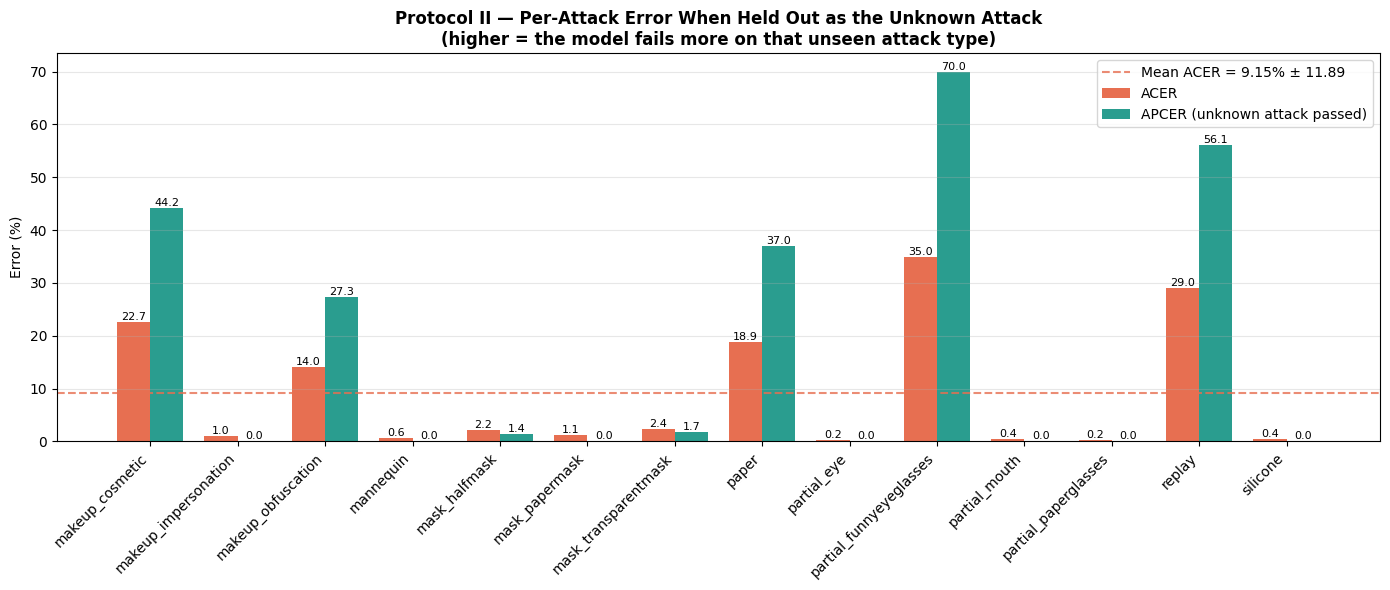


Attack (held-out)           ACER%   APCER%   BPCER%     AUC%   TDR@1%
---------------------------------------------------------------------
makeup_cosmetic             22.69    44.23     1.15    93.56  5384.62
makeup_impersonation         0.96     0.00     1.92    99.82 10000.00
makeup_obfuscation          14.02    27.27     0.77    89.45  7272.73
mannequin                    0.57     0.00     1.15    99.62 10000.00
mask_halfmask                2.23     1.39     3.07    99.52  9444.44
mask_papermask               1.15     0.00     2.30   100.00 10000.00
mask_transparentmask         2.38     1.69     3.07    99.53  9830.51
paper                       18.90    37.04     0.77    97.23  7333.33
partial_eye                  0.19     0.00     0.38    99.73 10000.00
partial_funnyeyeglasses     35.00    70.00     0.00    94.44  4812.50
partial_mouth                0.38     0.00     0.77    99.63 10000.00
partial_paperglasses         0.19     0.00     0.38    99.63 10000.00
replay             

In [43]:
# ============================================================================
#  PROTOCOL II — Per-Attack Results Bar Chart + Summary Table
#  (uses protocol2_results). Matches the OULU Protocol 4 (LOCO) output format:
#  table with TDR@1% column, separate MEAN/STD rows, a "Headline" summary
#  line, and saved .txt + .json summary files alongside the chart.
# ============================================================================
import json

# Safety: make sure results exist
assert len(protocol2_results) > 0, "protocol2_results is empty — run the training loop first."

result_dir = PROTOCOL_CONFIG_SiW[2]['result']
result_dir.mkdir(parents=True, exist_ok=True)

# ---- Keep attacks in ORIGINAL fold order (not sorted by ACER) ----
# OULU's Protocol 4 output lists folds 1-6 in the order they were run, not
# ranked by error — matching that here instead of sorting descending by ACER.
res = protocol2_results
attacks = [r['attack'] for r in res]
acer    = np.array([r['ACER']  * 100 for r in res])
apcer   = np.array([r['APCER'] * 100 for r in res])
bpcer   = np.array([r['BPCER'] * 100 for r in res])
auc     = np.array([r['AUC']   * 100 for r in res])
tdr     = np.array([r['TDR']   * 100 for r in res])   # <- added: your original script never used TDR at all

mean_acer, std_acer   = acer.mean(),  acer.std()
mean_apcer            = apcer.mean()
mean_bpcer            = bpcer.mean()
mean_auc              = auc.mean()
mean_tdr, std_tdr      = tdr.mean(),   tdr.std()       # <- added: needed for the "Headline" line

# ---- Grouped bars: ACER and APCER side by side per attack ----
x = np.arange(len(attacks))
w = 0.38
fig, ax = plt.subplots(figsize=(14, 6))
bars_acer  = ax.bar(x - w/2, acer,  w, label='ACER',  color='#e76f51')
bars_apcer = ax.bar(x + w/2, apcer, w, label='APCER (unknown attack passed)', color='#2a9d8f')

# Mean ACER reference line
ax.axhline(mean_acer, color='#e76f51', ls='--', lw=1.5, alpha=0.8,
           label=f'Mean ACER = {mean_acer:.2f}% ± {std_acer:.2f}')

# Value labels on bars
for b in bars_acer:
    ax.text(b.get_x()+b.get_width()/2, b.get_height(), f'{b.get_height():.1f}',
            ha='center', va='bottom', fontsize=8)
for b in bars_apcer:
    ax.text(b.get_x()+b.get_width()/2, b.get_height(), f'{b.get_height():.1f}',
            ha='center', va='bottom', fontsize=8)

ax.set_title('Protocol II — Per-Attack Error When Held Out as the Unknown Attack\n'
             '(higher = the model fails more on that unseen attack type)', fontweight='bold')
ax.set_ylabel('Error (%)')
ax.set_xticks(x)
ax.set_xticklabels(attacks, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()

chart_path = result_dir / 'protocol2_per_attack_barchart.png'
plt.savefig(chart_path, dpi=120, bbox_inches='tight')
plt.show()

# ============================================================================
# ---- Print the table: now includes TDR@1%, and MEAN/STD as SEPARATE rows
#      (your original script combined them into one "MEAN ± STD" line;
#       OULU prints them as two distinct rows, so this matches that) ----
# ============================================================================
table_lines = []   # collected so the same text can be written to summary_table.txt below
table_lines.append(f"{'Attack (held-out)':<24}{'ACER%':>9}{'APCER%':>9}{'BPCER%':>9}{'AUC%':>9}{'TDR@1%':>9}")
table_lines.append('-' * 69)
for r in res:
    table_lines.append(f"{r['attack']:<24}{r['ACER']*100:>9.2f}{r['APCER']*100:>9.2f}"
                        f"{r['BPCER']*100:>9.2f}{r['AUC']*100:>9.2f}{r['TDR']:>9.2f}")
table_lines.append('-' * 69)
table_lines.append(f"{'MEAN':<24}{mean_acer:>9.2f}{mean_apcer:>9.2f}{mean_bpcer:>9.2f}{mean_auc:>9.2f}{mean_tdr:>9.2f}")
table_lines.append(f"{'STD':<24}{std_acer:>9.2f}{apcer.std():>9.2f}{bpcer.std():>9.2f}{auc.std():>9.2f}{std_tdr:>9.2f}")
table_lines.append('')
table_lines.append(f"Headline (LOAO): ACER {mean_acer:.2f}% +/- {std_acer:.2f}  |  "
                    f"TDR@1% {mean_tdr:.2f}% +/- {std_tdr:.2f}")

print('\n' + '\n'.join(table_lines))

# ---- Save readable summary table as .txt (matches OULU's saved artifacts) ----
summary_table_path = result_dir / 'summary_table_protocol_2.txt'
with open(summary_table_path, 'w') as f:
    f.write('\n'.join(table_lines))
print(f"\nSaved readable summary table to {summary_table_path}")

# ---- Save summary as .json (matches OULU's saved artifacts) ----
summary_json_path = result_dir / 'test_metrics_protocol_2.json'
with open(summary_json_path, 'w') as f:
    json.dump({
        'per_attack': res,
        'mean_acer': float(mean_acer), 'std_acer': float(std_acer),
        'mean_apcer': float(mean_apcer),
        'mean_bpcer': float(mean_bpcer),
        'mean_auc': float(mean_auc),
        'mean_tdr': float(mean_tdr), 'std_tdr': float(std_tdr),
    }, f, indent=2)
print(f"Saved summary to {summary_json_path}")

In [41]:
# how many test spoofs each attack had (reliability indicator)
for r in protocol2_results:
    n_spoof = (spoof_pool_df['attack_type'] == r['attack']).sum()
    print(f"{r['attack']:<24} ACER {r['ACER']*100:5.2f}%  (n_spoof={n_spoof})")

makeup_cosmetic          ACER 22.69%  (n_spoof=52)
makeup_impersonation     ACER  0.96%  (n_spoof=61)
makeup_obfuscation       ACER 14.02%  (n_spoof=22)
mannequin                ACER  0.57%  (n_spoof=40)
mask_halfmask            ACER  2.23%  (n_spoof=72)
mask_papermask           ACER  1.15%  (n_spoof=17)
mask_transparentmask     ACER  2.38%  (n_spoof=59)
paper                    ACER 18.90%  (n_spoof=135)
partial_eye              ACER  0.19%  (n_spoof=57)
partial_funnyeyeglasses  ACER 35.00%  (n_spoof=160)
partial_mouth            ACER  0.38%  (n_spoof=29)
partial_paperglasses     ACER  0.19%  (n_spoof=76)
replay                   ACER 29.02%  (n_spoof=98)
silicone                 ACER  0.38%  (n_spoof=17)


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

<div style="background-color: #FFB6C1; padding: 12px; border-radius: 6px;">
    <h2 style="margin: 0;">Protocol 3 – Cross-domain Spoof Detection</h2>
</div>

## **Protocol 3:**
## **Check the protocol 3 video files**
## **Perform same sanity checks**

In [55]:
# ============================================================================
#  SiW PROTOCOL III — CHECK 1: Match check (5 domains)
# ============================================================================
#  Mirrors Protocol II's Check 1, but P3 has a different shape: ONE source
#  domain (A) used for training, and FOUR separate target domains (B/C/D/E)
#  used only for testing — no per-attack fold loop like P2's leave-one-out.
#  This checks: if every name in each domain's partition file actually
#  has a matching video in df
# ============================================================================

def _read_ids(p):
    # Reads a partition .txt file (one video/subject name per line) into a set
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pc3 = PROTOCOL_CONFIG_SiW[3]      # <- fixed: was CFG.PROTOCOL_CONFIG[3], which doesn't match your actual config name

domain_files = {
    'A (source)': pc3['train_source_domain_A_P3'],
    'B (spoof)' : pc3['test_spoof_domain_B_P3'],
    'C (race)'  : pc3['test_race_domain_C_P3'],
    'D (age)'   : pc3['test_age_domain_D_P3'],
    'E (illu)'  : pc3['test_illu_domain_E_P3'],
}

df_ids = set(df['subject_id'])   # every subject_id that actually exists in df

print("Match check (Protocol 3 — all 5 domains):")
domain_dfs = {}
for name, fpath in domain_files.items():
    names = _read_ids(fpath)
    matched = names & df_ids
    domain_dfs[name] = df[df['subject_id'].isin(matched)].copy()
    print(f"  Total no of {name:<12} names in partition = {len(names):>5} | "
          f"Total no of videos that actually matched those names = {len(matched):>5}")

print(f"\nProtocol 3  ->  " + " | ".join(f"{name}: {len(d):,}" for name, d in domain_dfs.items()))

print("\nPer-domain real/fake counts:")
for name, d in domain_dfs.items():
    n_real = (d['label'] == 0).sum()
    n_fake = (d['label'] == 1).sum()
    print(f"  {name:<12}: real {n_real:>4} | fake {n_fake:>4}")

Match check (Protocol 3 — all 5 domains):
  Total no of A (source)   names in partition =   902 | Total no of videos that actually matched those names =   854
  Total no of B (spoof)    names in partition =    54 | Total no of videos that actually matched those names =    54
  Total no of C (race)     names in partition =    55 | Total no of videos that actually matched those names =    55
  Total no of D (age)      names in partition =    57 | Total no of videos that actually matched those names =    57
  Total no of E (illu)     names in partition =    44 | Total no of videos that actually matched those names =    44

Protocol 3  ->  A (source): 854 | B (spoof): 54 | C (race): 55 | D (age): 57 | E (illu): 44

Per-domain real/fake counts:
  A (source)  : real  407 | fake  447
  B (spoof)   : real    8 | fake   46
  C (race)    : real   37 | fake   18
  D (age)     : real   39 | fake   18
  E (illu)    : real   26 | fake   18


In [56]:
# ============================================================================
#  SiW PROTOCOL III — CHECK 2: Missing names
#  Which partition-file names have NO matching video in df — checked
#  separately for each of the 5 domains (A source + B/C/D/E targets).
# ============================================================================

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pc3 = PROTOCOL_CONFIG_SiW[3]

domain_files = {
    'A (source)': pc3['train_source_domain_A_P3'],
    'B (spoof)' : pc3['test_spoof_domain_B_P3'],
    'C (race)'  : pc3['test_race_domain_C_P3'],
    'D (age)'   : pc3['test_age_domain_D_P3'],
    'E (illu)'  : pc3['test_illu_domain_E_P3'],
}

df_ids = set(df['subject_id'])

for name, fpath in domain_files.items():
    names = _read_ids(fpath)
    missing = names - df_ids
    print(f"{len(missing)} {name} names have no matching video:")
    print(missing)
    print()

48 A (source) names have no matching video:
{'Partial_Paperglass_89', 'Partial_Paperglass_94', 'Partial_Paperglass_81', 'Partial_Paperglass_103', 'Partial_Paperglass_70', 'Partial_Paperglass_83', 'Partial_Paperglass_118', 'Partial_Paperglass_93', 'Partial_Paperglass_99', 'Partial_Paperglass_72', 'Partial_Paperglass_110', 'Partial_Paperglass_112', 'Partial_Paperglass_115', 'Partial_Paperglass_113', 'Partial_Paperglass_96', 'Partial_Paperglass_119', 'Partial_Paperglass_91', 'Partial_Paperglass_120', 'Partial_Paperglass_78', 'Partial_Paperglass_117', 'Partial_Paperglass_116', 'Partial_Paperglass_114', 'Partial_Paperglass_98', 'Partial_Paperglass_104', 'Partial_Paperglass_77', 'Partial_Paperglass_87', 'Partial_Paperglass_82', 'Partial_Paperglass_84', 'Partial_Paperglass_97', 'Partial_Paperglass_108', 'Partial_Paperglass_75', 'Partial_Paperglass_102', 'Partial_Paperglass_109', 'Partial_Paperglass_79', 'Mask_Silicone_19', 'Partial_Paperglass_107', 'Partial_Paperglass_76', 'Partial_Paperglass

In [57]:
# ============================================================================
#  SiW PROTOCOL III — CHECK 3: INVESTIGATE MISSING NAMES (5 domains)
# ============================================================================
#  Same 5-step method as Protocol II's investigation, run once per domain
#  instead of once per name-pool (P3 has 5 domains: A source + B/C/D/E targets).
# ============================================================================

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pc3 = PROTOCOL_CONFIG_SiW[3]

domain_files = {
    'A (source)': pc3['train_source_domain_A_P3'],
    'B (spoof)' : pc3['test_spoof_domain_B_P3'],
    'C (race)'  : pc3['test_race_domain_C_P3'],
    'D (age)'   : pc3['test_age_domain_D_P3'],
    'E (illu)'  : pc3['test_illu_domain_E_P3'],
}

df_ids = set(df['subject_id'])   # every subject_id that actually exists in df

for name, fpath in domain_files.items():
    pool_ids = _read_ids(fpath)

    print("\n" + "=" * 70)
    print(f"DOMAIN: {name}")
    print("=" * 70)

    # --- 1. What's missing ---
    missing = pool_ids - df_ids
    print(f"Missing {name}: {len(missing)}\n")

    if not missing:
        print(f"  Nothing missing in {name} — skipping steps 2-5 for this domain.")
        continue

    # --- 2. Show examples side by side: file names vs df names ---
    print(f"Sample names IN THE {name.upper()} PARTITION FILE (missing from df):")
    print("  ", sorted(missing)[:10])
    print("\nSample names IN df (subject_id):")
    print("  ", sorted(df_ids)[:10])

    # --- 3. Format comparison — are they the same STYLE? ---
    example_missing = sorted(missing)[0]
    example_df      = sorted(df_ids)[0]
    print(f"\nFormat check:")
    print(f"  Missing file name : '{example_missing}'  (len={len(example_missing)})")
    print(f"  df subject_id     : '{example_df}'  (len={len(example_df)})")
    print(f"  Missing has spaces? {' ' in example_missing}")
    print(f"  Missing has comma?  {',' in example_missing}")   # leftover label prefix?
    print(f"  Missing lowercase?  {example_missing.islower()}")

    # --- 4. Is it a genuine missing FILE? Check if the video exists on disk ---
    print("\nChecking if missing videos exist on disk:")
    for nm in sorted(missing)[:5]:
        matches = list(REAL_DIR_SiW.parent.rglob(f"*{nm}*"))   # adjust root as needed
        if matches:
            print(f"  '{nm}' \u2192 FOUND on disk: {matches[0].name}  (so it's a MATCHING/format issue)")
        else:
            print(f"  '{nm}' \u2192 NOT found on disk (genuinely missing video)")

    # --- 5. Near-match check: is there a df name that's CLOSE to a missing one? ---
    print("\nNear-match check (df names containing the missing name or vice versa):")
    for nm in sorted(missing)[:5]:
        near = [d for d in df_ids if nm in d or d in nm]
        print(f"  '{nm}' \u2192 near matches in df: {near[:3] if near else 'NONE'}")


DOMAIN: A (source)
Missing A (source): 48

Sample names IN THE A (SOURCE) PARTITION FILE (missing from df):
   ['Mask_Silicone_18', 'Mask_Silicone_19', 'Partial_Paperglass_102', 'Partial_Paperglass_103', 'Partial_Paperglass_104', 'Partial_Paperglass_105', 'Partial_Paperglass_107', 'Partial_Paperglass_108', 'Partial_Paperglass_109', 'Partial_Paperglass_110']

Sample names IN df (subject_id):
   ['Live_1', 'Live_10', 'Live_100', 'Live_101', 'Live_102', 'Live_103', 'Live_105', 'Live_106', 'Live_107', 'Live_108']

Format check:
  Missing file name : 'Mask_Silicone_18'  (len=16)
  df subject_id     : 'Live_1'  (len=6)
  Missing has spaces? False
  Missing has comma?  False
  Missing lowercase?  False

Checking if missing videos exist on disk:
  'Mask_Silicone_18' → NOT found on disk (genuinely missing video)
  'Mask_Silicone_19' → NOT found on disk (genuinely missing video)
  'Partial_Paperglass_102' → NOT found on disk (genuinely missing video)
  'Partial_Paperglass_103' → NOT found on di

In [58]:
# ============================================================================
#  SiW PROTOCOL III — CHECK 4: Disjointness check
#  (verification only — no training)
# ============================================================================
#  For checking P3's disjointness, we need:
#    (a) source domain A vs EACH target domain (B/C/D/E) — subject overlap
#        MUST be 0, or the cross-domain evaluation is contaminated
#    (b) once Train/Val is carved OUT of A (per the planning decision to
#        keep val subject-disjoint, same approach as P1/P2), Train ∩ Val
#        subjects MUST also be 0
# ============================================================================

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pc3 = PROTOCOL_CONFIG_SiW[3]

source_ids = _read_ids(pc3['train_source_domain_A_P3'])
df_ids = set(df['subject_id'])
source_df = df[df['subject_id'].isin(source_ids & df_ids)].copy()

target_files = {
    'B (spoof)': pc3['test_spoof_domain_B_P3'],
    'C (race)' : pc3['test_race_domain_C_P3'],
    'D (age)'  : pc3['test_age_domain_D_P3'],
    'E (illu)' : pc3['test_illu_domain_E_P3'],
}

# ----------------------------------------------------------------------------
# PART A — Source (A) vs Target (B/C/D/E) subject overlap
# ----------------------------------------------------------------------------
print("=" * 78)
print("PART A — Source (A) vs Target (B/C/D/E) subject overlap (must be 0)")
print("=" * 78)
print(f"{'Target':<12}{'A∩Target':>10}{'status':>9}")
print('-' * 32)

flagged = []
for name, fpath in target_files.items():
    tids = _read_ids(fpath)
    overlap = len(source_ids & tids)
    status = 'OK' if overlap == 0 else 'CHECK!'
    if overlap != 0:
        flagged.append(name)
    print(f"{name:<12}{overlap:>10}{status:>9}")

if flagged:
    print(f"\nDomains needing attention (A overlaps with target): {flagged}")
else:
    print("\nAll target domains are subject-disjoint from source A.")

# ----------------------------------------------------------------------------
# PART B — Train/Val split carved OUT of domain A (subject-disjoint), same
# approach as P1/P2's val carve — this is the planning Decision 1 we settled on
# ----------------------------------------------------------------------------
print("\n" + "=" * 78)
print("PART B — Train/Val split within domain A (must be subject-disjoint)")
print("=" * 78)

gss = GroupShuffleSplit(n_splits=1, test_size=CFG.VAL_RATIO, random_state=SEED)
tr_idx, val_idx = next(gss.split(source_df, groups=source_df['subject_id']))
train_df_P3 = source_df.iloc[tr_idx].copy()
val_df_P3   = source_df.iloc[val_idx].copy()

tr_s = set(train_df_P3['subject_id'])
vl_s = set(val_df_P3['subject_id'])
trval_overlap = len(tr_s & vl_s)

print(f"Train: {len(train_df_P3)} videos | {len(tr_s)} subjects")
print(f"Val  : {len(val_df_P3)} videos | {len(vl_s)} subjects")
print(f"Train ∩ Val subjects: {trval_overlap}  ({'OK' if trval_overlap == 0 else 'CHECK!'})")

PART A — Source (A) vs Target (B/C/D/E) subject overlap (must be 0)
Target        A∩Target   status
--------------------------------
B (spoof)            0       OK
C (race)             0       OK
D (age)              0       OK
E (illu)             0       OK

All target domains are subject-disjoint from source A.

PART B — Train/Val split within domain A (must be subject-disjoint)
Train: 725 videos | 725 subjects
Val  : 129 videos | 129 subjects
Train ∩ Val subjects: 0  (OK)


Per-domain real/fake counts:
  A (source)  : real  407 | fake  447
  B (spoof)   : real    8 | fake   46
  C (race)    : real   37 | fake   18
  D (age)     : real   39 | fake   18
  E (illu)    : real   26 | fake   18

Per-domain attack-type composition:

  A (source):
attack_type
partial_paperglasses    71
mask_halfmask           65
makeup_impersonation    54
partial_eye             53
mask_transparentmask    52
replay                  52
paper                   49
makeup_obfuscation      19
mask_papermask          16
silicone                16

  B (spoof):
attack_type
partial_funnyeyeglasses    26
makeup_cosmetic             9
mannequin                   8
paper                       2
replay                      1

  C (race):
attack_type
partial_mouth    12
paper             6

  D (age):
attack_type
partial_mouth    12
paper             5
replay            1

  E (illu):
attack_type
partial_mouth    12
paper             5
replay            1

Reliability flag (attack types with 

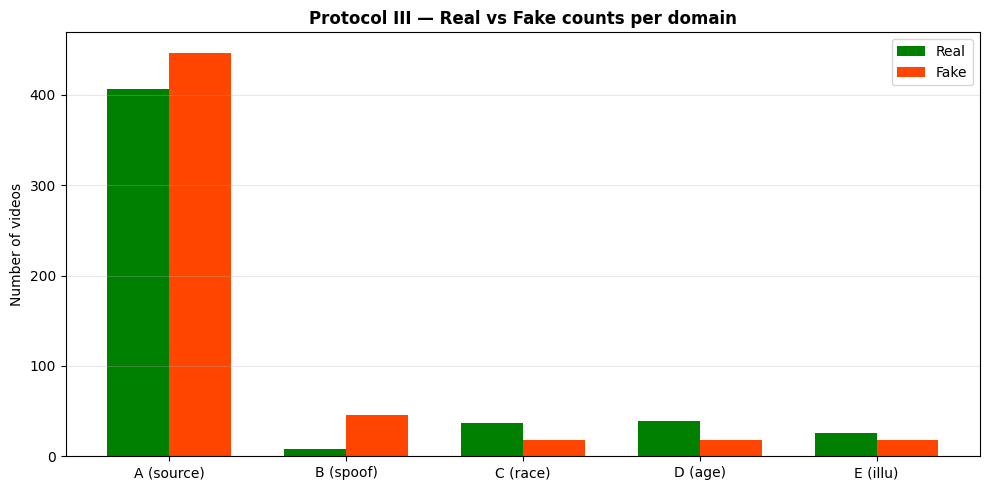

In [59]:
# ==============================================================================================
#  SiW PROTOCOL III — CHECK 5: Per-domain distribution
# ==============================================================================================
#  P3 has no shared pool — each of the 5 domains (A/B/C/D/E) is its own separate 
# set of videos with its own composition, so this reports real/fake counts AND attack-type
#  composition PER domain, plus a reliability flag for thin attack counts.
# ==============================================================================================
def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pc3 = PROTOCOL_CONFIG_SiW[3]

domain_files = {
    'A (source)': pc3['train_source_domain_A_P3'],
    'B (spoof)' : pc3['test_spoof_domain_B_P3'],
    'C (race)'  : pc3['test_race_domain_C_P3'],
    'D (age)'   : pc3['test_age_domain_D_P3'],
    'E (illu)'  : pc3['test_illu_domain_E_P3'],
}

df_ids = set(df['subject_id'])
domain_dfs = {name: df[df['subject_id'].isin(_read_ids(fpath) & df_ids)].copy()
              for name, fpath in domain_files.items()}

RELIABILITY_THRESHOLD = 30   # same threshold used in P2's Check 5

print("Per-domain real/fake counts:")
for name, d in domain_dfs.items():
    n_real = (d['label'] == 0).sum()
    n_fake = (d['label'] == 1).sum()
    print(f"  {name:<12}: real {n_real:>4} | fake {n_fake:>4}")

print("\nPer-domain attack-type composition:")
small_flags = []
for name, d in domain_dfs.items():
    vc = d[d['label'] == 1]['attack_type'].value_counts()
    print(f"\n  {name}:")
    print(vc.to_string() if len(vc) else "    (no spoof videos in this domain)")
    small = vc[vc < RELIABILITY_THRESHOLD]
    for atk, n in small.items():
        small_flags.append((name, atk, n))

print(f"\nReliability flag (attack types with < {RELIABILITY_THRESHOLD} videos in a domain "
      f"-> noisy per-attack breakdowns if you slice results that finely):")
if small_flags:
    for name, atk, n in small_flags:
        print(f" - {name} / {atk}: {n} videos")
else:
    print("  None — all attack types have >= 30 videos in every domain.")

# ---- Bar chart: real vs fake counts per domain ----
names = list(domain_dfs.keys())
real_counts = [(d['label'] == 0).sum() for d in domain_dfs.values()]
fake_counts = [(d['label'] == 1).sum() for d in domain_dfs.values()]

x = np.arange(len(names))
w = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w/2, real_counts, w, label='Real', color='green')
ax.bar(x + w/2, fake_counts, w, label='Fake', color='orangered')
ax.set_title('Protocol III — Real vs Fake counts per domain', fontweight='bold')
ax.set_ylabel('Number of videos')
ax.set_xticks(x); ax.set_xticklabels(names)
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **For all the data in Protocol 3, check if the cache files are correctly formed:**

In [60]:
# ============================================================================
#  SiW PROTOCOL III — CACHE COVERAGE CHECK — directories, FFT files, flow files
# ============================================================================
#  For every video in domain A (P3's ONLY training data), this verifies three
#  levels of cache completeness:
#     1. the precompute DIRECTORY exists
#     2. all N_FRAMES  freq_*.npy  (FFT) files are present
#     3. all N_FRAMES  flow_*.npy  (optical flow) files are present
# ============================================================================
from pathlib import Path

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pc3 = PROTOCOL_CONFIG_SiW[3]
source_ids = _read_ids(pc3['train_source_domain_A_P3'])
df_ids = set(df['subject_id'])

train_universe_df = df[df['subject_id'].isin(source_ids & df_ids)].copy()   # <- train_df_P1 -> domain A (all of it)

missing_dir  = []   # videos with NO precompute folder at all
missing_fft  = []   # videos whose folder exists but freq_*.npy files are incomplete
missing_flow = []   # videos whose folder exists but flow_*.npy files are incomplete

for _, row in train_universe_df.iterrows():
    vid_id  = Path(row['path']).stem
    vid_dir = CACHE_DIR_SiW / "precompute" / vid_id      # <- CACHE_DIR_OULU -> CACHE_DIR_SiW

    # ---- Level 1: does the cache directory exist at all? ----
    if not vid_dir.exists():
        missing_dir.append(vid_id)
        continue                       # no folder -> can't check files inside

    # ---- Level 2: count the FFT (freq) files inside the folder ----
    fft_files = list(vid_dir.glob('freq_*.npy'))
    if len(fft_files) < CFG.N_FRAMES:  # expect one freq file per frame
        missing_fft.append((vid_id, len(fft_files)))

    # ---- Level 3: count the optical-flow files inside the folder ----
    flow_files = list(vid_dir.glob('flow_*.npy'))
    if len(flow_files) < CFG.N_FRAMES: # expect one flow file per frame
        missing_flow.append((vid_id, len(flow_files)))

# ----------------------------------------------------------------------------
#  Report
# ----------------------------------------------------------------------------
total = len(train_universe_df)
print(f"Total training videos (domain A): {total}")
print(f"Missing cache directory         : {len(missing_dir)}")
print(f"Incomplete FFT (freq_*.npy)     : {len(missing_fft)}")
print(f"Incomplete flow (flow_*.npy)    : {len(missing_flow)}")

# Show a few examples for each problem level (only if any exist)
if missing_dir:
    print("\nExamples — missing directory:")
    print("  ", missing_dir[:10])
if missing_fft:
    print("\nExamples — incomplete FFT (vid_id, n_freq_files):")
    print("  ", missing_fft[:10])
if missing_flow:
    print("\nExamples — incomplete flow (vid_id, n_flow_files):")
    print("  ", missing_flow[:10])

# Clean bill of health
if not (missing_dir or missing_fft or missing_flow):
    print("\nAll cache directories, FFT files, and flow files are complete.")

Total training videos (domain A): 854
Missing cache directory         : 0
Incomplete FFT (freq_*.npy)     : 0
Incomplete flow (flow_*.npy)    : 0

All cache directories, FFT files, and flow files are complete.


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 3 - Check how many of the total videos got letterboxed or aligned, by using their usable fraction:**

Collected usable_frac for 854 videos (out of 854 in domain A)


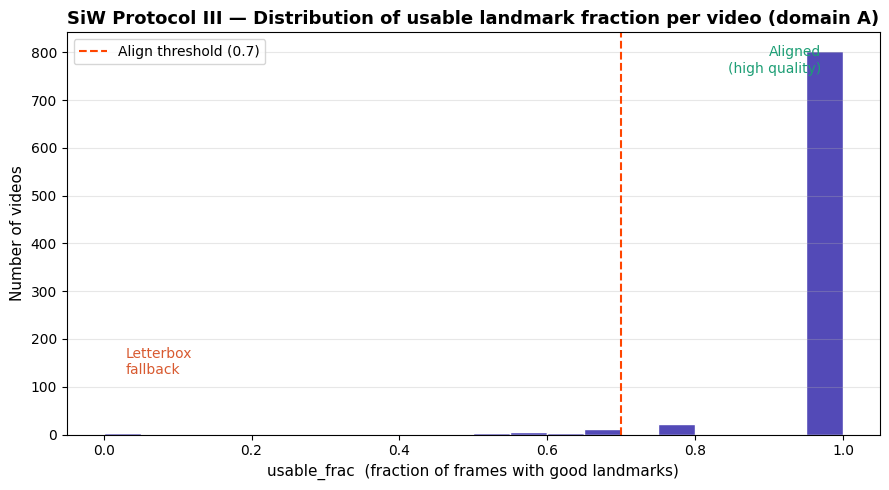

In [61]:
# ============================================================================
#  SiW PROTOCOL III — USABLE-LANDMARK-FRACTION DISTRIBUTION
# ============================================================================
#  Unlike P2 (which pools live_train + spoof_pool across 14 folds), P3 trains
#  on a SINGLE domain (A) — so the "training universe" here is simply
#  domain A in full (Train + Val together, since Val is carved OUT of A,
#  not from a separate source). No pooling/union logic needed like P2 had.
# ============================================================================
from pathlib import Path
import json
import matplotlib.pyplot as plt

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pc3 = PROTOCOL_CONFIG_SiW[3]
source_ids = _read_ids(pc3['train_source_domain_A_P3'])
df_ids = set(df['subject_id'])

train_universe_df = df[df['subject_id'].isin(source_ids & df_ids)].copy()   # all of domain A

# --- Build the list of usable_frac values from cached video_meta.json ---
fracs = []
for _, row in train_universe_df.iterrows():
    vid_id = Path(row['path']).stem
    mp = CACHE_DIR_SiW / "precompute" / vid_id / "video_meta.json"
    if mp.exists():
        fracs.append(json.load(open(mp))['usable_frac'])

print(f"Collected usable_frac for {len(fracs)} videos "
      f"(out of {len(train_universe_df)} in domain A)")

# --- Plot ---
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(fracs, bins=20, color='#534AB7', edgecolor='white')
ax.set_title('SiW Protocol III — Distribution of usable landmark fraction per video (domain A)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('usable_frac  (fraction of frames with good landmarks)', fontsize=11)
ax.set_ylabel('Number of videos', fontsize=11)

ax.axvline(CFG.ALIGN_MIN_FRAC, color='orangered', linestyle='--', linewidth=1.5,
           label=f'Align threshold ({CFG.ALIGN_MIN_FRAC})')

ax.text(0.97, ax.get_ylim()[1] * 0.9, 'Aligned\n(high quality)',
        ha='right', color='#1D9E75', fontsize=10)
ax.text(0.03, ax.get_ylim()[1] * 0.15, 'Letterbox\nfallback',
        ha='left', color='#D85A30', fontsize=10)

ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [62]:
# ============================================================================
#  SiW PROTOCOL III — LETTERBOXED VIDEOS (usable_frac BELOW align threshold)
# ============================================================================
#  Same scoping as Check 6: P3 trains on a single domain (A), so the universe
#  here is domain A in full — no live_train/spoof_pool union needed like P2.
#
#  Note on attack_type for live videos: same fix as P2's version — live rows
#  (label=0) get labeled 'real' explicitly rather than falling through to
#  'unknown', so the per-attack breakdown isn't misleading.
# ============================================================================
from pathlib import Path
import json
from collections import Counter

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pc3 = PROTOCOL_CONFIG_SiW[3]
source_ids = _read_ids(pc3['train_source_domain_A_P3'])
df_ids = set(df['subject_id'])

train_universe_df = df[df['subject_id'].isin(source_ids & df_ids)].copy()   # all of domain A

# --- Collect videos below the align threshold, WITH their attack types ---
low_videos = []
for _, row in train_universe_df.iterrows():
    vid_id = Path(row['path']).stem
    mp = CACHE_DIR_SiW / "precompute" / vid_id / "video_meta.json"
    if mp.exists():
        uf = json.load(open(mp))['usable_frac']
        if uf < CFG.ALIGN_MIN_FRAC:          # below threshold -> letterboxed
            atk = row.get('attack_type', 'unknown')
            if row['label'] == 0:            # live video: not an attack, label explicitly
                atk = 'real'
            low_videos.append({
                'vid_id': vid_id,
                'label': row['label'],
                'attack_type': atk,
                'usable_frac': round(uf, 3),
            })

print(f"Total letterboxed (usable_frac < {CFG.ALIGN_MIN_FRAC}): {len(low_videos)}\n")

total = len(train_universe_df)
pct = (len(low_videos) / total * 100) if total else 0.0
print(f"Total videos (domain A): {total}")
print(f"Letterboxed %%          : {pct:.6f}%")

if low_videos:
    attack_counts = Counter(v['attack_type'] for v in low_videos)
    print("\nLetterboxed videos by attack type:")
    for atk, cnt in attack_counts.most_common():
        print(f"  {atk:30s} : {cnt}")

    label_counts = Counter(v['label'] for v in low_videos)
    print(f"\nBy label: {dict(label_counts)}")

    print("\nIndividual videos:")
    for v in low_videos:
        print(f"  {v['vid_id']:25s} label={v['label']} attack={v['attack_type']:20s} uf={v['usable_frac']}")
else:
    print("\nNo letterboxed videos — all videos met the alignment threshold.")

Total letterboxed (usable_frac < 0.7): 29

Total videos (domain A): 854
Letterboxed %%          : 3.395785%

Letterboxed videos by attack type:
  real                           : 16
  mask_transparentmask           : 4
  mask_halfmask                  : 3
  partial_paperglasses           : 3
  paper                          : 2
  silicone                       : 1

By label: {0: 16, 1: 13}

Individual videos:
  Live_111                  label=0 attack=real                 uf=0.688
  Live_113                  label=0 attack=real                 uf=0.688
  Live_160                  label=0 attack=real                 uf=0.625
  Live_161                  label=0 attack=real                 uf=0.562
  Live_214                  label=0 attack=real                 uf=0.688
  Live_227                  label=0 attack=real                 uf=0.562
  Live_232                  label=0 attack=real                 uf=0.688
  Live_248                  label=0 attack=real                 uf=0.688
  L

In [63]:
# Diagnostics to confirm the letterbox check is actually reading files
# (not silently finding nothing). Checks:
#   (1) how many meta files were actually found
#   (2) how many of those are letterboxed
# (1) is the key diagnostic — confirms the check isn't silently failing.
#
# Scoped to domain A only (P3's training universe), same as Checks 6 and 7.
found = 0
low_videos = []
for _, row in train_universe_df.iterrows():          # train_universe_df = domain A (built above)
    vid_id = Path(row['path']).stem
    mp = CACHE_DIR_SiW / "precompute" / vid_id / "video_meta.json"
    if mp.exists():
        found += 1                          # ← count files actually found
        uf = json.load(open(mp))['usable_frac']
        if uf < CFG.ALIGN_MIN_FRAC:
            low_videos.append({...})
print(f"Meta files found: {found} / {len(train_universe_df)}")   # ← the key diagnostic
print(f"Letterboxed: {len(low_videos)}")

Meta files found: 854 / 854
Letterboxed: 29


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

## **Protocol 3 - Model Training:**
- ## every loop has its own datasets split creation, data loaders creation, weighted sampler creation on training data, and optimisation declarations.

In [58]:
from Functions.run_epochs_17 import *
from Functions.data_pipeline_setup_7 import *
from Functions.weighted_sampler_8 import *
from Functions.full_model_pipeline_13 import *
from Functions.loss_functions_14 import *
from Functions.optimiser_and_scheduler_15 import *

# ============================================================================
#  PROTOCOL III — Cross-domain Spoof Detection (full training)
#  ONE training run on source domain A, then evaluate that SAME model on the
#  4 target domains (B/C/D/E). Report per-domain + mean ± std.
# ============================================================================

ACTIVE_PROTOCOL = 3
pcfg = PROTOCOL_CONFIG_SiW[ACTIVE_PROTOCOL]          # <- fixed: was CFG.PROTOCOL_CONFIG[...], wrong variable entirely
Path(pcfg['ckpt_prefix']).parent.mkdir(parents=True, exist_ok=True)   # <- fixed: derived from ckpt_prefix instead of a separate CFG.CKPT_DIR global
result_dir = pcfg['result']
result_dir.mkdir(parents=True, exist_ok=True)

BEST_CKPT = Path(str(pcfg['ckpt_prefix']) + 'sourceA.pth')   # single model trained on A

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

# ============================================================================
#  PART 1 — Build the SOURCE-A split (train + subject-disjoint val)
# ============================================================================
source_ids = _read_ids(pcfg['train_source_domain_A_P3'])
source_full_df = df[df['subject_id'].isin(source_ids)].copy()
print(f'Source A: {len(source_ids)} file ids | {len(source_full_df)} videos '
      f'| real {(source_full_df["label"]==0).sum()} | fake {(source_full_df["label"]==1).sum()}')

gss = GroupShuffleSplit(n_splits=1, test_size=CFG.VAL_RATIO, random_state=SEED)
tr_idx, val_idx = next(gss.split(source_full_df, groups=source_full_df['subject_id']))
train_df_P3 = source_full_df.iloc[tr_idx].copy()
val_df_P3   = source_full_df.iloc[val_idx].copy()
print(f'  -> Train {len(train_df_P3)} | Val {len(val_df_P3)}')

# ---- datasets + loaders (train/val) ----
train_dataset_P3 = PADVideoDataset(train_df_P3, real_dir=REAL_DIR_SiW, cache_dir=CACHE_DIR_SiW,   # <- fixed: real_dir/cache_dir were missing
                                   transform=train_transforms, demo_mode=False,
                                   use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
val_dataset_P3   = PADVideoDataset(val_df_P3, real_dir=REAL_DIR_SiW, cache_dir=CACHE_DIR_SiW,      # <- fixed
                                   transform=val_transforms, demo_mode=False,
                                   use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)

train_sampler_P3 = make_weighted_sampler(train_dataset_P3)
train_loader_P3 = DataLoader(train_dataset_P3, batch_size=CFG.BATCH_SIZE, sampler=train_sampler_P3,
                             num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)
val_loader_P3   = DataLoader(val_dataset_P3, batch_size=CFG.BATCH_SIZE, shuffle=False,
                             num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)

# ============================================================================
#  PART 2 — Build model + loss + optimizer + scheduler + scaler (same as P1)
# ============================================================================
model = HybridPADModel().to(DEVICE)
criterion = CompoundFASLoss()

param_groups = [
    {'params': list(model.cnn_rgb.backbone.parameters()),  'lr': CFG.LR * 0.1, 'name': 'rgb_backbone'},
    {'params': list(model.cnn_rgb.projector.parameters()), 'lr': CFG.LR,       'name': 'rgb_proj'},
    {'params': list(model.cnn_freq.parameters()),          'lr': CFG.LR,       'name': 'freq_cnn'},
    {'params': list(model.cnn_flow.parameters()),          'lr': CFG.LR,       'name': 'flow_cnn'},
    {'params': list(model.stream_gate.parameters()),       'lr': CFG.LR,       'name': 'gate'},
    {'params': list(model.rnn_encoder.parameters()),       'lr': CFG.LR,       'name': 'rnn'},
    {'params': list(model.tf_encoder.parameters()),        'lr': CFG.LR,       'name': 'transformer'},
    {'params': list(model.classifier.parameters()),        'lr': CFG.LR,       'name': 'classifier'},
    {'params': list(model.proj_head.parameters()),         'lr': CFG.LR,       'name': 'supcon_head'},
]
optimizer = optim.AdamW(param_groups, weight_decay=CFG.WEIGHT_DECAY)
scheduler = WarmupCosineScheduler(optimizer, CFG.WARMUP_EPOCHS, CFG.N_EPOCHS, CFG.LR)
scaler    = torch.amp.GradScaler('cuda')
print('Model + optimizer ready.')

# ============================================================================
#  PART 3 — Train ONE model on domain A (with early stopping on val)
# ============================================================================
history = {
    'train_loss':[], 'val_loss':[], 'train_acer':[], 'val_acer':[],
    'train_bpcer':[], 'val_bpcer':[], 'val_apcer':[],
    'train_auc':[], 'val_auc':[], 'focal':[], 'supcon':[],
    'val_focal':[], 'val_supcon':[], 'lr':[]
}
best_val_acer = float('inf')
patience_counter = 0
PATIENCE = 7
train_start_time = time.time()

print(f'\nTraining on domain A for {CFG.N_EPOCHS} epochs | Patience={PATIENCE}')
print('=' * 80)

for epoch in range(CFG.N_EPOCHS):
    current_lr = scheduler.step(epoch)

    train_loss, train_metrics, _, _, train_comps, _ = run_epoch(
        model, train_loader_P3, optimizer, criterion, DEVICE, scaler, is_train=True, epoch=epoch)
    val_loss, val_metrics, _, _, val_comps, _ = run_epoch(
        model, val_loader_P3, optimizer, criterion, DEVICE, scaler=None, is_train=False, epoch=epoch)

    history['train_loss'].append(train_loss); history['val_loss'].append(val_loss)
    history['train_acer'].append(train_metrics['ACER']); history['val_acer'].append(val_metrics['ACER'])
    history['train_auc'].append(train_metrics['AUC']);   history['val_auc'].append(val_metrics['AUC'])
    history['train_bpcer'].append(train_metrics['BPCER']); history['val_bpcer'].append(val_metrics['BPCER'])
    history['val_apcer'].append(val_metrics['APCER'])
    history['val_focal'].append(val_comps['focal']); history['val_supcon'].append(val_comps['supcon'])
    history['focal'].append(train_comps['focal']);   history['supcon'].append(train_comps['supcon'])
    history['lr'].append(current_lr[-1] if isinstance(current_lr, (list, tuple)) else current_lr)

    improved = val_metrics['ACER'] < best_val_acer
    star = ' * BEST' if improved else ''
    print(f"Ep {epoch+1:02d}/{CFG.N_EPOCHS} | "
          f"Loss T:{train_loss:.4f} V:{val_loss:.4f} | "
          f"ACER T:{train_metrics['ACER']:.4f} V:{val_metrics['ACER']:.4f} | "
          f"AUC:{val_metrics['AUC']:.4f} | "
          f"[focal={train_comps['focal']:.3f} supcon={train_comps['supcon']:.3f}]{star}")

    if improved:
        best_val_acer = val_metrics['ACER']
        patience_counter = 0
        torch.save({'epoch': epoch+1, 'state_dict': model.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(),
                    'scaler_state_dict': scaler.state_dict(),
                    'val_acer': best_val_acer, 'val_metrics': val_metrics,
                    'history': history}, BEST_CKPT)
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'\nEarly stopping at epoch {epoch+1}')
            break

elapsed = time.time() - train_start_time
h, rem = divmod(int(elapsed), 3600); mnt, s = divmod(rem, 60)
print(f'\nTraining complete. Best val ACER: {best_val_acer:.4f} | Time {h:02d}:{mnt:02d}:{s:02d}')

# ============================================================================
#  PART 4 — Tune threshold on domain-A VALIDATION (once)
# ============================================================================
ckpt = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['state_dict'])
print(f'\nLoaded best (epoch {ckpt["epoch"]}, val ACER={ckpt["val_acer"]:.4f})')

_, _, val_probs, val_labels, _, _ = run_epoch(
    model, val_loader_P3, optimizer, criterion, DEVICE, scaler=None, is_train=False)
val_labels_int = val_labels.round().astype(int)
thresholds = np.linspace(0.1, 0.9, 100)
val_acers = [compute_pad_metrics(val_labels_int, val_probs, t)['ACER'] for t in thresholds]
best_thresh = thresholds[np.argmin(val_acers)]
print(f'Threshold tuned on domain-A val: {best_thresh:.3f}')

# ============================================================================
#  PART 5 — Evaluate the SAME model on each target domain (B/C/D/E)
# ============================================================================
target_files = {
    'B_spoof': pcfg['test_spoof_domain_B_P3'],
    'C_race' : pcfg['test_race_domain_C_P3'],
    'D_age'  : pcfg['test_age_domain_D_P3'],
    'E_illu' : pcfg['test_illu_domain_E_P3'],
}

protocol3_results = []

for dom_name, dom_file in target_files.items():
    dom_ids = _read_ids(dom_file)
    dom_df  = df[df['subject_id'].isin(dom_ids)].copy()

    if len(dom_df) == 0:
        print(f'  SKIP {dom_name} — 0 videos matched'); continue

    dom_ds = PADVideoDataset(dom_df, real_dir=REAL_DIR_SiW, cache_dir=CACHE_DIR_SiW,     # <- fixed: real_dir/cache_dir were missing
                             transform=val_transforms, demo_mode=False,
                             use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
    dom_loader = DataLoader(dom_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
                            num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)

    _, _, dom_probs, dom_labels, _, _ = run_epoch(
        model, dom_loader, optimizer, criterion, DEVICE, scaler=None, is_train=False)
    dom_labels_int = dom_labels.round().astype(int)
    m = compute_pad_metrics(dom_labels_int, dom_probs, threshold=best_thresh)
    tdr = compute_tdr_at_fdr(dom_labels_int, dom_probs, target_fdr=0.01)

    n_real = int((dom_df['label'] == 0).sum())
    n_fake = int((dom_df['label'] == 1).sum())

    print(f'  {dom_name:<10}: ACER {m["ACER"]*100:6.2f}% | APCER {m["APCER"]*100:6.2f}% | '
          f'BPCER {m["BPCER"]*100:6.2f}% | AUC {m["AUC"]*100:6.2f}%  '
          f'(n={len(dom_df)}, real {(dom_df["label"]==0).sum()}, fake {(dom_df["label"]==1).sum()})')

    protocol3_results.append({
        'domain': dom_name, 'ACER': m['ACER'], 'APCER': m['APCER'],
        'BPCER': m['BPCER'], 'AUC': m['AUC'], 'n_videos': int(len(dom_df)),
        'n_real': n_real, 'n_fake': n_fake,
        'TDR': tdr
    })

# ============================================================================
#  PART 6 — Aggregate: per-domain table + mean ± std
# ============================================================================
print('\n' + '=' * 70)
print('PROTOCOL III — SUMMARY (source A -> target domains)')
print('=' * 70)
print(f"{'Domain':<12}{'ACER%':>9}{'APCER%':>9}{'BPCER%':>9}{'AUC%':>9}")
print('-' * 48)
for r in protocol3_results:
    print(f"{r['domain']:<12}{r['ACER']*100:>9.2f}{r['APCER']*100:>9.2f}"
          f"{r['BPCER']*100:>9.2f}{r['AUC']*100:>9.2f}")

acers = np.array([r['ACER'] for r in protocol3_results]) * 100
aucs  = np.array([r['AUC']  for r in protocol3_results]) * 100
print('-' * 48)
print(f"{'MEAN':<12}{acers.mean():>9.2f}{'':>18}{aucs.mean():>9.2f}")
print(f"{'STD':<12}{acers.std():>9.2f}{'':>18}{aucs.std():>9.2f}")

import json
with open(result_dir / 'protocol3_summary.json', 'w') as f:
    json.dump({'per_domain': protocol3_results, 'threshold': float(best_thresh),
               'mean_acer': float(acers.mean()), 'std_acer': float(acers.std()),
               'mean_auc': float(aucs.mean()), 'std_auc': float(aucs.std())}, f, indent=2)
print(f'\nSummary saved to {result_dir / "protocol3_summary.json"}')

Source A: 902 file ids | 854 videos | real 407 | fake 447
  -> Train 725 | Val 129
Model + optimizer ready.

Training on domain A for 30 epochs | Patience=7


Ep 01/30 | Loss T:1.1420 V:0.8596 | ACER T:0.4111 V:0.1196 | AUC:0.9671 | [focal=0.101 supcon=3.472] * BEST


Ep 02/30 | Loss T:0.9371 V:0.8532 | ACER T:0.1049 V:0.0214 | AUC:0.9959 | [focal=0.028 supcon=3.030] * BEST


Ep 03/30 | Loss T:0.8350 V:1.0267 | ACER T:0.0153 V:0.0214 | AUC:0.9998 | [focal=0.004 supcon=2.770]


Ep 04/30 | Loss T:0.8469 V:0.8984 | ACER T:0.0110 V:0.0214 | AUC:0.9983 | [focal=0.013 supcon=2.780]


Ep 05/30 | Loss T:0.8220 V:1.0206 | ACER T:0.0067 V:0.0357 | AUC:1.0000 | [focal=0.002 supcon=2.734]


... (9 outputs left out)

  B_spoof   : ACER  30.43% | APCER  60.87% | BPCER   0.00% | AUC  90.22%  (n=54, real 8, fake 46)


  C_race    : ACER   6.76% | APCER   0.00% | BPCER  13.51% | AUC 100.00%  (n=55, real 37, fake 18)


  D_age     : ACER   1.28% | APCER   0.00% | BPCER   2.56% | AUC 100.00%  (n=57, real 39, fake 18)


  E_illu    : ACER   0.00% | APCER   0.00% | BPCER   0.00% | AUC 100.00%  (n=44, real 26, fake 18)

PROTOCOL III — SUMMARY (source A -> target domains)
Domain          ACER%   APCER%   BPCER%     AUC%
------------------------------------------------
B_spoof         30.43    60.87     0.00    90.22
C_race           6.76     0.00    13.51   100.00
D_age            1.28     0.00     2.56   100.00
E_illu           0.00     0.00     0.00   100.00
------------------------------------------------
MEAN             9.62                      97.55
STD             12.28                       4.24

Summary saved to output_siW/results/protocol_3/protocol3_summary.json


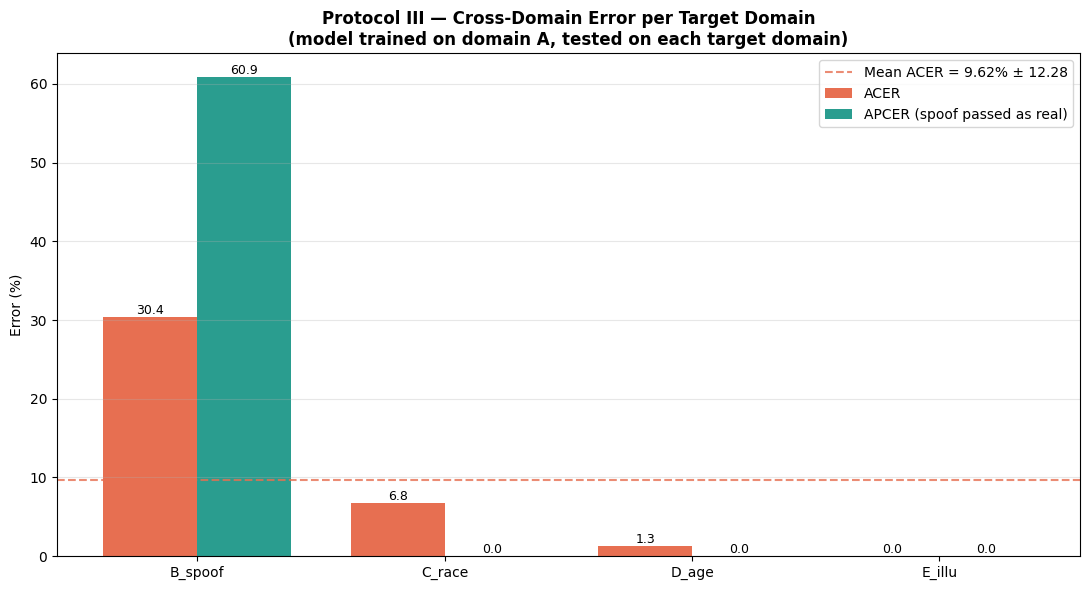


Target Domain     ACER%   APCER%   BPCER%     AUC%   TDR@1%
-----------------------------------------------------------
B_spoof           30.43    60.87     0.00    90.22  5217.39
C_race             6.76     0.00    13.51   100.00 10000.00
D_age              1.28     0.00     2.56   100.00 10000.00
E_illu             0.00     0.00     0.00   100.00 10000.00
-----------------------------------------------------------
MEAN               9.62    15.22     4.02    97.55  8804.35
STD               12.28    26.36     5.58     4.24  2070.93

Headline (cross-domain): ACER 9.62% +/- 12.28  |  TDR@1% 8804.35% +/- 2070.93

Saved readable summary table to output_siW/results/protocol_3/summary_table_protocol_3.txt
Saved summary to output_siW/results/protocol_3/test_metrics_protocol_3.json

Per-domain sample sizes (reliability indicator):
  Domain           ACER%  n_total  n_real  n_fake   note
  ----------------------------------------------------------
  B_spoof          30.43       54       8   

In [61]:
# ============================================================================
#  PROTOCOL III — Per-Domain Results Bar Chart + Summary Table + reliability
#  (uses protocol3_results — run AFTER the Protocol III training/eval.)
#  Shows ACER and APCER for each target domain (B/C/D/E) + the mean line.
#  Updated to match Protocol II's format: TDR@1% column, separate MEAN/STD
#  rows, a "Headline" summary line, and saved .txt + .json summary files.
# ============================================================================

# Safety check
assert len(protocol3_results) > 0, "protocol3_results is empty — run the training/eval first."
result_dir = PROTOCOL_CONFIG_SiW[3]['result']      # <- fixed: was CFG.PROTOCOL_CONFIG[3], wrong variable name
result_dir.mkdir(parents=True, exist_ok=True)

# ---- Keep domains in ORIGINAL order (B, C, D, E) — not sorted by ACER ----
# Matches the same choice made for Protocol II's chart: natural run order
# rather than ranked, so the order is stable and matches the training log.
res = protocol3_results
domains = [r['domain'] for r in res]
acer    = np.array([r['ACER']  * 100 for r in res])
apcer   = np.array([r['APCER'] * 100 for r in res])
bpcer   = np.array([r['BPCER'] * 100 for r in res])
auc     = np.array([r['AUC']   * 100 for r in res])
tdr     = np.array([r['TDR']   * 100 for r in res])   # <- added: your original script never printed TDR at all

mean_acer, std_acer   = acer.mean(),  acer.std()
mean_apcer            = apcer.mean()
mean_bpcer            = bpcer.mean()
mean_auc              = auc.mean()
mean_tdr, std_tdr      = tdr.mean(),   tdr.std()       # <- added: needed for the Headline line

# ---- Grouped bars: ACER and APCER side by side per domain ----
x = np.arange(len(domains))
w = 0.38
fig, ax = plt.subplots(figsize=(11, 6))
bars_acer  = ax.bar(x - w/2, acer,  w, label='ACER',  color='#e76f51')
bars_apcer = ax.bar(x + w/2, apcer, w, label='APCER (spoof passed as real)', color='#2a9d8f')

# Mean ACER reference line
ax.axhline(mean_acer, color='#e76f51', ls='--', lw=1.5, alpha=0.8,
           label=f'Mean ACER = {mean_acer:.2f}% ± {std_acer:.2f}')

# Value labels on bars
for b in bars_acer:
    ax.text(b.get_x()+b.get_width()/2, b.get_height(), f'{b.get_height():.1f}',
            ha='center', va='bottom', fontsize=9)
for b in bars_apcer:
    ax.text(b.get_x()+b.get_width()/2, b.get_height(), f'{b.get_height():.1f}',
            ha='center', va='bottom', fontsize=9)

ax.set_title('Protocol III — Cross-Domain Error per Target Domain\n'
             '(model trained on domain A, tested on each target domain)', fontweight='bold')
ax.set_ylabel('Error (%)')
ax.set_xticks(x)
ax.set_xticklabels(domains, rotation=0)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()

chart_path = result_dir / 'protocol3_per_domain_barchart.png'
plt.savefig(chart_path, dpi=120, bbox_inches='tight')
plt.show()

# ============================================================================
# ---- Print the table: now includes TDR@1%, and MEAN/STD as SEPARATE rows
#      (matches the Protocol II table format exactly) ----
# ============================================================================
table_lines = []
table_lines.append(f"{'Target Domain':<14}{'ACER%':>9}{'APCER%':>9}{'BPCER%':>9}{'AUC%':>9}{'TDR@1%':>9}")
table_lines.append('-' * 59)
for r in res:
    table_lines.append(f"{r['domain']:<14}{r['ACER']*100:>9.2f}{r['APCER']*100:>9.2f}"
                        f"{r['BPCER']*100:>9.2f}{r['AUC']*100:>9.2f}{r['TDR']:>9.2f}")
table_lines.append('-' * 59)
table_lines.append(f"{'MEAN':<14}{mean_acer:>9.2f}{mean_apcer:>9.2f}{mean_bpcer:>9.2f}{mean_auc:>9.2f}{mean_tdr:>9.2f}")
table_lines.append(f"{'STD':<14}{std_acer:>9.2f}{apcer.std():>9.2f}{bpcer.std():>9.2f}{auc.std():>9.2f}{std_tdr:>9.2f}")
table_lines.append('')
table_lines.append(f"Headline (cross-domain): ACER {mean_acer:.2f}% +/- {std_acer:.2f}  |  "
                    f"TDR@1% {mean_tdr:.2f}% +/- {std_tdr:.2f}")

print('\n' + '\n'.join(table_lines))

# ---- Save readable summary table as .txt ----
summary_table_path = result_dir / 'summary_table_protocol_3.txt'
with open(summary_table_path, 'w') as f:
    f.write('\n'.join(table_lines))
print(f"\nSaved readable summary table to {summary_table_path}")

# ---- Save summary as .json ----
summary_json_path = result_dir / 'test_metrics_protocol_3.json'
with open(summary_json_path, 'w') as f:
    json.dump({
        'per_domain': res,
        'mean_acer': float(mean_acer), 'std_acer': float(std_acer),
        'mean_apcer': float(mean_apcer),
        'mean_bpcer': float(mean_bpcer),
        'mean_auc': float(mean_auc),
        'mean_tdr': float(mean_tdr), 'std_tdr': float(std_tdr),
    }, f, indent=2)
print(f"Saved summary to {summary_json_path}")

# ============================================================================
#  Reliability indicator — videos per domain, split into live / spoof
#  (small spoof counts -> APCER is noisy; small live counts -> BPCER is noisy)
#  Unique to Protocol III — no direct equivalent needed in Protocol II, since
#  P2's test-set size is already explained by the attack-pool reliability.
#  Keeping it as-is here, just following the same
#  (now-unsorted) domain order as everything else above.
# ============================================================================
print('\nPer-domain sample sizes (reliability indicator):')
print(f"  {'Domain':<14}{'ACER%':>8}{'n_total':>9}{'n_real':>8}{'n_fake':>8}   note")
print('  ' + '-' * 58)
for r in res:
    n_total = r.get('n_videos', '?')
    n_real  = r.get('n_real', '?')
    n_fake  = r.get('n_fake', '?')
    note = ''
    if isinstance(n_fake, int) and n_fake < 30:
        note = 'few spoofs -> noisy APCER'
    elif isinstance(n_real, int) and n_real < 30:
        note = 'few live -> noisy BPCER'
    print(f"  {r['domain']:<14}{r['ACER']*100:>8.2f}{str(n_total):>9}{str(n_real):>8}{str(n_fake):>8}   {note}")

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

<hr style="border: none; height: 3px; background-color: blue;">

<div style="background-color: #FFB6C1; padding: 12px; border-radius: 6px;">
    <h2 style="margin: 0;">SiW-Mv2: Checking overall alignment/letterboxed history</h2>
</div>

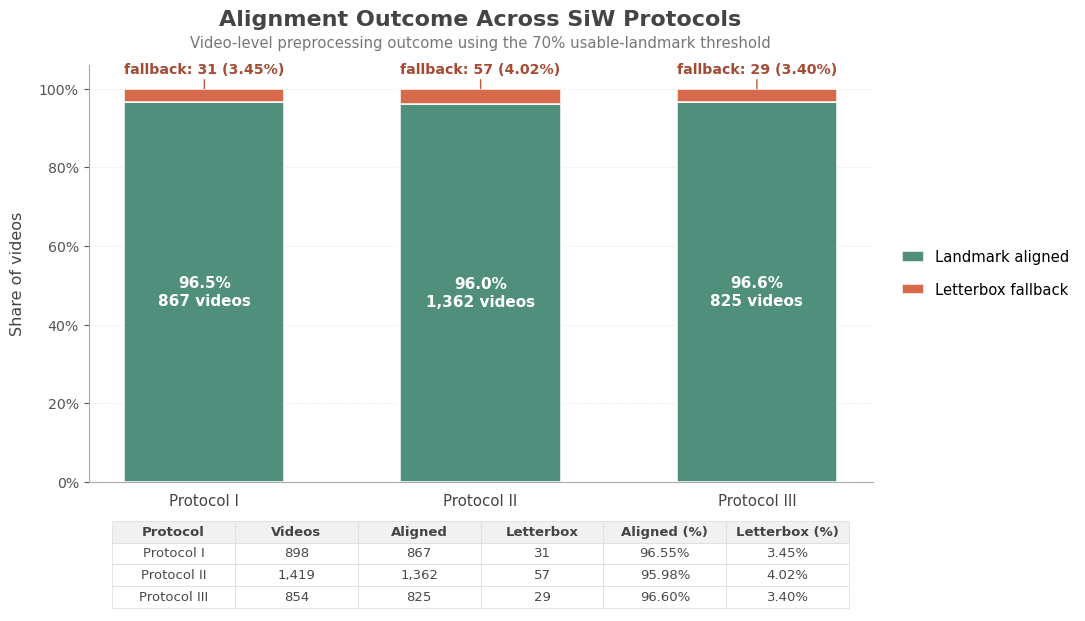

In [68]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ============================================================================
# COMBINED ALIGNMENT OUTCOME — SiW PROTOCOLS I–III
# ============================================================================

threshold = CFG.ALIGN_MIN_FRAC
threshold_pct = int(round(threshold * 100))


# ============================================================================
# Helper functions
# ============================================================================
def collect_usable_fracs_from_df(input_df, cache_dir):
    """
    Read usable_frac from cached video_meta.json for every row in a dataframe.
    Duplicate paths are removed automatically.
    """
    paths = list(dict.fromkeys(input_df["path"].tolist()))

    fracs = []
    missing = 0

    for path in paths:
        vid_id = Path(path).stem
        mp = cache_dir / "precompute" / vid_id / "video_meta.json"

        if mp.exists():
            with open(mp, "r") as f:
                fracs.append(json.load(f)["usable_frac"])
        else:
            missing += 1

    return np.asarray(fracs, dtype=float), missing


def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())


# ============================================================================
# Protocol I
# ============================================================================
p1_df = train_df_P1.copy()
p1_fracs, p1_missing = collect_usable_fracs_from_df(p1_df, CACHE_DIR_SiW)


# ============================================================================
# Protocol II
# ============================================================================
pcfg_p2 = PROTOCOL_CONFIG_SiW[2]
pcfg_p1 = PROTOCOL_CONFIG_SiW[1]

live_train_names = _read_ids(pcfg_p2["train_live_P2_80per"])
spoof_pool_names = (
    _read_ids(pcfg_p1["train_spoof_P1"]) |
    _read_ids(pcfg_p1["test_spoof_P1"])
)

df_ids = set(df["subject_id"])

live_train_df = df[
    (df["label"] == 0) &
    (df["subject_id"].isin(live_train_names & df_ids))
]

spoof_pool_df = df[
    (df["label"] == 1) &
    (df["subject_id"].isin(spoof_pool_names & df_ids))
]

p2_df = pd.concat([live_train_df, spoof_pool_df], ignore_index=True)
p2_fracs, p2_missing = collect_usable_fracs_from_df(p2_df, CACHE_DIR_SiW)


# ============================================================================
# Protocol III
# ============================================================================
pcfg_p3 = PROTOCOL_CONFIG_SiW[3]
source_ids = _read_ids(pcfg_p3["train_source_domain_A_P3"])

p3_df = df[df["subject_id"].isin(source_ids & df_ids)].copy()
p3_fracs, p3_missing = collect_usable_fracs_from_df(p3_df, CACHE_DIR_SiW)


# ============================================================================
# Summarise
# ============================================================================
protocol_names = ["Protocol I", "Protocol II", "Protocol III"]
protocol_fracs = [p1_fracs, p2_fracs, p3_fracs]
missing_counts = [p1_missing, p2_missing, p3_missing]

summary = []

for name, fracs, missing in zip(protocol_names, protocol_fracs, missing_counts):
    total = len(fracs)
    aligned = int(np.sum(fracs >= threshold))
    fallback = int(np.sum(fracs < threshold))

    aligned_pct = 100 * aligned / total if total else 0
    fallback_pct = 100 * fallback / total if total else 0

    summary.append({
        "protocol": name,
        "total": total,
        "aligned": aligned,
        "fallback": fallback,
        "aligned_pct": aligned_pct,
        "fallback_pct": fallback_pct,
        "missing": missing
    })


# ============================================================================
# Optional: only warnings, no printed summary table
# ============================================================================
for s in summary:
    if s["missing"] > 0:
        print(
            f'WARNING — {s["protocol"]}: '
            f'{s["missing"]} video(s) missing video_meta.json'
        )


# ============================================================================
# Values for plotting
# ============================================================================
aligned_pct = np.array([s["aligned_pct"] for s in summary])
fallback_pct = np.array([s["fallback_pct"] for s in summary])
x = np.arange(len(protocol_names))


# ============================================================================
# FIGURE LAYOUT
# ============================================================================
fig = plt.figure(figsize=(11.2, 7.0))

gs = fig.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[4.7, 1.05],
    hspace=0.14,
    left=0.09,
    right=0.79,   # room for legend
    top=0.86,
    bottom=0.08
)

ax = fig.add_subplot(gs[0])
ax_table = fig.add_subplot(gs[1])

bar_width = 0.58
aligned_colour = "#4F8F7B"
fallback_colour = "#D66A4A"


# ============================================================================
# Stacked bars
# ============================================================================
ax.bar(
    x,
    aligned_pct,
    width=bar_width,
    color=aligned_colour,
    edgecolor="white",
    linewidth=1.1,
    label="Landmark aligned",
    zorder=3
)

ax.bar(
    x,
    fallback_pct,
    width=bar_width,
    bottom=aligned_pct,
    color=fallback_colour,
    edgecolor="white",
    linewidth=1.1,
    label="Letterbox fallback",
    zorder=4
)


# ============================================================================
# Main labels inside aligned section
# ============================================================================
for i, s in enumerate(summary):
    ax.text(
        x[i],
        s["aligned_pct"] / 2,
        f'{s["aligned_pct"]:.1f}%\n{s["aligned"]:,} videos',
        ha="center",
        va="center",
        fontsize=11,
        fontweight="semibold",
        color="white",
        linespacing=1.25,
        zorder=5
    )


# ============================================================================
# Fallback labels — neat callouts above each bar
# ============================================================================
for i, s in enumerate(summary):
    fallback = s["fallback"]
    fallback_pct_value = s["fallback_pct"]

    if fallback > 0:
        ax.annotate(
            f'fallback: {fallback} ({fallback_pct_value:.2f}%)',
            xy=(x[i], 100),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10.2,
            fontweight="semibold",
            color="#A54B34",
            bbox=dict(
                boxstyle="round,pad=0.22",
                facecolor="white",
                edgecolor="none",
                alpha=0.96
            ),
            arrowprops=dict(
                arrowstyle="-",
                color="#B45A40",
                linewidth=1.0,
                shrinkA=0,
                shrinkB=0
            ),
            zorder=7
        )


# ============================================================================
# Axes styling
# ============================================================================
ax.set_xticks(x)
ax.set_xticklabels(protocol_names, fontsize=10.8, color="#444444")
ax.tick_params(axis="x", length=0, pad=8)

ax.set_ylim(0, 106)
ax.set_ylabel(
    "Share of videos",
    fontsize=11.5,
    fontweight="medium",
    color="#444444",
    labelpad=10
)

ax.set_yticks(np.arange(0, 101, 20))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.tick_params(axis="y", labelsize=10.2, colors="#555555")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.18, zorder=0)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#AAAAAA")
ax.spines["bottom"].set_color("#AAAAAA")
ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)


# ============================================================================
# Title + subtitle
# ============================================================================
ax.text(
    0.5,
    1.085,
    "Alignment Outcome Across SiW Protocols",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=16,
    fontweight="bold",
    color="#444444"
)

ax.text(
    0.5,
    1.035,
    f"Video-level preprocessing outcome using the {threshold_pct}% usable-landmark threshold",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10.7,
    fontweight="medium",
    color="#777777"
)


# ============================================================================
# Legend — right side
# ============================================================================
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.50),
    frameon=False,
    fontsize=10.6,
    handlelength=1.5,
    labelspacing=1.2
)


# ============================================================================
# Table below the plot
# ============================================================================
ax_table.axis("off")

column_labels = [
    "Protocol",
    "Videos",
    "Aligned",
    "Letterbox",
    "Aligned (%)",
    "Letterbox (%)"
]

table_data = []
for s in summary:
    table_data.append([
        s["protocol"],
        f'{s["total"]:,}',
        f'{s["aligned"]:,}',
        f'{s["fallback"]:,}',
        f'{s["aligned_pct"]:.2f}%',
        f'{s["fallback_pct"]:.2f}%'
    ])

table = ax_table.table(
    cellText=table_data,
    colLabels=column_labels,
    cellLoc="center",
    colLoc="center",
    loc="center",
    bbox=[0.03, 0.03, 0.94, 0.94]
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#DDDDDD")
    cell.set_linewidth(0.55)

    if row == 0:
        cell.set_facecolor("#F1F1F1")
        cell.set_text_props(weight="semibold", color="#444444")
    else:
        cell.set_facecolor("white")
        cell.set_text_props(color="#4A4A4A")


# ============================================================================
# Save + show
# ============================================================================
plt.savefig(
    "alignment_outcome_siw_protocols.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

<hr style="border: none; height: 3px; background-color: blue;">